# Jenis Serangan Verbal dan Sasarannya pada Komentar Berita Polemik KPAI vs PB Djarum

### Proyek UTS Pemrosesan Bahasa Alami Dataset Development, Anotasi Multilabel & NER

| | |
|---|---|
| **Mata kuliah** | Pemrosesan Bahasa Alami |
| **Kelompok** | NLP |
| **Anggota (NPM)** | 240712822 · 240712828 · 240712846 |
| **Dataset sumber** | *Abusive Language Detection on Indonesian Online News Comments* (`id_abusive_news_comment`, dataset No. 7 dari spesifikasi UTS) |
| **Notebook** | `KelpNLP_dataset_EDA.ipynb` (Cleaning, Normalisasi, dan Sampling Data) |

## Deskripsi Proyek

### Latar belakang
Pada 2019, **Komisi Perlindungan Anak Indonesia (KPAI)** menilai *Audisi Umum Beasiswa Bulu Tangkis* yang diselenggarakan **PB Djarum** sebagai bentuk eksploitasi anak, karena peserta anak-anak mengenakan logo merek yang identik dengan produk rokok. Akibatnya, PB Djarum menghentikan audisi tersebut. Polemik ini memicu ribuan komentar pembaca di portal berita, dan banyak di antaranya menyerang pihak lain: menghina, mengejek, menuduh, menghasut, bahkan mengutuk.

Dataset asli hanya menandai apakah sebuah komentar **abusif atau tidak**. Label itu tidak bisa menjawab pertanyaan yang lebih rinci: **serangan verbal jenis apa yang dipakai, dan siapa sasarannya?**

### Tujuan
Proyek ini mengembangkan dataset tersebut menjadi **gold dataset** untuk dua tugas NLP yang saling terhubung, dengan fokus pada **satu domain spesifik**: polemik **KPAI vs PB Djarum**.

| Tugas | Pertanyaan yang dijawab | Label / entitas |
|---|---|---|
| **A. Multilabel Text Classification** (level teks) | Serangan verbal jenis apa saja yang ada di dalam komentar? | `INSULTING` (menghina atau merendahkan martabat/kemampuan), `MOCKING` (mengejek, mencemooh, mempermalukan), `ACCUSING` (menuduh melakukan kesalahan atau tindakan tercela), `PROVOKING` (menghasut atau mendorong permusuhan/tindakan), `CURSING` (mengutuk atau mengharapkan kemalangan) |
| **B. Named Entity Recognition** (level kata) | Pihak mana yang disebut dan menjadi sasaran? | `GOV_ORG` (lembaga negara), `NONGOV_ORG` (organisasi non-pemerintah), `PERSON`, `GROUP` (kelompok orang) |

Satu komentar boleh memuat beberapa jenis serangan sekaligus, dan komentar yang tidak menyerang siapa pun tidak diberi label.

Kedua tugas saling terhubung. Multilabel menentukan **jenis serangan**, sedangkan NER mengenali **sasarannya**:

```
Teks  : Bubarkan KPAI...!!! kumpulan manusia manusia tolooool yang cari duit dari kedok perlindungan anak...
NER   : [KPAI]GOV_ORG ... [anak]GROUP
Label : [PROVOKING, INSULTING, ACCUSING]
        "Bubarkan KPAI" → menghasut · "tolooool" → menghina · "cari duit dari kedok" → menuduh
```

### Alur proyek
```
Dataset terpilih → Domain analysis → Cleaning & seleksi domain → Sampling 1.000 teks
→ Taxonomy multilabel + NER → Annotation guideline → Anotasi (Prodigy)
→ Inter-annotator agreement + adjudication → GOLD DATASET (UTS) → EDA → Streamlit dataset explorer
→ (UAS) model multilabel + NER → evaluasi → deployment
```

Notebook ini disusun mengikuti urutan spesifikasi proyek. Bagian pertama adalah **Dataset Selection dan Domain Analysis**.

In [1]:
import re
import html
import hashlib
import unicodedata
from pathlib import Path

import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()      # .../KelpNLP_UTS sebagai folder root nya 
DATASET_DIR = ROOT / "dataset"
RAW_PATH = DATASET_DIR / "KelpNLP_dataset_original.xlsx" # file dataset mentah (original) yang diunduh dari github repo
SUPPORT_DIR = DATASET_DIR / "pendukung"                         # file bukti proses (log) dari celeaning dataset, misal: baris yang dihapus, dsb
CLEAN_PATH = DATASET_DIR / "KelpNLP_dataset_clean.csv"          # output wajib: dataset hasil cleaning 
CLEANING_LOG_PATH = SUPPORT_DIR / "cleaning_log.csv"            # Log dari proses cleaning dataset, misal: baris yang dihapus, dsb
REMOVED_ROWS_PATH = SUPPORT_DIR / "removed_rows.csv"            
SUPPORT_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT    :", ROOT)
print("Dataset :", RAW_PATH.relative_to(ROOT), "| ada:", RAW_PATH.exists())
print("MD5     :", hashlib.md5(RAW_PATH.read_bytes()).hexdigest())

ROOT    : d:\Kuliah\Semester 5\NLP\KelpNLP_UTS
Dataset : dataset\KelpNLP_dataset_original.xlsx | ada: True
MD5     : d296a09277640d33d6c2ccdde7645ac1


## Cleaning Data

### Prinsip
1. **Hanya noise teknis yang diperbaiki**: encoding rusak, escape, karakter tak terlihat, markup, URL/username, dan spasi. Noise ini berasal dari proses *crawling*, bukan dari penulis komentar.
2. **Ciri tulisan komentator dipertahankan**: huruf kapital, emoji, tanda baca berulang (`!!!`), hashtag, huruf berulang (`Palsuuuu`), dan kata tersensor (`beg0`). Semuanya sinyal untuk label hinaan, ejekan, dan sejenisnya.
3. **Teks asli tidak ditimpa.** `text_raw` = teks asli, `text_clean` = hasil cleaning. Anotasi dan offset NER memakai `text_clean`, jadi teks ini di fix kan setelah tahap ini.
4. **Setiap perubahan bisa dilacak**: ID permanen, penanda `had_*` per langkah, `cleaning_log.csv`, dan `removed_rows.csv`.

### Alur
```
Langkah 1   muat dataset asli + dikasih ID permanen ANC-0001 Sebagai ID per teks 
Langkah 2   pemeriksaan awal (kriteria minimum spesifikasi)
Langkah 3–4 PERBAIKAN TEKS (jumlah baris tetap)
            C1 mojibake → C2 escape %u → C3 karakter hilang → C4 karakter tak terlihat
            → C5 Unicode NFC → C6 markup → C7 URL → C8 username → C9 spasi → C9b spasi setelah tanda baca
Langkah 5   PEMBUANGAN BARIS: C10 teks tanpa huruf → C11 duplikat
Langkah 6   pemeriksaan teks pendek
Langkah 7   SELEKSI DOMAIN KPAI vs PB Djarum (baris ditandai, tidak dibuang)
Langkah 8   statistik sebelum–sesudah
Langkah 9   validasi otomatis
Langkah 10  simpan KelpNLP_dataset_clean.csv + log

## Langkah 1 = Load dataset dan beri ID permanen
Setiap baris diberi ID `ANC-0001`, `ANC-0002`, … sesuai **urutan baris asli**. ID ini tidak pernah berubah, sehingga `text_raw`, `text_clean`, log, sampel anotasi, dan hasil anotasi selalu bisa di tracking.

Checklist = **Harus pas 3,184 karena dataset aslinya jumlah barisnya juga segitu**

In [2]:
ORIG_LABEL_NAMES = {1: "not_abusive", 2: "abusive_not_offensive", 3: "abusive_offensive"} # Label asli dari dataset, sesuai dengan yang ada di file excel

df_raw = pd.read_excel(RAW_PATH).rename(columns={"Kalimat": "text_raw", "label": "orig_label"}) # Read excel file, rename kolom agar lebih mudah dipahami
N_MISSING_TEXT = int(df_raw["text_raw"].isna().sum())         # dicatat sebelum NaN diisi
N_MISSING_LABEL = int(df_raw["orig_label"].isna().sum()) # dicatat sebelum NaN diisi
df_raw["text_raw"] = df_raw["text_raw"].fillna("").astype(str) # Isi NaN di kolom text_raw dengan string kosong, agar tidak error saat proses cleaning
df_raw.insert(0, "id", [f"ANC-{i + 1:04d}" for i in range(len(df_raw))]) # Tambahkan kolom id unik untuk setiap baris, format: ANC-0001, ANC-0002, dst
df_raw["orig_label_name"] = df_raw["orig_label"].map(ORIG_LABEL_NAMES) # Tambahkan kolom orig_label_name untuk menampilkan nama label asli sesuai dengan ORIG_LABEL_NAMES
N_ASLI = len(df_raw) # Jumlah baris asli sebelum proses cleaning

print(f"Jumlah baris: {N_ASLI:,} | kolom: {df_raw.columns.tolist()}")
df_raw.head(3)

Jumlah baris: 3,184 | kolom: ['id', 'text_raw', 'orig_label', 'orig_label_name']


,id,text_raw,orig_label,orig_label_name
0,ANC-0001,san ente aje yg unboxing Indosat. masa ente kalah ama kemenakan Prabowo...unboxing mesin atm wkwkwkwkwk,1,not_abusive
1,ANC-0002,"‚Å£‚Å£GOBLOK,ngapain beli indosat ? g ada untungnya, jaringan aja super lemot,di papua aja g ada jaringannya, mentok...",3,abusive_offensive
2,ANC-0003,Ngotot mau beli saham indosat kok jika jd presiden??? Ada apa ya??. Jika menguntungkan knp Sandi yg pengusaha & uang...,1,not_abusive


## Langkah 2 = Pemeriksaan dataset awal 

### Jenis pemeriksaan

| Kategori | Pemeriksaan | Tujuan |
|---|---|---|
| Missing values | Teks atau label bernilai `NaN` | Mengetahui data yang belum memiliki teks atau label |
| Empty text | Teks kosong atau hanya berisi spasi | Menemukan baris tanpa isi teks |
| Empty text | Teks tanpa huruf | Menemukan teks yang tidak mengandung karakter alfabet |
| Duplicate text | Duplikat persis | Menemukan teks yang sama persis |
| Duplicate text | Duplikat setelah kapitalisasi dan spasi tepi diabaikan | Menemukan teks yang secara isi tampak sama |
| Duplicate text | Kelompok duplikat dengan label bertentangan | Menemukan teks sama yang memiliki label berbeda |
| Karakter/markup | Karakter non-ASCII | Menandai karakter di luar rentang ASCII; hasilnya perlu diperiksa karena karakter non-ASCII tidak selalu berarti teks rusak |
| Karakter/markup | Escape `%uXXXX` dan escape garis miring | Menemukan pola encoding atau escape yang mungkin belum dinormalisasi |
| URL/HTML | URL, tag HTML, dan entity HTML | Mengetahui keberadaan tautan atau markup di dalam teks |
| URL/HTML | Username seperti `@nama` | Menemukan penyebutan akun |
| Spasi/encoding | Baris baru, spasi ganda, dan spasi di awal/akhir | Memeriksa inkonsistensi format teks |
| Teks terlalu pendek | Hanya satu kata atau maksimal tiga kata | Menandai teks yang mungkin kurang informatif untuk dianalisis |

In [3]:
def hitung(seri, pola, flags=0):
    # jumlah baris pada `seri` yang cocok dengan pola regex
    rx = re.compile(pola, flags)
    return int(seri.map(lambda x: bool(rx.search(x))).sum())

t0 = df_raw["text_raw"]

kunci0 = t0.str.strip().str.lower()
dup0 = kunci0.duplicated(keep=False)
konflik0 = int(df_raw[dup0].groupby(kunci0[dup0])["orig_label"].nunique().gt(1).sum())
n_kata0 = t0.str.split().str.len()

pemeriksaan_awal = pd.DataFrame([
    ("Missing values", "teks kosong (NaN)", N_MISSING_TEXT),
    ("Missing values", "label kosong (NaN)", N_MISSING_LABEL),
    ("Empty text", "teks kosong / hanya spasi", int((t0.str.strip() == "").sum())),
    ("Empty text", "teks tanpa huruf sama sekali", int((~t0.map(lambda x: any(c.isalpha() for c in x))).sum())),
    ("Duplicate text", "duplikat persis", int(t0.duplicated().sum())),
    ("Duplicate text", "duplikat (abaikan kapital & spasi tepi)", int(kunci0.duplicated().sum())),
    ("Duplicate text", "kelompok duplikat dengan label asli bertentangan", konflik0),
    ("Karakter/markup", "karakter non-ASCII (mojibake)", hitung(t0, r"[^\x00-\x7f]")),
    ("Karakter/markup", "escape %uXXXX", hitung(t0, r"%u[0-9A-Fa-f]{4}")),
    ("Karakter/markup", r"escape garis miring \/", hitung(t0, r"\\/")),
    ("URL/HTML", "URL", hitung(t0, r"https?://\S+|(?<!\w)www\.\S+")),
    ("URL/HTML", "tag atau entity HTML", hitung(t0, r"<[^>]+>|&(?:[a-zA-Z]+|#\d+);")),
    ("URL/HTML", "username (@nama)", hitung(t0, r"(?<!\w)@\w+")),
    ("Spasi/encoding", "baris baru di dalam komentar", hitung(t0, r"\n")),
    ("Spasi/encoding", "spasi ganda", hitung(t0, r"  +")),
    ("Spasi/encoding", "spasi di awal/akhir teks", int((t0 != t0.str.strip()).sum())),
    ("Teks terlalu pendek", "hanya 1 kata", int((n_kata0 == 1).sum())),
    ("Teks terlalu pendek", "≤ 3 kata", int((n_kata0 <= 3).sum())),
], columns=["kriteria minimum", "pemeriksaan", "jumlah baris"])
pemeriksaan_awal

,kriteria minimum,pemeriksaan,jumlah baris
0,Missing values,teks kosong (NaN),0
1,Missing values,label kosong (NaN),0
2,Empty text,teks kosong / hanya spasi,0
3,Empty text,teks tanpa huruf sama sekali,5
4,Duplicate text,duplikat persis,15
5,Duplicate text,duplikat (abaikan kapital & spasi tepi),20
6,Duplicate text,kelompok duplikat dengan label asli bertentangan,0
7,Karakter/markup,karakter non-ASCII (mojibake),348
8,Karakter/markup,escape %uXXXX,106
9,Karakter/markup,escape garis miring \/,9


## Langkah 3 = Fungsi cleaning
Setiap langkah adalah **satu fungsi kecil dengan satu tugas**.

| Kode | Langkah | Yang dilakukan | Alasan |
|---|---|---|---|
| **C1** | Mojibake | `üòÇ` → 😂 | Teks UTF-8 terbaca sebagai Mac Roman saat crawling. Emoji adalah sinyal ejekan/emosi, jadi **dipulihkan**. |
| **C2** | Escape `%uXXXX` | `%uD83D%uDE02` → 😂 | Escape gaya JavaScript dari halaman sumber. |
| **C3** | Karakter hilang | `�` dihapus; di tengah kata diganti spasi | Karakternya sudah hilang sejak crawling. Spasi mencegah dua kata menempel. |
| **C4** | Karakter tak terlihat | zero-width space, BOM, dll. dihapus | Tidak tampak tetapi menggeser offset. |
| **C5** | Unicode NFC | bentuk karakter diseragamkan | Satu karakter = satu representasi. |
| **C6** | Markup | tag HTML dibuang, entity dikembalikan, `\/` → `/` | Sisa format web/JSON. |
| **C7** | URL | → `[URL]` | Tautan bukan bagian opini; *placeholder* menjaga posisi. |
| **C8** | Username | `@nama` → `[USER]` | Privasi. **Pengecualian:** `@BubarkanKPAI` tidak di-*mask* karena itu slogan (hashtag yang salah simbol). |
| **C9** | Spasi | baris baru, tab, spasi ganda → satu spasi | Satu komentar satu baris, offset stabil. |
| **C9b** | Spasi setelah tanda baca | `PB.Djarum` → `PB. Djarum`, `merokok?kpai` → `merokok? kpai` | Tanda baca yang diapit huruf membuat tokenizer (Prodigy/spaCy) menggabungkan dua kata menjadi satu token, sehingga entitas seperti `KPAI` tidak bisa disorot sendiri. Hanya **ditambah satu spasi**; tanda bacanya tetap ada, angka (`1.000`) tidak kena. |

**Urutan penting:** C1–C2 paling awal (karakter `�` dan karakter tak terlihat baru muncul setelah encoding diperbaiki); C9 dan C9b paling akhir (C9b hanya menambah satu spasi, jadi tidak membuat spasi ganda baru).

**Sengaja tidak dilakukan:** *lowercase*, membuang tanda baca/emoji/hashtag, normalisasi slang, *stopword removal*, *stemming*. Semuanya mengubah teks yang dianotasi. Normalisasi dibuat nanti sebagai kolom terpisah (`text_norm`).

In [4]:
def fix_mojibake(s):
    # C1. UTF-8 yang terbaca sebagai Mac Roman dikembalikan, teks yang bukan mojibake dikembalikan apa adanya
    try:
        return s.encode("mac_roman").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s

def decode_pct_escape(s):
    # C2. '%uD83D%uDE02' -> emoji atau karakter Unicode lain
    def ganti(m):
        kode = [int(x, 16) for x in re.findall(r"%u([0-9A-Fa-f]{4})", m.group(0))]
        return "".join(map(chr, kode)).encode("utf-16", "surrogatepass").decode("utf-16", "replace")
    return re.sub(r"(?:%u[0-9A-Fa-f]{4})+", ganti, s)

def remove_lost_char(s):
    # C3. U+FFFD di tengah kata -> spasi, selain itu dihapus
    s = re.sub("(?<=\\w)\ufffd+(?=\\w)", " ", s)
    return s.replace("\ufffd", "")

def remove_invisible(s):
    # C4. zero-width space, invisible separator, BOM, dll.
    return re.sub("[\u200b-\u200f\u2060-\u2064\ufeff]", "", s)

def unicode_nfc(s):
    # C5
    return unicodedata.normalize("NFC", s)

def strip_markup(s):
    # C6. tag HTML, entity HTML, dan escape garis miring JSON
    s = re.sub(r"<[^>]+>", " ", s)
    s = re.sub(r"&(?:[a-zA-Z]+|#\d+);", lambda m: html.unescape(m.group(0)), s)
    return s.replace("\\/", "/")

def mask_url(s):
    # C7
    return re.sub(r"https?://\S+|(?<!\w)www\.\S+", "[URL]", s)

# hashtag yang dipakai di corpus: '@kata' yang sama dengan hashtag dianggap slogan, bukan akun
HASHTAG_SET = {h.lower() for s in df_raw["text_raw"] for h in re.findall(r"#(\w+)", fix_mojibake(s))}

def mask_user(s):
    # C8. '@nama' -> [USER], kecuali 'nama' adalah hashtag yang dikenal (mis. @BubarkanKPAI)
    return re.sub(r"(?<!\w)@(\w+)", lambda m: m.group(0) if m.group(1).lower() in HASHTAG_SET else "[USER]", s)

def normalize_whitespace(s):
    # C9
    return re.sub(r"\s+", " ", s).strip()

def space_after_punct(s):
    # C9b. tanda baca yang diapit huruf diberi satu spasi sesudahnya: 'PB.Djarum' -> 'PB. Djarum', 'kpai,,ga' -> 'kpai,, ga'
    # hanya di antara HURUF, sehingga angka (1.000, 2,5) dan emoji tidak tersentuh
    return re.sub(r"(?<=[A-Za-z])([.,!?;:]+)(?=[A-Za-z])", r"\1 ", s)

CLEANING_STEPS = [   # (kode, nama penanda, fungsi, aksi) — urutan = urutan eksekusi
    ("C1", "mojibake",   fix_mojibake,         "pulihkan karakter asli"),
    ("C2", "pct_escape", decode_pct_escape,    "dekode ke karakter asli (umumnya emoji)"),
    ("C3", "lost_emoji", remove_lost_char,     "hapus (spasi bila di tengah kata)"),
    ("C4", "invisible",  remove_invisible,     "hapus"),
    ("C5", "nfc",        unicode_nfc,          "seragamkan bentuk karakter"),
    ("C6", "markup",     strip_markup,         "buang tag HTML, perbaiki entity dan \\/"),
    ("C7", "url",        mask_url,             "ganti dengan [URL]"),
    ("C8", "user",       mask_user,            "ganti dengan [USER]"),
    ("C9", "whitespace", normalize_whitespace, "seragamkan menjadi satu spasi"),
    ("C9b", "punct_space", space_after_punct, "tambah spasi setelah tanda baca yang diapit huruf"),
]

def clean_text(s):
    # jalankan C1–C9b berurutan; kembalikan (teks_bersih, {had_<langkah>: True bila langkah itu mengubah teks})
    flags = {}
    for _, nama, fungsi, _ in CLEANING_STEPS:
        baru = fungsi(s)
        flags[f"had_{nama}"] = baru != s
        s = baru
    return s, flags

# uji pada satu contoh buatan yang memuat beberapa noise sekaligus
contoh_uji = "Mantap\n\n  gan %uD83D%uDE02  cek www.contoh.com @akun123 kevin\\/marcus   #BubarkanKPAI"
print("sebelum:", repr(contoh_uji))
print("sesudah:", repr(clean_text(contoh_uji)[0]))

sebelum: 'Mantap\n\n  gan %uD83D%uDE02  cek www.contoh.com @akun123 kevin\\/marcus   #BubarkanKPAI'
sesudah: 'Mantap gan 😂 cek [URL] [USER] kevin/marcus #BubarkanKPAI'


### Kenapa normalisasi tidak dilakukan di tahap cleaning?

Kami membuat metode Cleaning hanya memperbaiki **noise teknis** dari proses crawling. Normalisasi (huruf kecil, `yg` → `yang`, `goblokkk` → `goblok`, membuang tanda baca/emoji, stemming) **mengubah tulisan komentator**, jadi tidak dilakukan pada `text_clean`.

**Alasan:**
1. **`text_clean` adalah teks yang dianotasi.** Annotator harus melihat komentar seperti aslinya. Kapital (`KPAI GOBLOK!!!`), huruf berulang, emoji 😂, dan kata tersensor (`beg0`) adalah petunjuk untuk label `INSULTING` dan `MOCKING`.
2. **Offset NER harus stabil.** Span entitas disimpan sebagai posisi karakter (`start`, `end`). Kalau teks dinormalisasi setelah anotasi, posisi bergeser dan span rusak.
3. **Normalisasi bisa mengubah makna.** Kamus singkatan tidak selalu tepat untuk konteks (mis. `kpai` atau `jarum` bisa ikut "dibetulkan"), dan pelesetan nama seperti `K pea I` bisa hilang.

**Dampaknya:**
- `text_clean` masih punya banyak variasi ejaan (`gak`, `ga`, `gk`, `tdk` = *tidak*), sehingga kosakata lebih besar. Ini tidak masalah untuk anotasi.
- Normalisasi tetap dibuat nanti sebagai **kolom terpisah `text_norm`**, khusus untuk EDA kosakata dan fitur model (mis. TF-IDF). `text_clean` tidak pernah ditimpa.

## Langkah 4 = Jalankan proses cleaning code C1-C9b ke semua row


In [5]:
def contoh_langkah(s, kode, lebar=60):
    # potongan teks tepat SEBELUM dan SESUDAH langkah `kode`
    for k, _, fungsi, _ in CLEANING_STEPS:
        baru = fungsi(s)
        if k == kode:
            beda = next((i for i, (a, b) in enumerate(zip(s, baru)) if a != b), min(len(s), len(baru)))
            awal = max(0, beda - lebar // 3)
            return s[awal:awal + lebar], baru[awal:awal + lebar]
        s = baru

hasil = [clean_text(s) for s in df_raw["text_raw"]]
df_flag = df_raw.copy()
df_flag["text_clean"] = [h[0] for h in hasil]
df_flag = pd.concat([df_flag, pd.DataFrame([h[1] for h in hasil], index=df_flag.index)], axis=1)

baris_log = []
for kode, nama, _, aksi in CLEANING_STEPS:
    kena = df_flag[f"had_{nama}"]
    sebelum, sesudah = "", ""
    if kena.any():
        kandidat = df_flag.loc[kena, "text_raw"]
        panjang = kandidat[kandidat.str.len() >= 40]
        sebelum, sesudah = contoh_langkah((panjang if len(panjang) else kandidat).iloc[0], kode)
    baris_log.append({"step": kode, "name": nama, "action": aksi, "rows_affected": int(kena.sum()),
                      "n_rows_after": N_ASLI, "example_before": repr(sebelum), "example_after": repr(sesudah)})
log_teks = pd.DataFrame(baris_log)

n_berubah = int((df_flag["text_raw"] != df_flag["text_clean"]).sum())
print(f"Baris yang teksnya berubah: {n_berubah:,} dari {N_ASLI:,} ({n_berubah / N_ASLI * 100:.1f}%)")
log_teks.drop(columns="n_rows_after")

Baris yang teksnya berubah: 1,266 dari 3,184 (39.8%)


,step,name,action,rows_affected,example_before,example_after
0,C1,mojibake,pulihkan karakter asli,348,"'‚Å£‚Å£GOBLOK,ngapain beli indosat ? g ada untungnya, jaringa'","'\u2063\u2063GOBLOK,ngapain beli indosat ? g ada untungnya, jaringan aj'"
1,C2,pct_escape,dekode ke karakter asli (umumnya emoji),106,'%u2063Menjadi Atlet Berprestasi itu Mahal ! Dunia Olahraga ','\u2063Menjadi Atlet Berprestasi itu Mahal ! Dunia Olahraga dan d'
2,C3,lost_emoji,hapus (spasi bila di tengah kata),267,"'i.. 100%gak percaya,�'","'i.. 100%gak percaya,'"
3,C4,invisible,hapus,48,"'\u2063\u2063GOBLOK,ngapain beli indosat ? g ada untungnya, jaringan aj'","'GOBLOK,ngapain beli indosat ? g ada untungnya, jaringan aja '"
4,C5,nfc,seragamkan bentuk karakter,0,'',''
5,C6,markup,"buang tag HTML, perbaiki entity dan \/",9,"'akan gaji buta 0,5M \\/bln dr PAJAK hsl banting tulang n keri'","'akan gaji buta 0,5M /bln dr PAJAK hsl banting tulang n kerin'"
6,C7,url,ganti dengan [URL],2,'hread ane gan: \n\n1. https://kask.us/iCRpK \n\n2. https://kask.','hread ane gan: \n\n1. [URL] \n\n2. [URL] \n\n3. [URL]'
7,C8,user,ganti dengan [USER],1,"'@khafidz99 w bisa bilang mereka malah gak nonton itu gan, kl'","'[USER] w bisa bilang mereka malah gak nonton itu gan, klo mi'"
8,C9,whitespace,seragamkan menjadi satu spasi,540,'siden RI tahun 2500?\n','siden RI tahun 2500?'
9,C9b,punct_space,tambah spasi setelah tanda baca yang diapit huruf,434,'kemenakan Prabowo...unboxing mesin atm wkwkwkwkwk','kemenakan Prabowo... unboxing mesin atm wkwkwkwkwk'


**Penjelasan hasil C1-C9b:** perbaikan terbanyak ada di **spasi (C9)** dan **encoding (C1–C3)**. Emoji yang tadinya tampil sebagai `üòÇ` atau `%uD83D%uDE02` kembali menjadi 😂. C5 tidak mengubah baris mana pun, tetapi tetap dijalankan sebagai jaminan. C7–C8 hanya mengenai segelintir baris. C9b mengenai teks yang tanda bacanya menempel pada kata berikutnya (mis. `PB.Djarum`); isinya tidak berubah, hanya ditambah spasi.

## Langkah 5 = Buang baris yang tidak layak (C10–C11)
- **C10 — teks tanpa huruf** (mis. `:(`, `:**`): tidak ada isi yang bisa dianotasi.
- **C11 — duplikat**: dua teks dianggap sama bila `text_clean`-nya identik tanpa membedakan huruf besar/kecil. **Kemunculan pertama disimpan**; kolom `duplicate_of` mencatat ID yang dipertahankan.

Keduanya dijalankan pada teks yang **sudah bersih**, sehingga dua komentar yang hanya berbeda spasi ikut terdeteksi sebagai duplikat.

**Cek:** 3.184 → **3.157** baris.

In [6]:
tanpa_huruf = ~df_flag["text_clean"].map(lambda x: any(c.isalpha() for c in x))
buang_c10 = df_flag[tanpa_huruf].assign(reason="C10_no_letters", duplicate_of="")
d = df_flag[~tanpa_huruf]

kunci = d["text_clean"].str.lower()
duplikat = kunci.duplicated(keep="first")
id_pertama = d.groupby(kunci)["id"].transform("first")
buang_c11 = d[duplikat].assign(reason="C11_duplicate", duplicate_of=id_pertama[duplikat])

df_layak = d[~duplikat].reset_index(drop=True)
df_dibuang = pd.concat([buang_c10, buang_c11]).sort_values("id").reset_index(drop=True)
n_c10, n_c11 = len(buang_c10), len(buang_c11)

print(f"C10 teks tanpa huruf : {n_c10} baris dibuang")
print(f"C11 duplikat         : {n_c11} baris dibuang")
print(f"Jumlah baris         : {N_ASLI:,} -> {len(df_layak):,}")
df_dibuang[["id", "text_clean", "orig_label", "reason", "duplicate_of"]]

C10 teks tanpa huruf : 5 baris dibuang
C11 duplikat         : 22 baris dibuang
Jumlah baris         : 3,184 -> 3,157


,id,text_clean,orig_label,reason,duplicate_of
0,ANC-0066,:(,1,C10_no_letters,
1,ANC-0214,:**,1,C10_no_letters,
2,ANC-0438,Manusia yang mukanya lebih ruwet dari sampah alias sampah masyarakat tukang nyinyir tp gaji DPR,3,C11_duplicate,ANC-0436
3,ANC-0439,kambuh lagi Fadli.... jk ngak mau mahal lewat jalan biasa lebih lama dan jalan kurang lancar. Pesawat mahal ngeluhny...,1,C11_duplicate,ANC-0437
4,ANC-0479,Ya tinggal keluar dr jalan tol aja kalau gk mau bayar. Gt aja kok di ributin. Hahahaha,1,C11_duplicate,ANC-0475
5,ANC-0485,1111,1,C10_no_letters,
6,ANC-0639,"kalau tidak viral, lanjut terus.. sungguh keji mendoktrin anak-anak kecil dgn faham khilafah/hti, terbukti berencana...",1,C11_duplicate,ANC-0614
7,ANC-0672,1 + 1 = 0,1,C10_no_letters,
8,ANC-0716,1 + 1 = 2,1,C10_no_letters,
9,ANC-0900,yg Punya aja gak ambil pusing..... masih hobi foya foya,1,C11_duplicate,ANC-0899


## Langkah 6 = Periksa teks yang terlalu pendek
Spesifikasi meminta teks pendek **diperiksa**, bukan otomatis dibuang.

In [7]:
n_kata = df_layak["text_clean"].str.split().str.len()
pd.DataFrame({
    "jumlah baris": [int((n_kata == k).sum()) for k in (1, 2, 3)],
    "contoh": [df_layak.loc[n_kata == k, "text_clean"].head(6).tolist() for k in (1, 2, 3)],
}, index=["1 kata", "2 kata", "3 kata"])

,jumlah baris,contoh
1 kata,28,"[Palsuuuuuuuu, Blunder...., Huahuahaaaaaa, guoblog..., Setuju, matabelo]"
2 kata,66,"[Komentar tertolol, Mulutmu sampah!!!, Hadiiiirr 😂🤣😂🤣, BAduttt tttttttt, Ngeluh aja...., Yoi hahahaaha]"
3 kata,102,"[Ini bukan manusia, Telak Sekali bro, Tampang ahli naar, Manusia kufur nikmat, Otak gada isinya, telusuri motif nya]"


**Keputusan: teks pendek dipertahankan.** Komentar seperti `Mulutmu sampah!!!`, `Otak gada isinya`, atau `#gantipenguruskpai` justru memuat hinaan atau hasutan yang menjadi target label proyek. Membuangnya berdasarkan panjang saja akan menghilangkan contoh yang paling jelas. Teks pendek yang benar-benar tanpa isi sudah dibuang oleh C10.

## Langkah 7 = Seleksi domain KPAI vs PB Djarum
Proyek hanya memakai komentar dari **tiga berita** yang ada di dataset tentang polemik KPAI vs PB Djarum. Baris **tidak dibuang**, semua teks bersih tetap disimpan dan diberi penanda:

| Kolom | Isi |
|---|---|
| `thread` | nomor utas domain `1`, `2`, `3`; `0` = bukan domain |
| `in_domain` | `True` bila komentar berasal dari berita KPAI vs PB Djarum |
| `berita` | judul berita asal (hanya untuk baris domain) |

**Kenapa memakai batas baris, bukan kata kunci?** Dataset tersusun berurutan per berita. Di antara utas 1 dan 2 ada berita **SpongeBob/KPI** yang komentarnya kadang menyebut KPAI, dan banyak komentar KPAI yang sah tidak menyebut KPAI sama sekali. Karena itu batas tiap berita ditetapkan dengan **membaca baris di sekitar batas**, lalu disimpan sebagai konstanta agar hasilnya selalu sama.

In [8]:
DOMAIN_THREADS = {   # (ID awal, ID akhir, judul berita) — hasil verifikasi dengan membaca baris di sekitar batas
    1: ("ANC-1123", "ANC-1300", "KPAI Survei Ke Anak Yang Mana??"),
    2: ("ANC-1599", "ANC-2007", "#bubarkanKPAI Trending di Twitter"),
    3: ("ANC-2243", "ANC-3184", "PB Djarum Hentikan Audisi Bulutangkis"),
}
nomor_baris = lambda id_: int(id_[4:])        # 'ANC-1123' -> 1123

# Bukti batas: persentase komentar yang menyebut kata kunci tiap topik, per blok baris (dari seluruh baris asli)
POLA_BUKTI = {
    "% KPAI/Djarum/audisi": r"kpai|djarum|\bjarum\b|audisi|bulu ?tangkis|badminton",
    "% KPI/SpongeBob/sensor": r"\bkpi\b|spongebob|kartun|sensor|\bgtv\b",
    "% KPK/penyadapan/korupsi": r"\bkpk\b|penyadapan|korupsi",
}
b = [(nomor_baris(a), nomor_baris(z)) for a, z, _ in DOMAIN_THREADS.values()]
blok = [("utas 1", *b[0]), ("antara utas 1–2 (berita SpongeBob/KPI)", b[0][1] + 1, b[1][0] - 1),
        ("utas 2", *b[1]), ("antara utas 2–3 (berita KPK)", b[1][1] + 1, b[2][0] - 1), ("utas 3", *b[2])]
baris_ke = df_flag["id"].map(nomor_baris)
rekap = []
for nama, a, z in blok:
    isi = df_flag.loc[baris_ke.between(a, z), "text_clean"]
    rekap.append({"blok": nama, "rentang": f"ANC-{a:04d} – ANC-{z:04d}", "baris": len(isi),
                  **{k: round(hitung(isi, p, re.I) / len(isi) * 100, 1) for k, p in POLA_BUKTI.items()}})
pd.DataFrame(rekap).set_index("blok")

,rentang,baris,% KPAI/Djarum/audisi,% KPI/SpongeBob/sensor,% KPK/penyadapan/korupsi
blok,,,,,
utas 1,ANC-1123 – ANC-1300,178,62.9,0.0,0.0
antara utas 1–2 (berita SpongeBob/KPI),ANC-1301 – ANC-1598,298,11.7,55.7,1.0
utas 2,ANC-1599 – ANC-2007,409,78.0,0.5,0.0
antara utas 2–3 (berita KPK),ANC-2008 – ANC-2242,235,0.0,0.0,38.3
utas 3,ANC-2243 – ANC-3184,942,74.5,1.8,0.3


**Penjelasan:** di tiga utas domain mayoritas komentar menyebut KPAI/Djarum/audisi. Di blok antara utas 1 dan 2 yang dominan justru KPI/SpongeBob/sensor, dan di blok antara utas 2 dan 3 yang muncul topik KPK. Batasnya tegas, jadi dua blok itu dikeluarkan dari domain walaupun sebagian komentarnya menyebut KPAI.

In [9]:
def assign_domain(df):
    out = df.copy()
    baris = out["id"].map(nomor_baris)
    out["thread"] = 0
    out["berita"] = ""
    for no, (awal, akhir, judul) in DOMAIN_THREADS.items():
        di_utas = baris.between(nomor_baris(awal), nomor_baris(akhir))
        out.loc[di_utas, "thread"] = no
        out.loc[di_utas, "berita"] = judul
    out["in_domain"] = out["thread"] > 0
    return out

df_clean = assign_domain(df_layak)
N_DOMAIN = int(df_clean["in_domain"].sum())
per_utas = (df_clean[df_clean["in_domain"]].groupby("thread")
            .agg(berita=("berita", "first"), dari=("id", "first"), sampai=("id", "last"), jumlah=("id", "size")))
per_utas["% dari domain"] = (per_utas["jumlah"] / N_DOMAIN * 100).round(1)
print(f"Corpus domain: {N_DOMAIN:,} teks | di luar domain (tetap disimpan): {len(df_clean) - N_DOMAIN:,}")
per_utas

Corpus domain: 1,515 teks | di luar domain (tetap disimpan): 1,642


,berita,dari,sampai,jumlah,% dari domain
thread,,,,,
1,KPAI Survei Ke Anak Yang Mana??,ANC-1123,ANC-1300,178,11.7
2,#bubarkanKPAI Trending di Twitter,ANC-1599,ANC-2007,400,26.4
3,PB Djarum Hentikan Audisi Bulutangkis,ANC-2243,ANC-3184,937,61.8


## Langkah 8 = Membuat Statistik sebelum dan sesudah cleaning
Tujuannya memastikan cleaning **tidak mengubah karakter data**, dan corpus domain memenuhi syarat **minimal 800 teks unik**.

In [10]:
display(pd.DataFrame([
    ("Dataset asli", N_ASLI, "—"),
    ("C1–C9b perbaikan teks", N_ASLI, f"{n_berubah:,} teks diperbaiki, jumlah baris tetap"),
    ("C10 buang teks tanpa huruf", N_ASLI - n_c10, f"−{n_c10} baris"),
    ("C11 buang duplikat → dataset bersih", len(df_clean), f"−{n_c11} baris"),
    ("Seleksi domain KPAI vs PB Djarum", N_DOMAIN, f"{len(df_clean) - N_DOMAIN:,} teks lain tetap disimpan (in_domain = False)"),
], columns=["tahap", "jumlah teks", "keterangan"]))

def dist(d):
    vc = d["orig_label"].value_counts().sort_index()
    return vc.astype(str) + " (" + (vc / len(d) * 100).round(1).astype(str) + "%)"
df_domain = df_clean[df_clean["in_domain"]]
tabel_label = pd.DataFrame({f"asli ({N_ASLI:,})": dist(df_raw), f"bersih ({len(df_clean):,})": dist(df_clean),
                            f"domain ({N_DOMAIN:,})": dist(df_domain)})
tabel_label.index = [f"{k} {ORIG_LABEL_NAMES[k]}" for k in tabel_label.index]
display(tabel_label)

def panjang(t):
    n = t.str.split().str.len()
    return {"rata-rata kata": round(n.mean(), 1), "median": int(n.median()), "min": int(n.min()), "maks": int(n.max())}
pd.DataFrame({"asli (text_raw)": panjang(df_raw["text_raw"]), "bersih (text_clean)": panjang(df_clean["text_clean"]),
              "domain (text_clean)": panjang(df_domain["text_clean"])}).T

,tahap,jumlah teks,keterangan
0,Dataset asli,3184,—
1,C1–C9b perbaikan teks,3184,"1,266 teks diperbaiki, jumlah baris tetap"
2,C10 buang teks tanpa huruf,3179,−5 baris
3,C11 buang duplikat → dataset bersih,3157,−22 baris
4,Seleksi domain KPAI vs PB Djarum,1515,"1,642 teks lain tetap disimpan (in_domain = False)"


,"asli (3,184)","bersih (3,157)","domain (1,515)"
1 not_abusive,2789 (87.6%),2764 (87.6%),1355 (89.4%)
2 abusive_not_offensive,110 (3.5%),109 (3.5%),30 (2.0%)
3 abusive_offensive,285 (9.0%),284 (9.0%),130 (8.6%)


,rata-rata kata,median,min,maks
asli (text_raw),19.9,14.0,1.0,486.0
bersih (text_clean),20.2,14.0,1.0,486.0
domain (text_clean),23.1,17.0,1.0,486.0


**Penjelasan:**
- Hanya sebagian kecil baris yang dibuang, dan **proporsi label asli nyaris tidak berubah**. Cleaning tidak menggeser distribusi data.
- **Panjang teks tidak berubah berarti**, karena yang diperbaiki hanya karakter teknis.
- **Corpus domain jauh di atas syarat 800 teks**, jadi ada ruang untuk sampling dan untuk menyisihkan teks yang nanti tidak bisa dianotasi.

## Langkah 9 = Validasi otomatis
Jika satu pengujian gagal, notebook berhenti (`assert`), sehingga file yang tersimpan selalu lolos semua pengujian.

In [11]:
tc = df_clean["text_clean"]
raw_layak = df_clean["text_raw"]
sumber = pd.read_excel(RAW_PATH)["Kalimat"].astype(str)
sumber_per_id = sumber.iloc[df_clean["id"].map(nomor_baris).values - 1].values

SISA_NOISE = {
    "mojibake / karakter hilang": "[\ufffd]|ÔøΩ|üò",
    "escape %uXXXX": r"%u[0-9A-Fa-f]{4}",
    "karakter tak terlihat": "[\u200b-\u200f\u2060-\u2064\ufeff]",
    "tag HTML": r"<[^>]+>",
    "escape garis miring": r"\\/",
    "URL belum di-mask": r"https?://|(?<!\w)www\.\S",
    "baris baru / tab / spasi ganda": r"[\n\t\r\xa0]|  ",
    "tanda baca menempel di antara huruf (C9b)": r"[A-Za-z][.,!?;:]+[A-Za-z]",
}
def jumlah_cocok(teks, pola, flags=re.I):
    return int(teks.map(lambda x: len(re.findall(pola, x, flags))).sum())
# ciri tulisan dibandingkan pada baris tanpa escape %u, URL, dan username (ketiganya sengaja diganti)
biasa = ~(df_clean["had_pct_escape"] | df_clean["had_url"] | df_clean["had_user"])

uji = {
    "ID unik": df_clean["id"].is_unique,
    "tidak ada nilai kosong": not df_clean[["id", "text_raw", "text_clean", "orig_label"]].isna().any().any(),
    "tidak ada teks tanpa huruf": bool(tc.map(lambda x: any(c.isalpha() for c in x)).all()),
    "tidak ada duplikat (abaikan kapital)": not tc.str.lower().duplicated().any(),
    "tidak ada spasi di awal/akhir": bool((tc == tc.str.strip()).all()),
    **{f"tidak ada sisa: {k}": hitung(tc, p) == 0 for k, p in SISA_NOISE.items()},
    "text_raw sama persis dengan file sumber": bool((raw_layak.values == sumber_per_id).all()),
    "baris bersih + baris dibuang = baris asli": len(df_clean) + len(df_dibuang) == N_ASLI,
    "cleaning ulang tidak mengubah text_clean": bool((tc.map(lambda x: clean_text(x)[0]) == tc).all()),
    "jumlah sebutan 'kpai' tidak berubah": jumlah_cocok(raw_layak, "kpai") == jumlah_cocok(tc, "kpai"),
    "jumlah sebutan 'djarum' tidak berubah": jumlah_cocok(raw_layak, "djarum") == jumlah_cocok(tc, "djarum"),
    "jumlah hashtag tidak berubah": jumlah_cocok(raw_layak, r"#\w+") == jumlah_cocok(tc, r"#\w+"),
    "jumlah huruf kapital tidak berubah": jumlah_cocok(raw_layak[biasa], "[A-Z]", 0) == jumlah_cocok(tc[biasa], "[A-Z]", 0),
    "jumlah tanda seru & tanya tidak berubah": jumlah_cocok(raw_layak[biasa], r"[!?]") == jumlah_cocok(tc[biasa], r"[!?]"),
    "corpus domain ≥ 800 teks": N_DOMAIN >= 800,
}
display(pd.DataFrame({"hasil": ["✅ lolos" if v else "❌ GAGAL" for v in uji.values()]}, index=list(uji)))
assert all(uji.values()), "Ada pengujian yang gagal — periksa tabel di atas."
print(f"Semua {len(uji)} pengujian lolos.")

,hasil
ID unik,✅ lolos
tidak ada nilai kosong,✅ lolos
tidak ada teks tanpa huruf,✅ lolos
tidak ada duplikat (abaikan kapital),✅ lolos
tidak ada spasi di awal/akhir,✅ lolos
tidak ada sisa: mojibake / karakter hilang,✅ lolos
tidak ada sisa: escape %uXXXX,✅ lolos
tidak ada sisa: karakter tak terlihat,✅ lolos
tidak ada sisa: tag HTML,✅ lolos
tidak ada sisa: escape garis miring,✅ lolos


Semua 22 pengujian lolos.


## Langkah 10 = Simpan hasil

| File | Isi |
|---|---|
| `dataset/KelpNLP_dataset_clean.csv` | semua teks bersih + penanda domain (output wajib) |
| `dataset/pendukung/cleaning_log.csv` | jumlah baris terdampak tiap langkah + contoh sebelum/sesudah |
| `dataset/pendukung/removed_rows.csv` | baris yang dibuang, alasan, dan ID pasangannya bila duplikat |

Kolom `KelpNLP_dataset_clean.csv`: `id`, `text_raw`, `text_clean`, `orig_label`, `orig_label_name`, `source`, `year`, `language`, `in_domain`, `thread`, `berita`, `n_chars`, `n_words`, tujuh penanda `had_*`, dan `annotation_status`.

CSV disimpan sebagai **UTF-8 dengan BOM** supaya emoji tampil benar di Excel.

In [12]:
df_clean["source"] = "kompas/kaskus/detik"     # sumber per baris tidak tercatat di dataset asli
df_clean["year"] = 2019
df_clean["language"] = "id"
df_clean["n_chars"] = df_clean["text_clean"].str.len()
df_clean["n_words"] = df_clean["text_clean"].str.split().str.len()
df_clean["annotation_status"] = "not_annotated"

CLEAN_COLS = ["id", "text_raw", "text_clean", "orig_label", "orig_label_name", "source", "year", "language",
              "in_domain", "thread", "berita", "n_chars", "n_words",
              "had_mojibake", "had_pct_escape", "had_lost_emoji", "had_invisible", "had_markup", "had_url", "had_user",
              "annotation_status"]
df_clean = df_clean[CLEAN_COLS]

contoh_c10 = buang_c10["text_clean"]
contoh_c11 = buang_c11["text_clean"]
cleaning_log = pd.concat([log_teks, pd.DataFrame([
    {"step": "C10", "name": "no_letters", "action": "buang baris", "rows_affected": n_c10,
     "n_rows_after": N_ASLI - n_c10, "example_before": repr(contoh_c10.iloc[0]) if n_c10 else "", "example_after": "(dibuang)"},
    {"step": "C11", "name": "duplicate", "action": "buang baris (simpan kemunculan pertama)", "rows_affected": n_c11,
     "n_rows_after": len(df_clean), "example_before": repr(contoh_c11.iloc[0][:60]) if n_c11 else "", "example_after": "(dibuang)"},
    {"step": "D1", "name": "select_domain", "action": "tandai in_domain / thread / berita (baris tidak dibuang)",
     "rows_affected": N_DOMAIN, "n_rows_after": len(df_clean),
     "example_before": "; ".join(f"utas {k}: {a}–{z}" for k, (a, z, _) in DOMAIN_THREADS.items()),
     "example_after": f"{N_DOMAIN} teks in_domain"},
])], ignore_index=True)

df_clean.to_csv(CLEAN_PATH, index=False, encoding="utf-8-sig")
cleaning_log.to_csv(CLEANING_LOG_PATH, index=False, encoding="utf-8-sig")
df_dibuang[["id", "text_raw", "text_clean", "orig_label", "reason", "duplicate_of"]].to_csv(
    REMOVED_ROWS_PATH, index=False, encoding="utf-8-sig")

# baca ulang untuk memastikan isi file utuh
df_cek = pd.read_csv(CLEAN_PATH, encoding="utf-8-sig", keep_default_na=False)
assert df_cek.shape == df_clean.shape and (df_cek["text_clean"].values == df_clean["text_clean"].values).all()
for p in (CLEAN_PATH, CLEANING_LOG_PATH, REMOVED_ROWS_PATH):
    print(f"tersimpan: {str(p.relative_to(ROOT)):42s} {p.stat().st_size / 1024:8.1f} KB")
print(f"\n{CLEAN_PATH.name}: {df_clean.shape[0]:,} baris × {df_clean.shape[1]} kolom | in_domain = {N_DOMAIN:,}")
print("SHA-256 text_clean (untuk mengecek hasil yang sama di komputer lain):",
      hashlib.sha256("\n".join(df_clean["id"] + "\t" + df_clean["text_clean"]).encode("utf-8")).hexdigest())

tersimpan: dataset\KelpNLP_dataset_clean.csv            1242.2 KB
tersimpan: dataset\pendukung\cleaning_log.csv              1.9 KB
tersimpan: dataset\pendukung\removed_rows.csv              4.9 KB

KelpNLP_dataset_clean.csv: 3,157 baris × 21 kolom | in_domain = 1,515
SHA-256 text_clean (untuk mengecek hasil yang sama di komputer lain): 65ab5e50e5e04424c72cc655b88a603bd2e47a5aa0dd36c9e0ec37344bd4c2af


## Ringkasan Cleaning

In [13]:
display(Markdown(f'''
| Hal | Hasil |
|---|---|
| Dataset asli | **{N_ASLI:,}** baris, tanpa missing value |
| Teks yang diperbaiki (C1–C9b) | **{n_berubah:,}** baris ({n_berubah / N_ASLI * 100:.1f}%), terutama encoding dan spasi |
| Baris dibuang | **{n_c10 + n_c11}** baris: {n_c10} tanpa huruf (C10) + {n_c11} duplikat (C11) |
| Dataset bersih | **{len(df_clean):,}** teks unik → `{CLEAN_PATH.name}` |
| Corpus domain KPAI vs PB Djarum | **{N_DOMAIN:,}** teks: {", ".join(f"utas {k} = {v:,}" for k, v in per_utas["jumlah"].items())} |
| Syarat minimal 800 teks unik | **terpenuhi** |
| Validasi | **{len(uji)}** pengujian lolos |
'''))


| Hal | Hasil |
|---|---|
| Dataset asli | **3,184** baris, tanpa missing value |
| Teks yang diperbaiki (C1–C9b) | **1,266** baris (39.8%), terutama encoding dan spasi |
| Baris dibuang | **27** baris: 5 tanpa huruf (C10) + 22 duplikat (C11) |
| Dataset bersih | **3,157** teks unik → `KelpNLP_dataset_clean.csv` |
| Corpus domain KPAI vs PB Djarum | **1,515** teks: utas 1 = 178, utas 2 = 400, utas 3 = 937 |
| Syarat minimal 800 teks unik | **terpenuhi** |
| Validasi | **22** pengujian lolos |


# Jenis Serangan Verbal dan Sasarannya pada Komentar Berita Polemik KPAI vs PB Djarum

### Proyek UTS Pemrosesan Bahasa Alami Dataset Development, Anotasi Multilabel & NER

| | |
|---|---|
| **Mata kuliah** | Pemrosesan Bahasa Alami |
| **Kelompok** | NLP |
| **Anggota (NPM)** | 240712822 · 240712828 · 240712846 |
| **Dataset sumber** | *Abusive Language Detection on Indonesian Online News Comments* (`id_abusive_news_comment`, dataset No. 7 dari spesifikasi UTS) |
| **Notebook** | `KelpNLP_dataset_EDA.ipynb` (Cleaning, Normalisasi, dan Sampling Data) |

## Deskripsi Proyek

### Latar belakang
Pada 2019, **Komisi Perlindungan Anak Indonesia (KPAI)** menilai *Audisi Umum Beasiswa Bulu Tangkis* yang diselenggarakan **PB Djarum** sebagai bentuk eksploitasi anak, karena peserta anak-anak mengenakan logo merek yang identik dengan produk rokok. Akibatnya, PB Djarum menghentikan audisi tersebut. Polemik ini memicu ribuan komentar pembaca di portal berita, dan banyak di antaranya menyerang pihak lain: menghina, mengejek, menuduh, menghasut, bahkan mengutuk.

Dataset asli hanya menandai apakah sebuah komentar **abusif atau tidak**. Label itu tidak bisa menjawab pertanyaan yang lebih rinci: **serangan verbal jenis apa yang dipakai, dan siapa sasarannya?**

### Tujuan
Proyek ini mengembangkan dataset tersebut menjadi **gold dataset** untuk dua tugas NLP yang saling terhubung, dengan fokus pada **satu domain spesifik**: polemik **KPAI vs PB Djarum**.

| Tugas | Pertanyaan yang dijawab | Label / entitas |
|---|---|---|
| **A. Multilabel Text Classification** (level teks) | Serangan verbal jenis apa saja yang ada di dalam komentar? | `INSULTING` (menghina atau merendahkan martabat/kemampuan), `MOCKING` (mengejek, mencemooh, mempermalukan), `ACCUSING` (menuduh melakukan kesalahan atau tindakan tercela), `PROVOKING` (menghasut atau mendorong permusuhan/tindakan), `CURSING` (mengutuk atau mengharapkan kemalangan) |
| **B. Named Entity Recognition** (level kata) | Pihak mana yang disebut dan menjadi sasaran? | `GOV_ORG` (lembaga negara), `NONGOV_ORG` (organisasi non-pemerintah), `PERSON`, `GROUP` (kelompok orang) |

Satu komentar boleh memuat beberapa jenis serangan sekaligus, dan komentar yang tidak menyerang siapa pun tidak diberi label.

Kedua tugas saling terhubung. Multilabel menentukan **jenis serangan**, sedangkan NER mengenali **sasarannya**:

```
Teks  : Bubarkan KPAI...!!! kumpulan manusia manusia tolooool yang cari duit dari kedok perlindungan anak...
NER   : [KPAI]GOV_ORG ... [anak]GROUP
Label : [PROVOKING, INSULTING, ACCUSING]
        "Bubarkan KPAI" → menghasut · "tolooool" → menghina · "cari duit dari kedok" → menuduh
```

### Alur notebook normalisasi
```
A. NORMALISASI → kolom text_norm
   N0 muat data bersih + cek kode enkripsinya       
   N1 daftar proteksi (kata yang tidak boleh diubah)
   N2 audit dua kamus bawaan dataset
   N3 bangun kamus normalisasi final
   N4 fungsi normalisasi
   N5 jalankan + log perubahan
   N6 cek contoh sebelum → sesudah
   N7 validasi + simpan
```

Notebook ini disusun mengikuti urutan spesifikasi proyek. Bagian kedua adalah **Normalisasi dan ambil sampling untuk anotasi**.
File yang dihasilkan adalah text_norm di dataset clean yang sudah ada dan kamus normalisasi, dan riwayat normalisasi

## Langkah 0 = Cek data clean

In [14]:
import re
import json
import hashlib
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATASET_DIR = ROOT / "dataset"
CLEAN_PATH = DATASET_DIR / "KelpNLP_dataset_clean.csv"
SHA_CLEAN = "65ab5e50e5e04424c72cc655b88a603bd2e47a5aa0dd36c9e0ec37344bd4c2af"

df = pd.read_csv(CLEAN_PATH, encoding="utf-8-sig", keep_default_na=False) #baca dataset hasil cleaning
df = df.drop(columns="text_norm", errors="ignore")   # text_norm selalu dibuat ulang di notebook ini

sidik = hashlib.sha256("\n".join(df["id"] + "\t" + df["text_clean"]).encode("utf-8")).hexdigest() # buat enkripsi SHA-256 dari kolom id dan text_clean
print("ukuran   :", df.shape)
print("in_domain:", int(df["in_domain"].sum()))
print("SHA-256  :", sidik)
assert sidik == SHA_CLEAN, "text_clean berbeda dari hasil cleaning — jalankan ulang KelpNLP_cleaning.ipynb" #Kalau beda, jalankan ulang KelpNLP_cleaning.ipynb untuk membersihkan dataset.

ukuran   : (3157, 21)
in_domain: 1515
SHA-256  : 65ab5e50e5e04424c72cc655b88a603bd2e47a5aa0dd36c9e0ec37344bd4c2af


## Langkah 1 (Normalisasi) = Daftar proteksi apa saja yang tidak boleh diubah pada saat normalisasi
Normalisasi tidak boleh merusak calon **entitas NER** atau **sinyal label**. Lima kelompok dilindungi: nama pihak (kata), nama pihak (frasa), tagar dan sebutan akun, placeholder `[URL]`/`[USER]`, serta kata tersensor atau bercampur angka (`beg0`, `b*rak`). Daftar ditulis dalam huruf kecil karena teks dikecilkan sebelum dicocokkan. Sel berikut juga menghitung berapa kali tiap istilah muncul, sebagai bukti bahwa daftar ini memang relevan dengan corpus.

In [15]:
from collections import Counter

# ---------- daftar proteksi (huruf kecil) ----------
PROTECTED = {
    "GOV_ORG":    "kpai kapai kpi kpk dpr dprd mpr pemerintah kemenpora menpora komnas kemensos pppa kpu polri",
    "NONGOV_ORG": "pb djarum jarum pt pbsi sampoerna foundation bca bloomberg uii hti pks",
    "PERSON":     "susanto sitti siti jokowi kevin marcus susi susanti hartono taufik hidayat prabowo sandi fadli anies ahok sby",
}
PROTECTED_WORDS = {kata for daftar in PROTECTED.values() for kata in daftar.split()}
PROTECTED_PHRASES = ["komisi perlindungan anak indonesia", "djarum foundation", "pb djarum", "pt djarum",
                     "komnas pa", "komnas ham", "lentera anak", "susi susanti", "k pea i"]   # 'k pea i' = pelesetan KPAI

# satu "kata" = deretan huruf/angka, boleh tersambung tanda * agar bentuk sensor (b*rak) tetap satu token
POLA_KATA = r"\w+(?:\*+\w+)*"

def batas_kata(istilah): # Fungsi untuk membuat pola regex yang mencocokkan istilah sebagai kata/frasa utuh, bukan bagian dari kata lain
    # pola untuk mencocokkan istilah sebagai kata/frasa utuh, bukan bagian dari kata lain
    return r"(?<![\w*])" + re.escape(istilah) + r"(?![\w*])"

def jumlah_istilah(teks, istilah): # Fungsi untuk menghitung jumlah kemunculan istilah dalam teks
    pola = re.compile(batas_kata(istilah))
    return int(teks.map(lambda x: len(pola.findall(x))).sum())

teks_kecil = df["text_clean"].str.lower()
FREKUENSI_TOKEN = Counter(tok for s in teks_kecil for tok in re.findall(POLA_KATA, s))

rekap = [(kel, k, jumlah_istilah(teks_kecil, k)) for kel, daftar in PROTECTED.items() for k in daftar.split()]
rekap += [("frasa", f, jumlah_istilah(teks_kecil, f)) for f in PROTECTED_PHRASES]
rekap_proteksi = pd.DataFrame(rekap, columns=["kelompok", "istilah", "muncul di corpus"])

sensor = sorted(t for t in FREKUENSI_TOKEN
                if not t.isalpha() and not t.isdigit() and not re.fullmatch(r"[a-z]{2,}[2²][a-z]*", t))
print(f"Kata diproteksi : {len(PROTECTED_WORDS)} | frasa diproteksi: {len(PROTECTED_PHRASES)}")
print("Hashtag di corpus           :", sum(len(re.findall(r"#\w+", s)) for s in teks_kecil))
print("Placeholder [url]/[user]    :", sum(s.count("[url]") + s.count("[user]") for s in teks_kecil))
print("Token sensor/campuran angka :", len(sensor), "jenis, contoh:", [t for t in sensor if "*" in t][:5])
rekap_proteksi.sort_values("muncul di corpus", ascending=False).head(12)

Kata diproteksi : 44 | frasa diproteksi: 9
Hashtag di corpus           : 78
Placeholder [url]/[user]    : 5
Token sensor/campuran angka : 96 jenis, contoh: ['a**k', 'a**ok', 'b*brok', 'b*d*h', 'b*kep']


,kelompok,istilah,muncul di corpus
0,GOV_ORG,kpai,1135
16,NONGOV_ORG,djarum,561
15,NONGOV_ORG,pb,281
46,frasa,pb djarum,211
3,GOV_ORG,kpk,173
2,GOV_ORG,kpi,124
30,PERSON,jokowi,108
17,NONGOV_ORG,jarum,91
7,GOV_ORG,pemerintah,86
25,NONGOV_ORG,hti,72


## Langkah 2 (Normalisasi) = Audit kamus bawaan dataset
Repo dataset dari github menyertakan dua kamus singkatan/salah ketik (`Acronym Words and Typos .xlsx` dan `kumpulan_singkatan_dan_kata_dasar.xls`). Sebelum dipakai, isinya diperiksa dari tiga sisi yaitu **kualitas entri**, **entri yang justru merusak teks bila diterapkan**, dan **cakupan terhadap kata informal yang sering muncul di corpus.**

In [16]:
KAMUS_DIR = DATASET_DIR / "pendukung" / "kamus_bawaan"
KAMUS_SUMBER = {
    "acronym_words_typos": KAMUS_DIR / "Acronym Words and Typos .xlsx",
    "kumpulan_singkatan":  KAMUS_DIR / "kumpulan_singkatan_dan_kata_dasar.xls",   # perlu library xlrd
}

def load_source_dicts():
    # gabungkan dua kamus bawaan apa adanya (belum disaring)
    a = pd.read_excel(KAMUS_SUMBER["acronym_words_typos"]).fillna("").astype(str)
    a.columns = ["kata", "kata_baku"]
    a["sumber"] = "acronym_words_typos"
    b = pd.read_excel(KAMUS_SUMBER["kumpulan_singkatan"], header=None).fillna("").astype(str)   # tanpa baris judul
    b.columns = ["kata", "kata_baku"]
    b["sumber"] = "kumpulan_singkatan"
    d = pd.concat([a, b], ignore_index=True)
    d["kata"] = d["kata"].str.strip().str.lower()
    d["kata_baku"] = d["kata_baku"].str.strip().str.lower().str.strip("'")   # nilai "'" = kosong di kamus asli
    return d

kamus_asli = load_source_dicts()
ada_nilai = kamus_asli[kamus_asli["kata_baku"] != ""]
nilai_per_kata = ada_nilai.groupby("kata")["kata_baku"].agg(lambda x: " / ".join(sorted(set(x))))
konflik = nilai_per_kata[nilai_per_kata.str.contains(" / ", regex=False)]

# (1) kualitas entri
display(pd.DataFrame([
    ("jumlah entri (dua kamus)", len(kamus_asli)),
    ("nilai kosong", int((kamus_asli["kata_baku"] == "").sum())),
    ("kata bukan satu kata alfabet", int((~kamus_asli["kata"].map(lambda k: bool(re.fullmatch(r"[a-z]+", k)))).sum())),
    ("kata sama dengan nilainya", int((kamus_asli["kata"] == kamus_asli["kata_baku"]).sum())),
    ("kata tercatat lebih dari sekali", int(kamus_asli["kata"].duplicated().sum())),
    ("kata dengan dua nilai bertentangan", len(konflik)),
    ("kata kamus yang termasuk daftar proteksi", int(kamus_asli["kata"].isin(PROTECTED_WORDS).sum())),
], columns=["pemeriksaan", "jumlah"]))

# (2) contoh entri yang merusak teks bila kamus dipakai apa adanya
CONTOH_MASALAH = {
    "dpr": "nama lembaga (DPR)",
    "pt": "PT Djarum = perseroan terbatas",
    "pp": "PP 109 = peraturan pemerintah",
    "sd": "umumnya 'anak SD'",
    "sby": "bisa Surabaya, bisa SBY (nama orang)",
    "ts": "di Kaskus = thread starter",
    "krn": "dua nilai bertentangan",
    "pd": "di corpus berarti 'pada'",
    "tereksploitasi": "sudah kata baku; nilainya keliru",
}
display(pd.DataFrame([(k, nilai_per_kata.get(k, ""), FREKUENSI_TOKEN.get(k, 0), c) for k, c in CONTOH_MASALAH.items()],
                     columns=["kata", "nilai di kamus bawaan", "muncul di corpus", "catatan"]))

# (3) cakupan: kata informal yang sering muncul tetapi tidak ada di kamus
INFORMAL_UMUM = ["aja", "ga", "gak", "kalo", "udah", "klo", "tuh", "pake", "emang", "tau", "gitu", "lu", "nggak", "org"]
pd.DataFrame([(w, FREKUENSI_TOKEN.get(w, 0), "ada" if w in nilai_per_kata.index else "TIDAK ADA") for w in INFORMAL_UMUM],
             columns=["kata informal", "muncul di corpus", "di kamus bawaan"]).sort_values("muncul di corpus", ascending=False)

C:\Users\Edward\AppData\Local\Temp\ipykernel_1552\3024201880.py:12: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  b = pd.read_excel(KAMUS_SUMBER["kumpulan_singkatan"], header=None).fillna("").astype(str)   # tanpa baris judul


,pemeriksaan,jumlah
0,jumlah entri (dua kamus),912
1,nilai kosong,44
2,kata bukan satu kata alfabet,16
3,kata sama dengan nilainya,24
4,kata tercatat lebih dari sekali,102
5,kata dengan dua nilai bertentangan,8
6,kata kamus yang termasuk daftar proteksi,9


,kata,nilai di kamus bawaan,muncul di corpus,catatan
0,dpr,dapur,66,nama lembaga (DPR)
1,pt,patungan,12,PT Djarum = perseroan terbatas
2,pp,pulang pergi,9,PP 109 = peraturan pemerintah
3,sd,sampai dengan,13,umumnya 'anak SD'
4,sby,surabaya,10,"bisa Surabaya, bisa SBY (nama orang)"
5,ts,tersebut,5,di Kaskus = thread starter
6,krn,kamu / karena,46,dua nilai bertentangan
7,pd,padahal,13,di corpus berarti 'pada'
8,tereksploitasi,bah,3,sudah kata baku; nilainya keliru


,kata informal,muncul di corpus,di kamus bawaan
0,aja,471,TIDAK ADA
1,ga,427,TIDAK ADA
2,gak,337,TIDAK ADA
3,kalo,251,TIDAK ADA
4,udah,160,TIDAK ADA
5,klo,131,TIDAK ADA
6,tuh,107,TIDAK ADA
7,pake,105,TIDAK ADA
8,emang,97,TIDAK ADA
9,tau,94,TIDAK ADA


## Langkah 3 (Normalisasi) = Membangun dataset normalisasi final
Kamus final dibangun berlapis dari dua kamus bawaan: 
(1) saringan otomatis 
(2) hasil audit manual berupa daftar entri yang dibuang (`KAMUS_BUANG`) dan nilai yang diperbaiki (`KAMUS_PERBAIKI`) 
(3) tambahan kata informal yang sering muncul tetapi tidak ada di kamus bawaan (`KAMUS_TAMBAHAN`) 
(4) rantai penggantian diteruskan sampai bentuk akhir (`ajaa → aja → saja`). 
Jumlah entri dicatat di tiap langkah, dan kamus final disimpan ke `dataset/pendukung/kamus_normalisasi.csv` dengan kolom `sumber` agar setiap entri bisa ditelusuri asalnya.

In [17]:
NORM_DICT_PATH = DATASET_DIR / "pendukung" / "kamus_normalisasi.csv" #Direktori kamus normalisasi 

# ---------- audit manual 1: entri kamus bawaan yang DIBUANG, menurut alasannya ----------
KAMUS_BUANG = {
    "singkatan yang artinya lain di corpus ini": "pp pa sd smp ts km kt mr pk",
    "nilainya keliru atau meragukan": "minyak tereksploitasi berproses ramger tttttttt ono sik hah oya wohh kabare "
                                      "merklah esiaaapp univers krtidak past mass ehemmm san ana by mateen uiiiiii",
    "huruf tunggal yang ambigu": "b f m o",
    "bentuk singkat kata kasar (tidak diurai)": "bgsd kntl gblg cuk njeng",
    "isi hashtag (hashtag diproteksi)": "gantipenguruskpai kamibersamakpai pecatpenguruskpai berpikircerdas ripkpk",
}

# ---------- audit manual 2: entri yang nilainya DIPERBAIKI ----------
KAMUS_PERBAIKI = {
    # dua nilai bertentangan di kamus bawaan -> dipilih arti yang benar di corpus
    "krn": "karena", "kl": "kalau", "cm": "cuma", "gmn": "bagaimana", "mlh": "malah", "nggk": "tidak", "ngk": "tidak",
    # nilai keliru atau salah eja
    "pd": "pada", "dst": "dan seterusnya", "y": "ya", "jyg": "yang", "sebag": "sebagian", "sippp": "sip",
    "kemen": "kementerian", "olehraga": "olahraga", "pegimane": "bagaimana", "proprovokator": "pro provokator",
    "gegara": "gara-gara", "gpp": "tidak apa-apa", "gjelas": "tidak jelas", "djarumny": "djarumnya",
    "dripda": "daripada", "sblmnya": "sebelumnya", "difimfin": "dipimpin", "sebnrnya": "sebenarnya",
    "sbnernya": "sebenarnya", "ajaaah": "aja",
}

# ---------- audit manual 3: kata informal sering muncul yang TIDAK ADA di kamus bawaan ----------
# format: bentuk baku -> bentuk-bentuk informalnya
KAMUS_TAMBAHAN = {
    "tidak": "ga gak nggak ngga enggak engga kagak kaga ndak", "sudah": "udah udh ud uda", "kalau": "klo kalo",
    "itu": "tuh", "saja": "aja aj ajah aza", "pakai": "pake", "begitu": "gitu gtu", "begini": "gini",
    "bagaimana": "gimana", "kamu": "lu lo loe elu", "saya": "gue gua ane", "orang": "org", "benar": "bener bner",
    "terus": "trus", "atlet": "atlit", "eksploitasi": "exploitasi ekploitasi", "survei": "survey", "merek": "merk",
    "izin": "ijin", "tol": "toll", "komentar": "komen", "bubarkan": "bubarin", "dibubarkan": "dibubarin",
    "tahu": "tau", "lihat": "liat", "sama": "ama", "habis": "abis", "dulu": "dlu", "dari": "dri", "kok": "koq",
    "dong": "donk", "kan": "khan", "memang": "emang emg", "memangnya": "emangnya", "cuma": "cuman", "tetap": "tetep",
    "dapat": "dapet", "senang": "seneng", "pintar": "pinter", "ingat": "inget", "dengar": "denger", "diam": "diem",
    "kemarin": "kemaren", "sebenarnya": "sebenernya", "pantas": "pantes", "macam": "macem", "kasihan": "kasian",
    "ramai": "rame", "main": "maen", "hancur": "ancur", "kelihatan": "keliatan", "negeri": "negri", "ingin": "pengen",
    "kayaknya": "kayanya", "belum": "belom",
}

In [18]:
def build_norm_dict(): # Fungsi untuk membangun kamus normalisasi dari kamus bawaan, daftar buang, perbaikan, dan tambahan
    d = load_source_dicts()
    langkah = [("1 gabungan dua kamus bawaan", len(d))]

    # --- saringan otomatis ---
    d = d[d["kata_baku"] != ""]
    langkah.append(("2 buang nilai kosong", len(d)))
    d = d[d["kata"].map(lambda k: bool(re.fullmatch(r"[a-z]+", k)))]
    langkah.append(("3 buang kata bukan satu kata alfabet", len(d)))
    d = d[d["kata"] != d["kata_baku"]]
    langkah.append(("4 buang kata yang sama dengan nilainya", len(d)))
    d = d[~d["kata"].isin(PROTECTED_WORDS)]
    langkah.append(("5 buang kata di daftar proteksi", len(d)))

    # --- hasil audit manual ---
    buang = {k for daftar in KAMUS_BUANG.values() for k in daftar.split()}
    d = d[~d["kata"].isin(buang)]
    langkah.append(("6 buang daftar buang (audit)", len(d)))
    d = d.drop_duplicates("kata", keep="first")
    langkah.append(("7 buang kata ganda", len(d)))

    entri = {k: (v, s) for k, v, s in zip(d["kata"], d["kata_baku"], d["sumber"])}
    for k, v in KAMUS_PERBAIKI.items():
        entri[k] = (v, "perbaikan")
    langkah.append(("8 terapkan perbaikan nilai", len(entri)))
    for baku, daftar in KAMUS_TAMBAHAN.items():
        for k in daftar.split():
            entri[k] = (baku, "tambahan")
    langkah.append(("9 tambah kata informal", len(entri)))

    # --- rantai diteruskan sampai bentuk akhir: ajaa -> aja -> saja ---
    peta = {k: v for k, (v, _) in entri.items()}
    def bentuk_akhir(nilai):
        for _ in range(5):
            baru = " ".join("-".join(peta.get(x, x) for x in kata.split("-")) for kata in nilai.split())
            if baru == nilai:
                break
            nilai = baru
        return nilai
    baris = [(k, bentuk_akhir(v), s) for k, (v, s) in entri.items()]
    baris = [b for b in baris if b[0] != b[1]]
    langkah.append(("10 kamus final (rantai diteruskan)", len(baris)))

    kamus = pd.DataFrame(baris, columns=["kata", "kata_baku", "sumber"]).sort_values("kata").reset_index(drop=True)
    assert not set(kamus["kata"]) & PROTECTED_WORDS, "kamus tidak boleh memuat kata yang diproteksi"
    return kamus, pd.DataFrame(langkah, columns=["langkah", "jumlah entri"])

kamus_norm, langkah_kamus = build_norm_dict()
kamus_norm.to_csv(NORM_DICT_PATH, index=False, encoding="utf-8-sig")

# kamus yang dipakai = kamus yang tersimpan di file (bukan variabel di memori)
_k = pd.read_csv(NORM_DICT_PATH, keep_default_na=False, encoding="utf-8-sig")
NORM_DICT = dict(zip(_k["kata"], _k["kata_baku"]))

display(langkah_kamus)
display(kamus_norm["sumber"].value_counts().rename("jumlah entri").to_frame())
pd.DataFrame([(w, NORM_DICT.get(w, "(tidak diubah)")) for w in ["dpr", "pt", "pd", "krn", "yg", "gak", "aja", "ajaa"]],
             columns=["kata", "hasil kamus"])

C:\Users\Edward\AppData\Local\Temp\ipykernel_1552\3024201880.py:12: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  b = pd.read_excel(KAMUS_SUMBER["kumpulan_singkatan"], header=None).fillna("").astype(str)   # tanpa baris judul


,langkah,jumlah entri
0,1 gabungan dua kamus bawaan,912
1,2 buang nilai kosong,868
2,3 buang kata bukan satu kata alfabet,852
3,4 buang kata yang sama dengan nilainya,828
4,5 buang kata di daftar proteksi,822
5,6 buang daftar buang (audit),774
6,7 buang kata ganda,679
7,8 terapkan perbaikan nilai,679
8,9 tambah kata informal,758
9,10 kamus final (rantai diteruskan),758


,jumlah entri
sumber,
acronym_words_typos,611
tambahan,79
kumpulan_singkatan,41
perbaikan,27


,kata,hasil kamus
0,dpr,(tidak diubah)
1,pt,(tidak diubah)
2,pd,pada
3,krn,karena
4,yg,yang
5,gak,tidak
6,aja,saja
7,ajaa,saja


## Langkah 4 (Normalisasi) = Fungsi normalisasi

Fungsinya yang akan dilakukan adalah: Teks dikecilkan, lalu dipindai dari kiri ke kanan: bagian yang diproteksi (frasa nama pihak, tagar, sebutan akun, `[URL]`/`[USER]`) dilewati, dan setiap kata lain diperiksa berurutan: (1) kata yang diproteksi → tidak diubah, (2) bentuk ulang dengan angka → `anak-anak`, (3) bukan huruf seluruhnya (`beg0`, `b*rak`) → tidak diubah, (4) variasi tawa → disatukan, (5) ada di kamus → diganti, (6) huruf berulang → dikurangi berdasarkan kosakata corpus, lalu dicek ke kamus sekali lagi. Stopword removal dan stemming tidak dilakukan karena membuang informasi seperti kata negasi.

In [19]:
import itertools

# ---------- pola ----------
POLA_FRASA = "|".join(re.escape(f) for f in sorted(PROTECTED_PHRASES, key=len, reverse=True))   # frasa terpanjang dulu
TOKEN_RE = re.compile(
    r"(?P<tetap>\[url\]|\[user\]|[#@]\w+|(?<![\w*])(?:" + POLA_FRASA + r")(?![\w*]))"   # bagian yang diproteksi
    r"|(?P<kata>" + POLA_KATA + r")")                                                    # kata biasa
REDUP_RE  = re.compile(r"([a-z]{2,})[2²]([a-z]*)")      # anak2, anak², anak2nya
RUN3_RE   = re.compile(r"([a-z])\1{2,}")                # huruf sama 3 kali atau lebih
RUN2_RE   = re.compile(r"([a-z])\1+")                   # huruf sama 2 kali atau lebih
ROMAWI_RE = re.compile(r"m{0,3}(cm|cd|d?c{0,3})(xc|xl|l?x{0,3})(ix|iv|v?i{0,3})")   # iii, viii: bukan huruf berulang

# kosakata corpus (tanpa kata berhuruf berulang) = acuan memilih hasil pengurangan huruf
VOCAB_FREQ = Counter(w for s in teks_kecil for w in re.findall(r"[a-z]+", s) if not RUN3_RE.search(w))

def expand_reduplication(tok):
    # 'anak2' -> 'anak-anak', 'anak2nya' -> 'anak-anaknya', 'org2' -> 'orang-orang'. Selain itu: None
    m = REDUP_RE.fullmatch(tok)
    if not m:
        return None
    dasar = normalize_token(m.group(1))[0]                 # kata dasarnya ikut dinormalisasi
    akhiran = "" if m.group(2) == "x" else m.group(2)      # 'anak2x' = 'anak-anak'
    return f"{dasar}-{dasar}{akhiran}"

def normalize_laughter(tok):
    # 'hahahaha' -> 'haha', 'wkwkwkwk' -> 'wkwk', 'hehehe' -> 'hehe'. Selain itu: None
    if len(tok) < 4:
        return None
    huruf = set(tok)
    if huruf == {"w", "k"} or (huruf == {"w", "k", "a"} and tok.count("k") >= 2):
        return "wkwk"
    for suku, bentuk, boleh in (("ha", "haha", {"h", "a", "u"}), ("he", "hehe", {"h", "e"}), ("hi", "hihi", {"h", "i"})):
        if huruf <= boleh and tok.count(suku) >= 2:
            return bentuk
    return None

def reduce_repeated_chars(tok):
    # 'maaaaf' -> 'maaf': tiap deretan huruf berulang dicoba 1 atau 2 huruf, dipilih yang paling dikenal di corpus
    if not RUN3_RE.search(tok) or len(set(tok)) == 1 or ROMAWI_RE.fullmatch(tok):
        return tok
    deret = list(RUN2_RE.finditer(tok))

    def susun(pilihan):
        hasil, posisi = [], 0
        for d, n in zip(deret, pilihan):
            hasil += [tok[posisi:d.start()], d.group(1) * n]
            posisi = d.end()
        return "".join(hasil) + tok[posisi:]

    def dikenal(kata):
        return VOCAB_FREQ.get(kata, 0) + (1 if kata in NORM_DICT else 0)

    terbaik = susun([1 if len(d.group()) >= 3 else 2 for d in deret])   # bentuk bawaan
    if len(deret) <= 6:                                                 # batasi jumlah kombinasi
        for pilihan in itertools.product((1, 2), repeat=len(deret)):
            calon = susun(pilihan)
            if dikenal(calon) > dikenal(terbaik):
                terbaik = calon
    return terbaik

In [20]:
def normalize_token(tok):
    # normalisasi satu kata (sudah huruf kecil). Hasil: (kata_baru, jenis_perubahan atau None)
    if tok in PROTECTED_WORDS:                       # 1. nama pihak
        return tok, None
    ulang = expand_reduplication(tok)                # 2. reduplikasi
    if ulang is not None:
        return ulang, "reduplikasi"
    if not (tok.isascii() and tok.isalpha()):        # 3. beg0, b*rak, 2019
        return tok, None
    tawa = normalize_laughter(tok)                   # 4. tawa
    if tawa is not None:
        return (tawa, "tawa") if tawa != tok else (tok, None)
    if tok in NORM_DICT:                             # 5. kamus
        return NORM_DICT[tok], "kamus"
    pendek = reduce_repeated_chars(tok)              # 6. huruf berulang, lalu cek kamus lagi
    if pendek != tok:
        if pendek in NORM_DICT and pendek not in PROTECTED_WORDS:
            return NORM_DICT[pendek], "huruf_berulang+kamus"
        return pendek, "huruf_berulang"
    return tok, None

def normalize_text(text, catat=None):
    # text_clean -> text_norm. Bila `catat` berupa list, tiap penggantian dicatat sebagai (asal, hasil, jenis)
    def ganti(m):
        if m.group("tetap"):                         # bagian yang diproteksi dikembalikan apa adanya
            t = m.group("tetap")
            return t.upper() if t in ("[url]", "[user]") else t
        tok = m.group("kata")
        baru, jenis = normalize_token(tok)
        if jenis and catat is not None:
            catat.append((tok, baru, jenis))
        return baru
    return TOKEN_RE.sub(ganti, text.lower())

# ---------- uji cepat ----------
contoh_norm = [
    "PB Djarum tuh bukan berjasa cari bibit aja tapi pembiayaan sponsor sampe jadi atlet.. orang2 KPAI terbatas..",
    "Yg bener aja!!! anak2 gk boleh ikut audisi?? wkwkwkwk hahahahaha #BubarkanKPAI 😂",
    "KPAIIII tolooool bgt, org2 PT Djarum udh biayain atlit dr kecil, trusss dihujat",
    "dasar beg0, b*rak, K pea I ! cek [URL] ya [USER], jgn2 hoax. Anggarannya 1000000 per thn",
]
for s in contoh_norm:
    print("clean:", s)
    print("norm :", normalize_text(s), "\n")

clean: PB Djarum tuh bukan berjasa cari bibit aja tapi pembiayaan sponsor sampe jadi atlet.. orang2 KPAI terbatas..
norm : pb djarum itu bukan berjasa cari bibit saja tapi pembiayaan sponsor sampai jadi atlet.. orang-orang kpai terbatas.. 

clean: Yg bener aja!!! anak2 gk boleh ikut audisi?? wkwkwkwk hahahahaha #BubarkanKPAI 😂
norm : yang benar saja!!! anak-anak tidak boleh ikut audisi?? wkwk haha #bubarkankpai 😂 

clean: KPAIIII tolooool bgt, org2 PT Djarum udh biayain atlit dr kecil, trusss dihujat
norm : kpai tolol banget, orang-orang pt djarum sudah biayain atlet dari kecil, terus dihujat 

clean: dasar beg0, b*rak, K pea I ! cek [URL] ya [USER], jgn2 hoax. Anggarannya 1000000 per thn
norm : dasar beg0, b*rak, k pea i ! cek [URL] ya [USER], jangan-jangan hoax. anggarannya 1000000 per tahun 



## Langkah 5 (Normalisasi) = Menjalankan normalisasi ke semua teks
Normalisasi dijalankan pada seluruh teks bersih dan hasilnya disimpan di kolom baru `text_norm`; `text_clean` tidak disentuh. Setiap penggantian kata dicatat sebagai (asal, hasil, jenis), lalu diringkas menjadi statistik: berapa teks yang berubah, berapa kata yang diganti per jenis, bagaimana ukuran kosakata berubah, dan bagaimana jumlah kemunculan kata penting sebelum dan sesudah normalisasi.

In [21]:
catat = []
df_norm = df.copy()
df_norm["text_norm"] = [normalize_text(s, catat) for s in df_norm["text_clean"]]

log_norm = pd.DataFrame(catat, columns=["asal", "hasil", "jenis"])
# log ringkas: tiap pasangan (asal -> hasil) dan berapa kali terjadi
normalization_log = (log_norm.groupby(["jenis", "asal", "hasil"]).size().reset_index(name="jumlah")
                     .sort_values(["jumlah", "asal"], ascending=[False, True]).reset_index(drop=True))

berubah = df_norm["text_norm"] != teks_kecil          # berubah di luar sekadar huruf kecil
di_domain = df_norm["in_domain"]

def kosakata(teks):
    return {w for s in teks for w in re.findall(r"[a-z]+", s)}
V_SEBELUM, V_SESUDAH = len(kosakata(teks_kecil)), len(kosakata(df_norm["text_norm"]))

display(pd.DataFrame([
    ("teks yang berubah (selain huruf kecil)", f"{int(berubah.sum()):,} dari {len(df_norm):,} ({berubah.mean() * 100:.1f}%)"),
    ("  di antaranya teks domain", f"{int((berubah & di_domain).sum()):,} dari {int(di_domain.sum()):,} ({(berubah & di_domain).sum() / di_domain.sum() * 100:.1f}%)"),
    ("kata yang diganti", f"{len(log_norm):,}"),
    ("pasangan (asal → hasil) yang berbeda", f"{len(normalization_log):,}"),
    ("ukuran kosakata (kata unik)", f"{V_SEBELUM:,} → {V_SESUDAH:,} ({(V_SESUDAH - V_SEBELUM) / V_SEBELUM * 100:+.1f}%)"),
], columns=["statistik normalisasi", "nilai"]))

per_jenis = log_norm.groupby("jenis").agg(kata_diganti=("asal", "size"), bentuk_berbeda=("asal", "nunique"))
per_jenis["contoh"] = [", ".join(f"{a}→{h}" for a, h in zip(g["asal"].head(4), g["hasil"].head(4)))
                       for _, g in normalization_log.groupby("jenis")]
per_jenis.sort_values("kata_diganti", ascending=False)

,statistik normalisasi,nilai
0,teks yang berubah (selain huruf kecil),"2,371 dari 3,157 (75.1%)"
1,di antaranya teks domain,"1,171 dari 1,515 (77.3%)"
2,kata yang diganti,"8,735"
3,pasangan (asal → hasil) yang berbeda,"1,189"
4,ukuran kosakata (kata unik),"9,240 → 8,534 (-7.6%)"


,kata_diganti,bentuk_berbeda,contoh
jenis,,,
kamus,7587,706,"yg→yang, aja→saja, ga→tidak, gak→tidak"
reduplikasi,975,379,"anak2→anak-anak, orang2→orang-orang, jelas2→jelas-jelas, apa2→apa-apa"
tawa,108,46,"hahaha→haha, wkwkwk→wkwk, hahahaha→haha, wkwkwkwk→wkwk"
huruf_berulang,61,54,"halooo→halo, hhhmm→hmm, gaesss→gaes, gannn→gan"
huruf_berulang+kamus,4,4,"ancurrr→hancur, ancurrrrrrr→hancur, rameee→ramai, trusss→terus"


In [22]:
display(normalization_log.head(10))

# kemunculan kata penting sebelum (text_clean huruf kecil) dan sesudah (text_norm)
KATA_PANTAU = ["tidak", "yang", "saja", "atlet", "eksploitasi", "anak-anak", "kpai", "djarum", "pb djarum", "jokowi"]
pd.DataFrame([(k, jumlah_istilah(teks_kecil, k), jumlah_istilah(df_norm["text_norm"], k)) for k in KATA_PANTAU],
             columns=["kata", "sebelum", "sesudah"]).set_index("kata").T

,jenis,asal,hasil,jumlah
0,kamus,yg,yang,1199
1,kamus,aja,saja,471
2,kamus,ga,tidak,427
3,kamus,gak,tidak,337
4,reduplikasi,anak2,anak-anak,259
5,kamus,kalo,kalau,251
6,kamus,udah,sudah,160
7,kamus,klo,kalau,131
8,kamus,ane,saya,111
9,kamus,tuh,itu,107


kata,tidak,yang,saja,atlet,eksploitasi,anak-anak,kpai,djarum,pb djarum,jokowi
sebelum,344,693,187,80,90,48,1135,561,211,108
sesudah,1551,1895,701,141,115,310,1136,566,215,112


## Langkah 6 (Normalisasi) = Cek 20 sampel sebelum → sesudah
 Dua puluh teks domain yang berubah (panjang ≤ 170 karakter agar mudah dibaca) diambil acak dengan seed tetap, lalu dibaca langsung: apakah maknanya tetap, dan adakah penggantian yang keliru.

In [23]:
SEED = 42 # Random seed buat sampling contoh audit

kandidat_audit = df_norm[berubah & di_domain & (df_norm["text_clean"].str.len() <= 170)]
audit = kandidat_audit.sample(20, random_state=SEED).sort_values("id")[["id", "text_clean", "text_norm"]]
with pd.option_context("display.max_colwidth", None):
    display(audit.reset_index(drop=True))

,id,text_clean,text_norm
0,ANC-1281,mungkin kpai nyari kerjaan kali sebelum pak jokowi ngebubarin lembaga2 gak pentong yang gada kerjaannya makanya nyari kesalah djarum,mungkin kpai nyari kerjaan kali sebelum pak jokowi ngebubarin lembaga-lembaga tidak pentong yang gada kerjaannya makanya nyari kesalah djarum
1,ANC-1620,ganti pimpinan kpai yg arogan,ganti pimpinan kpai yang arogan
2,ANC-1641,KPAI bubarkan saja. Toh anak anak sdh dilindungi sama polisi,kpai bubarkan saja. toh anak anak sudah dilindungi sama polisi
3,ANC-1856,"KPAI menggunakan logika orang gila, survey itu tidak ada relevansinya dng audisi, dasar gerombolan orang pekok","kpai menggunakan logika orang gila, survei itu tidak ada relevansinya dengan audisi, dasar gerombolan orang pekok"
4,ANC-1898,"Beberapa hasil survey terhadap ""Djarum"" juga menyebut SANTET.","beberapa hasil survei terhadap ""djarum"" juga menyebut santet."
5,ANC-1981,Keterlaluan kalo sampe KPAI dibubarkan. Yg bikin trending ini predator anak,keterlaluan kalau sampai kpai dibubarkan. yang bikin trending ini predator anak
6,ANC-2370,jelas banget ternyata bangsa sendiri menjajah bangsa nya sendiri terinspirasi jaman feodal yeee kpai,jelas banget ternyata bangsa sendiri menjajah bangsa nya sendiri terinspirasi jaman feodal ye kpai
7,ANC-2498,Gak tau mo komeng apa lagi..... Banyak komentator kalu ada yg berusaha.....,tidak tahu mau komeng apa lagi..... banyak komentator kalu ada yang berusaha.....
8,ANC-2578,"Orang kayak gini yg bikin ruwet, hal yg bener di urusin, hal yg salah dibiarin..","orang kayak begini yang bikin ruwet, hal yang benar di urusin, hal yang salah dibiarin.."
9,ANC-2674,Macam betul aja lu.. Perusahaan lain mana yg mo jor jor an kaya jarum..,macam betul saja kamu.. perusahaan lain mana yang mau jor jor an kaya jarum..


## Langkah 7 (Normalisasi) = Validasi dan menyimpan hasil normalisasi
Hasil normalisasi diuji otomatis sebelum disimpan; bila satu pengujian gagal, notebook berhenti (`assert`). Pengujian menjamin `text_clean` tetap beku, normalisasi tuntas dan stabil, serta nama pihak, tagar, placeholder, kata tersensor, emoji, dan tanda baca tetap utuh. Setelah itu hasil disimpan:

| File | Isi |
|---|---|
| `dataset/KelpNLP_dataset_clean.csv` | disimpan ulang dengan kolom baru `text_norm` tepat setelah `text_clean`; kolom lain tidak berubah |
| `dataset/pendukung/kamus_normalisasi.csv` | kamus final (sudah tersimpan di step ke-3) |
| `dataset/pendukung/normalization_log.csv` | semua penggantian: `jenis`, `asal`, `hasil`, `jumlah` |

File kemudian dibaca ulang dari disk dan diuji sekali lagi.

In [24]:
tn = df_norm["text_norm"]
tn_kecil = tn.str.lower()

def token_kata(teks):
    # semua token kata di luar bagian yang diproteksi
    return [m.group("kata") for m in TOKEN_RE.finditer(teks) if m.group("kata")]

def token_campuran(teks):
    # token sensor/campuran angka (beg0, b*rak, 17t), bukan reduplikasi
    return sorted(t for t in token_kata(teks) if not (t.isascii() and t.isalpha()) and not REDUP_RE.fullmatch(t))

def jumlah_cocok(teks, pola):
    return int(teks.map(lambda x: len(re.findall(pola, x))).sum())

def non_ascii(x):
    return sorted(c for c in x if ord(c) > 127 and c != "²")     # emoji dll.; '²' memang diurai jadi reduplikasi

rekap_istilah = pd.DataFrame(
    [(i, jumlah_istilah(teks_kecil, i), jumlah_istilah(tn_kecil, i)) for i in sorted(PROTECTED_WORDS) + PROTECTED_PHRASES],
    columns=["istilah", "sebelum", "sesudah"])
rekap_istilah["selisih"] = rekap_istilah["sesudah"] - rekap_istilah["sebelum"]
nilai_kamus = {w for v in NORM_DICT.values() for kata in v.split() for w in kata.split("-")}

uji_norm = {
    "text_clean tidak berubah": bool((df_norm["text_clean"].values == df["text_clean"].values).all()),
    "jumlah baris, urutan ID, dan penanda domain tidak berubah": bool((df_norm["id"].values == df["id"].values).all())
                                                                and bool((df_norm["thread"].values == df["thread"].values).all()),
    "text_norm tidak ada yang kosong": bool(tn.map(lambda x: any(c.isalpha() for c in x)).all()),
    "text_norm huruf kecil (kecuali [URL]/[USER])": bool(tn.map(lambda x: re.sub(r"\[URL\]|\[USER\]", "", x)).map(lambda x: x == x.lower()).all()),
    "tidak ada sisa bentuk ulang 'kata2'": not any(REDUP_RE.fullmatch(t) for s in tn_kecil for t in token_kata(s)),
    "tidak ada sisa kata kamus": not any(t in NORM_DICT for s in tn_kecil for t in token_kata(s)),
    "normalisasi ulang tidak mengubah text_norm (stabil)": bool((tn.map(normalize_text) == tn).all()),
    "tidak ada istilah proteksi yang berkurang": bool((rekap_istilah["selisih"] >= 0).all()),
    "hashtag dan sebutan akun sama persis": bool((teks_kecil.map(lambda x: re.findall(r"[#@]\w+", x))
                                                  == tn_kecil.map(lambda x: re.findall(r"[#@]\w+", x))).all()),
    "[URL] dan [USER] sama persis": bool((df_norm["text_clean"].map(lambda x: re.findall(r"\[URL\]|\[USER\]", x))
                                          == tn.map(lambda x: re.findall(r"\[URL\]|\[USER\]", x))).all()),
    "token sensor/campuran sama persis": bool((teks_kecil.map(token_campuran) == tn_kecil.map(token_campuran)).all()),
    "emoji dan karakter non-ASCII sama persis": bool((df_norm["text_clean"].map(non_ascii) == tn.map(non_ascii)).all()),
    "jumlah tanda seru & tanya tidak berubah": jumlah_cocok(df_norm["text_clean"], r"[!?]") == jumlah_cocok(tn, r"[!?]"),
    "kamus tidak memuat kata proteksi": not (set(NORM_DICT) & PROTECTED_WORDS),
    "kamus tidak memuat rantai yang belum tuntas": not (nilai_kamus & set(NORM_DICT)),
}
display(pd.DataFrame({"hasil": ["✅ lolos" if v else "❌ GAGAL" for v in uji_norm.values()]}, index=list(uji_norm)))
assert all(uji_norm.values()), "Ada pengujian normalisasi yang gagal."
print(f"Semua {len(uji_norm)} pengujian lolos.\n\nIstilah proteksi yang jumlahnya bertambah (varian ejaannya terkumpul):")
rekap_istilah[rekap_istilah["selisih"] != 0]

,hasil
text_clean tidak berubah,✅ lolos
"jumlah baris, urutan ID, dan penanda domain tidak berubah",✅ lolos
text_norm tidak ada yang kosong,✅ lolos
text_norm huruf kecil (kecuali [URL]/[USER]),✅ lolos
tidak ada sisa bentuk ulang 'kata2',✅ lolos
tidak ada sisa kata kamus,✅ lolos
normalisasi ulang tidak mengubah text_norm (stabil),✅ lolos
tidak ada istilah proteksi yang berkurang,✅ lolos
hashtag dan sebutan akun sama persis,✅ lolos
[URL] dan [USER] sama persis,✅ lolos


Semua 15 pengujian lolos.

Istilah proteksi yang jumlahnya bertambah (varian ejaannya terkumpul):


,istilah,sebelum,sesudah,selisih
4,djarum,561,566,5
13,jokowi,108,112,4
19,kpai,1135,1136,1
35,sandi,27,28,1
43,uii,8,9,1
46,pb djarum,211,215,4


In [25]:
NORM_LOG_PATH = DATASET_DIR / "pendukung" / "normalization_log.csv"

kolom = list(df.columns)
kolom.insert(kolom.index("text_clean") + 1, "text_norm")        # text_norm tepat setelah text_clean
df_norm[kolom].to_csv(CLEAN_PATH, index=False, encoding="utf-8-sig")
normalization_log.to_csv(NORM_LOG_PATH, index=False, encoding="utf-8-sig")

# ---------- baca ulang dari disk ----------
f = pd.read_csv(CLEAN_PATH, encoding="utf-8-sig", keep_default_na=False)
f_kamus = pd.read_csv(NORM_DICT_PATH, encoding="utf-8-sig", keep_default_na=False)
f_log = pd.read_csv(NORM_LOG_PATH, encoding="utf-8-sig", keep_default_na=False)

validasi_file = {
    "ukuran file bersih 3.157 × 22": f.shape == (3157, 22),
    "kolom text_norm tepat setelah text_clean": list(f.columns) == kolom,
    "text_clean di file masih sama (SHA-256)":
        hashlib.sha256("\n".join(f["id"] + "\t" + f["text_clean"]).encode("utf-8")).hexdigest() == SHA_CLEAN,
    "kamus di file sama dengan kamus yang dipakai": dict(zip(f_kamus["kata"], f_kamus["kata_baku"])) == NORM_DICT,
    "text_norm di file bisa dihasilkan ulang dari text_clean + kamus": bool((f["text_clean"].map(normalize_text) == f["text_norm"]).all()),
    "normalization_log: total = jumlah kata yang diganti": int(f_log["jumlah"].sum()) == len(log_norm),
    "tidak ada id/teks kosong": not (f[["id", "text_clean", "text_norm"]] == "").any().any(),
}
display(pd.DataFrame({"hasil": ["✅ lolos" if v else "❌ GAGAL" for v in validasi_file.values()]}, index=list(validasi_file)))
assert all(validasi_file.values()), "File yang tersimpan tidak sesuai."
for p in (CLEAN_PATH, NORM_DICT_PATH, NORM_LOG_PATH):
    print(f"tersimpan: {str(p.relative_to(ROOT)):45s} {p.stat().st_size / 1024:8.1f} KB")

,hasil
ukuran file bersih 3.157 × 22,✅ lolos
kolom text_norm tepat setelah text_clean,✅ lolos
text_clean di file masih sama (SHA-256),✅ lolos
kamus di file sama dengan kamus yang dipakai,✅ lolos
text_norm di file bisa dihasilkan ulang dari text_clean + kamus,✅ lolos
normalization_log: total = jumlah kata yang diganti,✅ lolos
tidak ada id/teks kosong,✅ lolos


tersimpan: dataset\KelpNLP_dataset_clean.csv               1660.6 KB
tersimpan: dataset\pendukung\kamus_normalisasi.csv           24.2 KB
tersimpan: dataset\pendukung\normalization_log.csv           31.6 KB


# Jenis Serangan Verbal dan Sasarannya pada Komentar Berita Polemik KPAI vs PB Djarum

### Proyek UTS Pemrosesan Bahasa Alami Dataset Development, Anotasi Multilabel & NER

| | |
|---|---|
| **Mata kuliah** | Pemrosesan Bahasa Alami |
| **Kelompok** | NLP |
| **Anggota (NPM)** | 240712822 · 240712828 · 240712846 |
| **Dataset sumber** | *Abusive Language Detection on Indonesian Online News Comments* (`id_abusive_news_comment`, dataset No. 7 dari spesifikasi UTS) |
| **Notebook** | `KelpNLP_dataset_EDA.ipynb` (Cleaning, Normalisasi, dan Sampling Data) |

## Deskripsi Proyek

### Latar belakang
Pada 2019, **Komisi Perlindungan Anak Indonesia (KPAI)** menilai *Audisi Umum Beasiswa Bulu Tangkis* yang diselenggarakan **PB Djarum** sebagai bentuk eksploitasi anak, karena peserta anak-anak mengenakan logo merek yang identik dengan produk rokok. Akibatnya, PB Djarum menghentikan audisi tersebut. Polemik ini memicu ribuan komentar pembaca di portal berita, dan banyak di antaranya menyerang pihak lain: menghina, mengejek, menuduh, menghasut, bahkan mengutuk.

Dataset asli hanya menandai apakah sebuah komentar **abusif atau tidak**. Label itu tidak bisa menjawab pertanyaan yang lebih rinci: **serangan verbal jenis apa yang dipakai, dan siapa sasarannya?**

### Tujuan
Proyek ini mengembangkan dataset tersebut menjadi **gold dataset** untuk dua tugas NLP yang saling terhubung, dengan fokus pada **satu domain spesifik**: polemik **KPAI vs PB Djarum**.

| Tugas | Pertanyaan yang dijawab | Label / entitas |
|---|---|---|
| **A. Multilabel Text Classification** (level teks) | Serangan verbal jenis apa saja yang ada di dalam komentar? | `INSULTING` (menghina atau merendahkan martabat/kemampuan), `MOCKING` (mengejek, mencemooh, mempermalukan), `ACCUSING` (menuduh melakukan kesalahan atau tindakan tercela), `PROVOKING` (menghasut atau mendorong permusuhan/tindakan), `CURSING` (mengutuk atau mengharapkan kemalangan) |
| **B. Named Entity Recognition** (level kata) | Pihak mana yang disebut dan menjadi sasaran? | `GOV_ORG` (lembaga negara), `NONGOV_ORG` (organisasi non-pemerintah), `PERSON`, `GROUP` (kelompok orang) |

Satu komentar boleh memuat beberapa jenis serangan sekaligus, dan komentar yang tidak menyerang siapa pun tidak diberi label.

Kedua tugas saling terhubung. Multilabel menentukan **jenis serangan**, sedangkan NER mengenali **sasarannya**:

```
Teks  : Bubarkan KPAI...!!! kumpulan manusia manusia tolooool yang cari duit dari kedok perlindungan anak...
NER   : [KPAI]GOV_ORG ... [anak]GROUP
Label : [PROVOKING, INSULTING, ACCUSING]
        "Bubarkan KPAI" → menghasut · "tolooool" → menghina · "cari duit dari kedok" → menuduh
```

### Alur notebook sampling
```
SAMPLING → file tugas Prodigy (.jsonl)
   S1 populasi 1.515 teks domain
   S2 tentukan strata (disesuaikan dengan 5 label baru)
   S3 ambil 1.000 sampel + tandai 50 teks pilot
   S4 cek komposisi
   S5 tulis file Prodigy + validasi
```

Notebook ini disusun mengikuti urutan spesifikasi proyek. Bagian ketiga adalah **Ambil sampling untuk anotasi**.
File yang dihasilkan adalah jsonl

# Sampling Data untuk Anotasi
Bagian ketiga. Urutan menjalankan: bagian cleaning → bagian normalisasi → bagian ini (semuanya di `KelpNLP_dataset_EDA.ipynb`).

## Langkah 0 = Setup dan memuat data
Data dibaca dari `KelpNLP_dataset_clean.csv`. Sidik SHA-256 `id` + `text_clean` dicek agar teks yang dikirim ke annotator sama persis dengan hasil cleaning, dan kolom `text_norm` dicek untuk memastikan bagian normalisasi sudah dijalankan. Parameter sampling ditetapkan di awal: 1.000 teks, 50 teks pilot, dan `SEED = 42` agar hasil selalu sama.

In [26]:
import re
import json
import hashlib
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATASET_DIR = ROOT / "dataset"
CLEAN_PATH = DATASET_DIR / "KelpNLP_dataset_clean.csv"
SHA_CLEAN = "65ab5e50e5e04424c72cc655b88a603bd2e47a5aa0dd36c9e0ec37344bd4c2af"

SEED = 42          # supaya sampel selalu sama
N_SAMPEL = 1000    # jumlah teks yang dianotasi
N_PILOT = 50       # teks uji coba (pilot) dari dalam sampel

df = pd.read_csv(CLEAN_PATH, encoding="utf-8-sig", keep_default_na=False)
sidik = hashlib.sha256("\n".join(df["id"] + "\t" + df["text_clean"]).encode("utf-8")).hexdigest()
print("ukuran   :", df.shape, "| in_domain:", int(df["in_domain"].sum()))
print("SHA-256  :", sidik)
assert sidik == SHA_CLEAN, "text_clean berbeda — jalankan ulang notebook cleaning"
assert "text_norm" in df.columns, "text_norm belum ada — jalankan notebook normalisasi dulu"

ukuran   : (3157, 22) | in_domain: 1515
SHA-256  : 65ab5e50e5e04424c72cc655b88a603bd2e47a5aa0dd36c9e0ec37344bd4c2af


## Langkah 1 = Populasi domain dan varian hampir-duplikat
Populasi sampling adalah teks domain (`in_domain = True`). Cleaning (C11) hanya membuang duplikat persis; di sini teks yang **sama setelah tanda baca, spasi, kapital, dan tanda pagar diabaikan** diperiksa. Dari tiap kelompok disimpan satu varian bertagar dan satu varian tanpa tagar, sisanya tidak ikut sampling. Tujuannya mencegah label membengkak oleh teks identik dan mencegah kebocoran antar-split saat UAS. Baris tidak dihapus dari file bersih.

In [27]:
pop = df[df["in_domain"]].copy().reset_index(drop=True)

def kunci_longgar(teks):
    # hanya huruf kecil: tanda baca, spasi, angka, dan tanda pagar diabaikan
    return re.sub(r"[^a-z]", "", teks.lower())

pop["_kunci"] = pop["text_clean"].map(kunci_longgar)
pop["_tagar"] = pop["text_clean"].str.lstrip().str.startswith("#")
dobel = pop.duplicated(["_kunci", "_tagar"], keep="first")      # simpan kemunculan pertama per (isi, bentuk)
ID_VARIAN_DIBUANG = sorted(pop.loc[dobel, "id"])

grup = pop[pop["_kunci"].duplicated(keep=False)]
varian = grup[["id", "text_clean"]].assign(keputusan=grup["id"].map(lambda i: "tidak ikut" if i in ID_VARIAN_DIBUANG else "disimpan"))
display(varian.reset_index(drop=True))

pop = pop[~dobel].drop(columns=["_kunci", "_tagar"]).reset_index(drop=True)
print(f"Populasi sampling: {len(pop):,} teks ({len(ID_VARIAN_DIBUANG)} varian tidak ikut)")
pop.groupby(["thread", "berita"]).size().rename("jumlah").to_frame()

,id,text_clean,keputusan
0,ANC-1276,#bubarkankpai,disimpan
1,ANC-1697,#BUBARKAN KPAI,tidak ikut
2,ANC-1701,BubarkanKPAI !,disimpan
3,ANC-1825,Dimana KPAI ???????,disimpan
4,ANC-1840,Dimana KPAI ???,tidak ikut
5,ANC-1989,BubarkanKPAI,tidak ikut
6,ANC-2372,bubar kan KPAI !!!!,tidak ikut
7,ANC-2384,Bubarkan KPAI,tidak ikut
8,ANC-2701,#BUBARKAN KPAI !!!,tidak ikut


Populasi sampling: 1,509 teks (6 varian tidak ikut)


,,jumlah
thread,berita,
1,KPAI Survei Ke Anak Yang Mana??,178
2,#bubarkanKPAI Trending di Twitter,397
3,PB Djarum Hentikan Audisi Bulutangkis,934


## Langkah 2 = Membagi teks ke strata untuk anotasi
Setiap teks diberi penanda indikasi untuk kelima jenis serangan berdasarkan pola kata kunci sederhana. Teks masuk strata **prioritas** bila memuat minimal satu indikasi **atau** berlabel asli abusif (2/3); sisanya masuk strata **umum**. Penanda ini hanya alat sampling agar label yang jarang tetap terwakili: penanda ini **bukan label**, kasar (bisa salah tangkap dan bisa terlewat), dan **tidak ditampilkan ke annotator**.

In [28]:
POLA_SERANGAN = {
    "INSULTING": r"\b(go+bl[o0]+k|gobl[o0]k|gublok|t[o0*]l[o0*]l|be+g[o0]|b[e*]go|bodoh|bodo|dungu|dongo|bloon|geblek|pekok"
                 r"|idiot|otak(nya|mu)?|dengkul|sampah|benalu|sontoloyo|anjing|anjeng|bangsat|bangsad|kampret|bacot|tai\b|taik"
                 r"|ndasmu|gila|sinting|edan|biadab|kunyuk|monyet|babi|setan|iblis|g[a]?k? ?becus|tidak becus|g[a]?k? ?guna"
                 r"|tidak berguna|pengerdil|k pea i)",
    "MOCKING":   r"(wk(wk)+|ha(ha)+|he(he)+|😂|🤣|😆|\blucu\b|lawak|badut|ngakak|kocak|lebay|baper"
                 r"|selamat (kepada|buat|untuk) kpai|terima ?kasih kpai|semoga kpai bisa|good ?job)",
    "ACCUSING":  r"(cari (sensasi|panggung|muka|popularitas|perhatian|duit|uang)|pencitraan|cuci tangan|kurang kerjaan"
                 r"|gaji buta|dibayar|titipan|pesanan|ditunggangi|disusupi|antek|munafik|bohong|fitnah|tebang pilih"
                 r"|terselubung|brainwash|sogok|niat(nya)? (jelek|busuk))",
    "PROVOKING": r"(bubar(kan|in)?|boikot|\bayo+\b|mari kita|\blawan\b|\busir\b|pecat|copot|serbu|hajar|ganyang|turunkan|lengserkan)",
    "CURSING":   r"(semoga .{0,80}(azab|celaka|sial|mampus|mati|tenggelam|hancur|binasa|bangkrut|karma|neraka|copot)"
                 r"|mati lu|mampus|rasain|kualat|laknat|kena karma|terkutuk|sumpahin|modar|tewas|penjara/jeblos|digugat|jahanam|kiamat|semoga gak ada rezeki)",
}
for label, pola in POLA_SERANGAN.items():
    rx = re.compile(pola, re.IGNORECASE)
    pop[f"ind_{label}"] = pop["text_clean"].map(lambda t, rx=rx: bool(rx.search(t)))

KOLOM_IND = [f"ind_{label}" for label in POLA_SERANGAN]
pop["ada_indikasi"] = pop[KOLOM_IND].any(axis=1)
pop["abusif_asli"] = pop["orig_label"] > 1
pop["strata"] = (pop["ada_indikasi"] | pop["abusif_asli"]).map({True: "prioritas", False: "umum"})

display(pop[KOLOM_IND].sum().rename(lambda c: c[4:]).rename("teks berindikasi").to_frame())
print("abusif asli tanpa indikasi kata kunci:", int((pop["abusif_asli"] & ~pop["ada_indikasi"]).sum()))
print("indikasi kata kunci tanpa label abusif asli:", int((~pop["abusif_asli"] & pop["ada_indikasi"]).sum()))
pd.crosstab(pop["strata"], pop["thread"], margins=True, margins_name="total")

,teks berindikasi
INSULTING,153
MOCKING,79
ACCUSING,89
PROVOKING,191
CURSING,7


abusif asli tanpa indikasi kata kunci: 37
indikasi kata kunci tanpa label abusif asli: 341


thread,1,2,3,total
strata,,,,
prioritas,47,159,295,501
umum,131,238,639,1008
total,178,397,934,1509


   ## Langkah 3 = Ambil 50 teks pilot dan 1.000 teks sampel utama
   1. **Pilot diambil lebih dulu** dari populasi: 25 teks strata prioritas dan 25 teks strata umum, proporsional per utas. Kandidat `CURSING` tidak ikut pilot agar ketujuhnya masuk anotasi utama. Pilot hanya untuk menguji dan merevisi guideline, tidak masuk gold dataset.
   2. **Sampel utama 1.000 teks** diambil dari sisa populasi: seluruh teks strata prioritas yang tersisa, lalu strata umum mengisi sisa jatah tiap utas sehingga proporsi berita sama dengan populasi (11,8% / 26,3% / 61,9%). Seluruh 1.000 teks dikerjakan ketiga annotator.
   3. Pengacakan memakai `SEED = 42` agar hasil selalu sama.

In [29]:
import numpy as np

def alokasi_proporsional(n_kelompok, total):
    # bagi `total` ke tiap kelompok sebanding ukurannya; sisa pembulatan ke kelompok dengan sisa terbesar
    ideal = n_kelompok / n_kelompok.sum() * total
    kuota = np.floor(ideal).astype(int)
    sisa = int(total - kuota.sum())
    kuota.loc[(ideal - kuota).sort_values(ascending=False).index[:sisa]] += 1
    return kuota

N_PILOT_PRIORITAS = 25     # pilot seimbang: 25 prioritas + 25 umum

# ---------- 1) PILOT diambil lebih dulu, di luar sampel utama ----------
calon_pilot = pop[~pop["ind_CURSING"]]          # kandidat CURSING (hanya 7) disimpan untuk anotasi utama
kuota_pilot = pd.concat([
    alokasi_proporsional(calon_pilot[calon_pilot["strata"] == "prioritas"].groupby("thread").size(),
                         N_PILOT_PRIORITAS).rename(lambda th: ("prioritas", th)),
    alokasi_proporsional(calon_pilot[calon_pilot["strata"] == "umum"].groupby("thread").size(),
                         N_PILOT - N_PILOT_PRIORITAS).rename(lambda th: ("umum", th)),
])
pilot = pd.concat([
    calon_pilot[(calon_pilot["strata"] == st) & (calon_pilot["thread"] == th)].sample(n=int(n), random_state=SEED)
    for (st, th), n in kuota_pilot.items() if n > 0
]).sort_values("id").reset_index(drop=True)

# ---------- 2) SAMPEL UTAMA dari sisa populasi ----------
sisa = pop[~pop["id"].isin(pilot["id"])]
target_utas = alokasi_proporsional(pop.groupby("thread").size(), N_SAMPEL)   # proporsi berita = populasi
prioritas = sisa[sisa["strata"] == "prioritas"]                             # diambil seluruhnya
umum = sisa[sisa["strata"] == "umum"]
kuota_umum = target_utas - prioritas.groupby("thread").size()               # umum mengisi sisa jatah tiap berita
assert (kuota_umum >= 0).all() and (kuota_umum <= umum.groupby("thread").size()).all()
ambil_umum = pd.concat([umum[umum["thread"] == th].sample(n=int(n), random_state=SEED)
                        for th, n in kuota_umum.items()])
sample = pd.concat([prioritas, ambil_umum]).sort_values("id").reset_index(drop=True)

assert len(sample) == N_SAMPEL and sample["id"].is_unique
assert not set(pilot["id"]) & set(sample["id"]), "pilot tidak boleh ada di sampel utama"

# ---------- 3) rekap penanda internal (bukan label; tidak ditampilkan ke annotator) ----------
pilot["bagian"], sample["bagian"] = "pilot", "utama"
for bagian in (pilot, sample):
    bagian["label_indikasi"] = bagian[KOLOM_IND].apply(
        lambda baris: ", ".join(kolom[4:] for kolom in baris.index if baris[kolom]), axis=1)

print(f"Pilot        : {len(pilot)} teks | per strata x utas: {kuota_pilot.to_dict()}")
print(f"Sampel utama : {len(sample):,} teks (prioritas {len(prioritas)} + umum {len(ambil_umum)})")
print("Target per utas:", target_utas.to_dict(), "| kuota umum:", kuota_umum.to_dict())
print("Populasi yang tidak dipakai:", len(pop) - len(pilot) - len(sample))

Pilot        : 50 teks | per strata x utas: {('prioritas', 1): 2, ('prioritas', 2): 8, ('prioritas', 3): 15, ('umum', 1): 3, ('umum', 2): 6, ('umum', 3): 16}
Sampel utama : 1,000 teks (prioritas 476 + umum 524)
Target per utas: {1: 118, 2: 263, 3: 619} | kuota umum: {1: 73, 2: 112, 3: 339}
Populasi yang tidak dipakai: 459


## Langkah 4 = Komposisi sampel dibanding populasi
Sampel diperiksa dari empat sisi: (1) proporsi tiap berita harus sama dengan populasi, (2) seberapa banyak teks berindikasi tiap jenis serangan yang terambil, (3) distribusi label asli, dan (4) isi pilot dibanding sampel utama. Tujuannya menunjukkan bahwa sampel mewakili domain sekaligus memuat cukup contoh untuk label yang jarang.

In [30]:
def persen(s):
    return (s / s.sum() * 100).round(1)

# (1) proporsi berita
utas = pd.DataFrame({"populasi": pop.groupby("thread").size(), "sampel": sample.groupby("thread").size()})
utas["% populasi"], utas["% sampel"] = persen(utas["populasi"]), persen(utas["sampel"])
display(utas)

# (2) indikasi serangan yang terambil
ind = pd.DataFrame({"populasi": pop[KOLOM_IND].sum(), "sampel": sample[KOLOM_IND].sum()})
ind.index = [k[4:] for k in KOLOM_IND]
ind["terambil (%)"] = (ind["sampel"] / ind["populasi"] * 100).round(1)
display(ind)

# (3) label asli
display(pd.DataFrame({"populasi": pop["orig_label_name"].value_counts(),
                      "sampel": sample["orig_label_name"].value_counts()}))

# (4) komposisi pilot dan teks tanpa indikasi

# (4) pilot vs sampel utama
display(pd.DataFrame({"pilot": pilot[KOLOM_IND].sum(), "sampel utama": sample[KOLOM_IND].sum()})
        .rename(lambda k: k[4:]))
tanpa = int((~sample["ada_indikasi"] & ~sample["abusif_asli"]).sum())
print(f"Sampel utama tanpa indikasi & bukan abusif asli: {tanpa} dari {len(sample)} ({tanpa / len(sample) * 100:.1f}%)")
n_kata = lambda t: t.str.split().str.len()
print("Median panjang (kata) populasi / sampel:", n_kata(pop["text_clean"]).median(), "/", n_kata(sample["text_clean"]).median())

,populasi,sampel,% populasi,% sampel
thread,,,,
1,178,118,11.8,11.8
2,397,263,26.3,26.3
3,934,619,61.9,61.9


,populasi,sampel,terambil (%)
INSULTING,153,143,93.5
MOCKING,79,76,96.2
ACCUSING,89,85,95.5
PROVOKING,191,182,95.3
CURSING,7,7,100.0


,populasi,sampel
orig_label_name,,
not_abusive,1349,853
abusive_offensive,130,119
abusive_not_offensive,30,28


,pilot,sampel utama
INSULTING,10,143
MOCKING,3,76
ACCUSING,4,85
PROVOKING,9,182
CURSING,0,7


Sampel utama tanpa indikasi & bukan abusif asli: 524 dari 1000 (52.4%)
Median panjang (kata) populasi / sampel: 17.0 / 17.0


## Langkah 5 = Simpan jsonl untuk anotasi

### 50 teks untuk pilot anotasi 1000 untuk Real Anotasi

Sampel ditulis ke dua file JSONL: `prodigy_pilot_50.jsonl` (uji coba) dan `prodigy_anotasi_1000.jsonl` (anotasi utama). Setiap baris hanya berisi `id`, `text` (sama persis dengan `text_clean`), dan `meta` (`thread`, `berita`); strata, penanda indikasi, label asli, dan `text_norm` tidak disertakan agar annotator tidak terpengaruh. Daftar sampel beserta strata dan penanda pilot disimpan di `dataset/pendukung/sample_ids.csv`. File kemudian dibaca ulang dan diuji.

In [31]:
SUPPORT_DIR = DATASET_DIR / "pendukung"
PRODIGY_DIR = SUPPORT_DIR / "prodigy_input"                 # masukan ke Prodigy (bukan gold dataset)
PRODIGY_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_IDS_PATH = SUPPORT_DIR / "sample_ids.csv"
TASK_UTAMA = PRODIGY_DIR / "prodigy_anotasi_1000.jsonl"     # dikerjakan ketiga annotator
TASK_PILOT = PRODIGY_DIR / "prodigy_pilot_50.jsonl"         # uji coba guideline, tidak masuk gold dataset

# pengaman: notebook ini tidak boleh menulis atau menimpa gold dataset
GOLD_PATH = DATASET_DIR / "KelpNLP_dataset_annotation.jsonl"
assert GOLD_PATH not in (TASK_UTAMA, TASK_PILOT), "file tugas tidak boleh memakai nama gold dataset"

# ---------- daftar teks terpilih (internal, untuk laporan) ----------
(pd.concat([sample, pilot])[["id", "thread", "strata", "bagian", "label_indikasi"]]
   .sort_values("id").to_csv(SAMPLE_IDS_PATH, index=False, encoding="utf-8-sig"))

# ---------- file tugas Prodigy ----------
def tulis_jsonl(bagian, path):
    with open(path, "w", encoding="utf-8", newline="\n") as f:          # newline="\n": tanpa CRLF di Windows
        for r in bagian.itertuples():
            tugas = {"id": r.id, "text": r.text_clean, "meta": {"thread": int(r.thread), "berita": r.berita}}
            f.write(json.dumps(tugas, ensure_ascii=False) + "\n")

tulis_jsonl(sample, TASK_UTAMA)
tulis_jsonl(pilot, TASK_PILOT)

# ---------- baca ulang dan uji ----------
utama = [json.loads(baris) for baris in open(TASK_UTAMA, encoding="utf-8")]
pil = [json.loads(baris) for baris in open(TASK_PILOT, encoding="utf-8")]
id_utama, id_pilot = [t["id"] for t in utama], [t["id"] for t in pil]
teks_clean = dict(zip(df["id"], df["text_clean"]))
sid = pd.read_csv(SAMPLE_IDS_PATH, encoding="utf-8-sig", keep_default_na=False)

uji_file = {
    "file anotasi 1.000 teks, ID unik": len(id_utama) == N_SAMPEL == len(set(id_utama)),
    "file pilot 50 teks, ID unik": len(id_pilot) == N_PILOT == len(set(id_pilot)),
    "teks pilot tidak ada di file anotasi": not (set(id_utama) & set(id_pilot)),
    "sample_ids.csv cocok dengan kedua file": set(sid.loc[sid["bagian"] == "utama", "id"]) == set(id_utama)
                                              and set(sid.loc[sid["bagian"] == "pilot", "id"]) == set(id_pilot),
    "semua teks dari populasi domain": (set(id_utama) | set(id_pilot)) <= set(pop["id"]),
    "text sama persis dengan text_clean": all(t["text"] == teks_clean[t["id"]] for t in utama + pil),
    "hanya key id, text, meta(thread, berita)": all(list(t) == ["id", "text", "meta"] and list(t["meta"]) == ["thread", "berita"]
                                                    for t in utama + pil),
    "UTF-8 tanpa BOM dan tanpa CRLF": all(not p.read_bytes().startswith(b"\xef\xbb\xbf") and b"\r\n" not in p.read_bytes()
                                          for p in (TASK_UTAMA, TASK_PILOT)),
}
display(pd.DataFrame({"hasil": ["✅ lolos" if v else "❌ GAGAL" for v in uji_file.values()]}, index=list(uji_file)))
assert all(uji_file.values()), "File tugas Prodigy tidak sesuai."

for p in (SAMPLE_IDS_PATH, TASK_UTAMA, TASK_PILOT):
    print(f"tersimpan: {str(p.relative_to(ROOT)):55s} SHA-256 {hashlib.sha256(p.read_bytes()).hexdigest()[:16]}…")

,hasil
"file anotasi 1.000 teks, ID unik",✅ lolos
"file pilot 50 teks, ID unik",✅ lolos
teks pilot tidak ada di file anotasi,✅ lolos
sample_ids.csv cocok dengan kedua file,✅ lolos
semua teks dari populasi domain,✅ lolos
text sama persis dengan text_clean,✅ lolos
"hanya key id, text, meta(thread, berita)",✅ lolos
UTF-8 tanpa BOM dan tanpa CRLF,✅ lolos


tersimpan: dataset\pendukung\sample_ids.csv                        SHA-256 50e346eadf023c0d…
tersimpan: dataset\pendukung\prodigy_input\prodigy_anotasi_1000.jsonl SHA-256 c2490cfb9216c38e…
tersimpan: dataset\pendukung\prodigy_input\prodigy_pilot_50.jsonl  SHA-256 d56605e0edd8cca6…


# Anotasi, IAA, dan Adjudikasi → Gold Dataset
Bagian keempat. Urutan menjalankan: bagian cleaning → bagian normalisasi → bagian sampling → bagian ini (semuanya di `KelpNLP_dataset_EDA.ipynb`). Bagian ini juga bisa dijalankan sendiri, cukup dari sel **Langkah 0** di bawah, asalkan file gabungan anotasi sudah ada.

Bagian ini menggantikan skrip `.py` yang sebelumnya terpisah di `file_pendukung/KelpNLP_adjudikasi_lengkap/`. Logikanya sama dengan skrip lama (hasilnya sudah dicek sama per byte). Perubahan 8 Nov: (1) koreksi pedoman untuk temuan T2–T7 di `guideline/log_perubahan_guideline.txt` dan `ner_hapus` diproses sebelum `ner_tambah`, (2) teks berlabel gold `UNANNOTATABLE` dikeluarkan dari gold dataset sesuai guideline bagian 3.2.

| Skrip lama | Sekarang di |
|---|---|
| `KelpNLP_gabung_export.py` | Langkah 1 |
| `KelpNLP_hitung_iaa.py` | Langkah 3–6 |
| `KelpNLP_adjudikasi.py` | Langkah 7 |
| `KelpNLP_terapkan_keputusan.py` | Langkah 8 |
| konversi ke gold dataset | Langkah 9 |

### Alur
Export Prodigy (3 annotator × 1.000 teks yang sama) → **gabungan** tanpa kehilangan anotasi → cek kelengkapan & pelanggaran aturan → **IAA** (Fleiss' κ, Cohen's κ, F1 NER) → **adjudikasi otomatis** mayoritas 2 dari 3 → **keputusan manual** tim + koreksi pedoman NER → teks `UNANNOTATABLE` dikeluarkan → **gold dataset** `dataset/KelpNLP_dataset_annotation.jsonl`.

### File
| File | Peran |
|---|---|
| `file_pendukung/KelpNLP_adjudikasi_lengkap/KelpNLP_anotasi_gabungan_FINAL_1000.jsonl` | input: semua anotasi mentah dari Prodigy (3.000 baris) |
| `…/KelpNLP_keputusan_adjudikasi.json` | input: keputusan adjudikasi manual + daftar koreksi pedoman |
| `…/KelpNLP_iaa_per_item.csv` | output: label tiap annotator per teks + mayoritas |
| `…/KelpNLP_gold_auto.jsonl` | output: gold hasil mayoritas (sebelum keputusan manual) |
| `…/KelpNLP_log_adjudikasi.csv` | output: satu baris per teks — label & span tiap annotator, gold, status |
| `…/KelpNLP_perlu_adjudikasi.csv` | output: teks yang harus diputuskan manual + keputusannya |
| `…/KelpNLP_gold_final.jsonl` | output: gold setelah keputusan manual |
| `…/KelpNLP_log_keputusan.csv` | output: setiap perubahan dari gold otomatis → final |
| `…/KelpNLP_teks_dikeluarkan.csv` | output: teks yang dikeluarkan dari gold dataset (UNANNOTATABLE) |
| `dataset/KelpNLP_dataset_annotation.jsonl` | **output utama: gold dataset** |

## Langkah 0 = Setup, path, dan fungsi baca/tulis
Semua path relatif terhadap folder proyek (`ROOT`). File JSONL ditulis dengan `newline="\n"` agar hasil di Windows sama persis dengan hasil di Linux (tidak berubah menjadi CRLF), sehingga sidik SHA-256 gold dataset tetap sama di semua komputer.

In [32]:
import csv
import copy
import json
import hashlib
import itertools
from collections import Counter, defaultdict
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATASET_DIR = ROOT / "dataset"
ADJ_DIR = ROOT / "file_pendukung" / "KelpNLP_adjudikasi_lengkap"     # semua file kerja anotasi & adjudikasi

CLEAN_PATH      = DATASET_DIR / "KelpNLP_dataset_clean.csv"
PRODIGY_INPUT   = DATASET_DIR / "pendukung" / "prodigy_input" / "prodigy_anotasi_1000.jsonl"
GABUNGAN_PATH   = ADJ_DIR / "KelpNLP_anotasi_gabungan_FINAL_1000.jsonl"   # input: gabungan export Prodigy
KEPUTUSAN_PATH  = ADJ_DIR / "KelpNLP_keputusan_adjudikasi.json"          # input: keputusan manual tim
IAA_ITEM_PATH   = ADJ_DIR / "KelpNLP_iaa_per_item.csv"
GOLD_AUTO_PATH  = ADJ_DIR / "KelpNLP_gold_auto.jsonl"
LOG_ADJ_PATH    = ADJ_DIR / "KelpNLP_log_adjudikasi.csv"
PERLU_ADJ_PATH  = ADJ_DIR / "KelpNLP_perlu_adjudikasi.csv"
GOLD_FINAL_PATH = ADJ_DIR / "KelpNLP_gold_final.jsonl"
LOG_KEP_PATH    = ADJ_DIR / "KelpNLP_log_keputusan.csv"
DIKELUARKAN_PATH = ADJ_DIR / "KelpNLP_teks_dikeluarkan.csv"
GOLD_PATH       = DATASET_DIR / "KelpNLP_dataset_annotation.jsonl"       # OUTPUT UTAMA: gold dataset

LABELS = ["INSULTING", "ACCUSING", "MOCKING", "PROVOKING", "CURSING", "NONE", "UNANNOTATABLE"]
ATT = LABELS[:5]                        # lima label serangan
SOLO = {"NONE", "UNANNOTATABLE"}        # harus berdiri sendiri
ENT_TYPES = ["GOV_ORG", "NONGOV_ORG", "PERSON", "GROUP"]

def baca_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        return [json.loads(l) for l in fh if l.strip()]

def tulis_jsonl(path, rows):
    with open(path, "w", encoding="utf-8", newline="\n") as fh:
        for r in rows:
            fh.write(json.dumps(r, ensure_ascii=False) + "\n")

def tulis_csv(path, rows, kolom, bom=True):
    # bom=True -> utf-8-sig supaya emoji/huruf tampil benar saat dibuka di Excel
    with open(path, "w", newline="", encoding="utf-8-sig" if bom else "utf-8") as fh:
        w = csv.DictWriter(fh, fieldnames=kolom)
        w.writeheader()
        w.writerows(rows)

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

pd.DataFrame([(p.relative_to(ROOT).as_posix(), p.exists()) for p in
              [CLEAN_PATH, PRODIGY_INPUT, GABUNGAN_PATH, KEPUTUSAN_PATH]],
             columns=["file input", "ada"])

,file input,ada
0,dataset/KelpNLP_dataset_clean.csv,True
1,dataset/pendukung/prodigy_input/prodigy_anotasi_1000.jsonl,True
2,file_pendukung/KelpNLP_adjudikasi_lengkap/KelpNLP_anotasi_gabungan_FINAL_1000.jsonl,True
3,file_pendukung/KelpNLP_adjudikasi_lengkap/KelpNLP_keputusan_adjudikasi.json,True


## Langkah 1 = Menggabungkan export Prodigy tanpa kehilangan anotasi
Pada 3 Nov 2026 export Prodigy sempat **kehilangan 419 baris (108 teks)** anotasi lama karena masalah di server. Sejak itu setiap export baru **tidak langsung dipakai**, tetapi digabung dulu dengan gabungan terakhir:

- kunci unik = (`id` teks, `_annotator_id`);
- bila satu kunci ada di beberapa file, versi dengan `_timestamp` **terbaru** yang dipakai;
- verifikasi: setiap baris di setiap input harus ada di hasil (`tidak ada di hasil = 0`).

Anotasi sudah selesai, jadi gabungan final (`KelpNLP_anotasi_gabungan_FINAL_1000.jsonl`) langsung dipakai. Bila nanti ada export baru, isi `EXPORT_BARU` dengan path file-nya; hasil gabungan disimpan sebagai file **baru bertanggal** (gabungan lama tidak ditimpa).

In [33]:
def gabung_export(files):
    # gabungkan beberapa export Prodigy; kunci (id, annotator), versi _timestamp terbaru menang
    M = {}
    for f in files:
        for r in baca_jsonl(f):
            k = (r["id"], r["_annotator_id"])
            if k not in M or r["_timestamp"] >= M[k]["_timestamp"]:
                M[k] = r
    hasil = sorted(M.values(), key=lambda r: (r["id"], r["_annotator_id"]))
    cek = []
    for f in files:
        E = baca_jsonl(f)
        cek.append((Path(f).name, len(E), sum((r["id"], r["_annotator_id"]) not in M for r in E)))
    return hasil, pd.DataFrame(cek, columns=["file", "baris", "tidak ada di hasil"])

EXPORT_BARU = []   # contoh: [ROOT / "file_pendukung" / "anotasi" / "utama" / "annotations_31.jsonl"]

if EXPORT_BARU:
    hasil, cek = gabung_export([GABUNGAN_PATH, *EXPORT_BARU])
    display(cek)
    assert (cek["tidak ada di hasil"] == 0).all(), "ada anotasi yang hilang saat digabung"
    GABUNGAN_PATH = ADJ_DIR / f"KelpNLP_anotasi_gabungan_{date.today():%Y-%m-%d}.jsonl"
    tulis_jsonl(GABUNGAN_PATH, hasil)
    print("gabungan baru:", GABUNGAN_PATH.name, "|", len(hasil), "baris")
else:
    print("Tidak ada export baru -> memakai", GABUNGAN_PATH.name)

Tidak ada export baru -> memakai KelpNLP_anotasi_gabungan_FINAL_1000.jsonl


## Langkah 2 = Memuat anotasi dan cek kelengkapan
Syarat sebelum IAA dan adjudikasi: tepat **3 annotator**, setiap teks dari `prodigy_anotasi_1000.jsonl` dikerjakan **ketiganya**, tidak ada baris ganda, dan teks yang dianotasi **sama persis** dengan teks yang dikirim ke Prodigy (`text_clean`).

In [34]:
rows = baca_jsonl(GABUNGAN_PATH)
D = defaultdict(dict)          # D[id][annotator] = baris Prodigy
dobel = []
for r in rows:
    if r["_annotator_id"] in D[r["id"]]:
        dobel.append((r["id"], r["_annotator_id"]))
    D[r["id"]][r["_annotator_id"]] = r
ANN = sorted({r["_annotator_id"] for r in rows})
IDS = sorted(D)
TXT = {i: next(iter(D[i].values()))["text"] for i in IDS}
task = {r["id"]: r["text"] for r in baca_jsonl(PRODIGY_INPUT)}

display(pd.DataFrame({
    "baris": Counter(r["_annotator_id"] for r in rows),
    "teks unik": {a: sum(a in D[i] for i in IDS) for a in ANN},
    "dengan span NER": {a: sum(bool(D[i][a].get("spans")) for i in IDS if a in D[i]) for a in ANN},
}).rename_axis("annotator"))
print("jumlah annotator per teks:", dict(Counter(len(v) for v in D.values())))
for x, y in itertools.combinations(ANN, 2):
    print(f"  teks dikerjakan bersama {x}–{y}:", sum(x in D[i] and y in D[i] for i in IDS))

assert len(ANN) == 3, ANN
assert not dobel, f"baris ganda (id, annotator): {dobel[:5]}"
assert set(IDS) == set(task), "id gabungan tidak sama dengan id input Prodigy"
assert all(len(D[i]) == 3 for i in IDS), "ada teks yang belum dikerjakan ketiga annotator"
assert all(D[i][a]["text"] == task[i] for i in IDS for a in ANN), "teks berubah dari input Prodigy"
assert all(D[i][a]["answer"] == "accept" for i in IDS for a in ANN)
print(f"OK: {len(rows):,} baris = {len(IDS):,} teks × {len(ANN)} annotator")

,baris,teks unik,dengan span NER
annotator,,,
Rhiquel,1000,1000,822
SamuelViva,1000,1000,818
edwardchristi4n,1000,1000,819


jumlah annotator per teks: {3: 1000}
  teks dikerjakan bersama Rhiquel–SamuelViva: 1000
  teks dikerjakan bersama Rhiquel–edwardchristi4n: 1000
  teks dikerjakan bersama SamuelViva–edwardchristi4n: 1000
OK: 3,000 baris = 1,000 teks × 3 annotator


## Langkah 3 = Pemeriksaan pelanggaran aturan anotasi
Menurut guideline, setiap teks harus punya **minimal satu label**, `NONE`/`UNANNOTATABLE` **tidak boleh digabung** dengan label lain, dan span NER tidak boleh kosong. Pelanggaran tidak dibuang: anotasinya tetap dihitung apa adanya di IAA, dan di adjudikasi (Langkah 7) teks yang terdampak ditandai. Bila dua annotator lain sepakat, gold tetap sah; bila tidak, teks diputuskan manual.

Fungsi `acc()` mengambil himpunan label, `ents()` mengambil himpunan span `(start, end, tipe)` setelah **tanda baca di ujung span dipangkas** (mis. `pendukungnya...` → `pendukungnya`), supaya beda sorotan tanda baca tidak dihitung sebagai ketidaksepakatan.

In [35]:
def acc(i, a):
    return set(D[i][a].get("accept", []))

def trim(t, s, e):
    # pangkas karakter non-huruf/angka di kedua ujung span
    while s < e and not t[s].isalnum():
        s += 1
    while e > s and not t[e - 1].isalnum():
        e -= 1
    return s, e

def ents(i, a):
    t, out = D[i][a]["text"], set()
    for sp in D[i][a].get("spans", []):
        s, e = trim(t, sp["start"], sp["end"])
        if s < e:
            out.add((s, e, sp["label"]))
    return out

viol = []
for i in IDS:
    for a in ANN:
        s = acc(i, a)
        if not s:
            viol.append((i, a, "tanpa label", ""))
        if s & SOLO and len(s) > 1:
            viol.append((i, a, "NONE/UNANNOT digabung", "+".join(l for l in LABELS if l in s)))
        for sp in D[i][a].get("spans", []):
            if not D[i][a]["text"][sp["start"]:sp["end"]].strip():
                viol.append((i, a, "span kosong", f'{sp["start"]}-{sp["end"]} {sp["label"]}'))
df_viol = pd.DataFrame(viol, columns=["id", "annotator", "pelanggaran", "detail"])
print("total pelanggaran:", len(df_viol))
df_viol

total pelanggaran: 5


,id,annotator,pelanggaran,detail
0,ANC-1244,Rhiquel,tanpa label,
1,ANC-1271,Rhiquel,NONE/UNANNOT digabung,MOCKING+NONE
2,ANC-2273,edwardchristi4n,tanpa label,
3,ANC-2298,edwardchristi4n,tanpa label,
4,ANC-2427,Rhiquel,tanpa label,


## Langkah 4 = IAA label: Fleiss' κ (3 annotator)
Karena multilabel, setiap label diperlakukan sebagai keputusan biner (dipilih / tidak) dan κ dihitung **per label**. Selang kepercayaan 95% dari *bootstrap* 1.000 kali (resampling teks, `seed=0`). Interpretasi memakai skala Landis & Koch (≤0,20 sedikit · 0,21–0,40 cukup · 0,41–0,60 sedang · 0,61–0,80 substansial · >0,80 hampir sempurna).

Ringkasan tambahan: rata-rata κ lima label serangan, κ "ada serangan vs tidak", dan jumlah teks yang himpunan labelnya **identik** pada ketiga annotator. Hasil dihitung manual lalu dicocokkan dengan `statsmodels`.

In [36]:
from statsmodels.stats.inter_rater import fleiss_kappa as sm_fleiss

def fleiss(mat):
    # mat: N teks × 2 kategori (dipilih, tidak), isi = jumlah annotator
    n = mat.sum(1)[0]; N = mat.shape[0]
    p = mat.sum(0) / (N * n)
    P = ((mat ** 2).sum(1) - n) / (n * (n - 1))
    Pbar = P.mean(); Pe = (p ** 2).sum()
    return ((Pbar - Pe) / (1 - Pe) if Pe < 1 else float("nan")), Pbar

def cohen(a, b):
    a = np.array(a, float); b = np.array(b, float); po = (a == b).mean()
    pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return ((po - pe) / (1 - pe) if pe < 1 else float("nan")), po

def lk(k):
    # interpretasi Landis & Koch
    if k != k: return "-"
    return ("buruk" if k < 0 else "sedikit" if k <= .2 else "cukup" if k <= .4 else
            "sedang" if k <= .6 else "substansial" if k <= .8 else "hampir sempurna")

def boot(ids, fn, B=1000, seed=0):
    # selang kepercayaan 95% bootstrap (resampling teks)
    rng = np.random.default_rng(seed); ids = list(ids); vals = []
    for _ in range(B):
        s = [ids[j] for j in rng.integers(0, len(ids), len(ids))]
        v = fn(s)
        if v == v: vals.append(v)
    return np.percentile(vals, [2.5, 97.5]) if vals else (float("nan"),) * 2

def matriks(L, ids):
    cnt = np.array([sum(L in acc(i, a) for a in ANN) for i in ids])
    return np.stack([cnt, 3 - cnt], 1)

ids3 = [i for i in IDS if len(D[i]) == 3]
baris_fleiss = []
for L in LABELS:
    k, po = fleiss(matriks(L, ids3))
    lo, hi = boot(ids3, lambda s: fleiss(matriks(L, s))[0])
    assert abs(k - sm_fleiss(matriks(L, ids3))) < 1e-9, f"{L}: beda dengan statsmodels"
    baris_fleiss.append({"label": L, "kappa": k, "CI 2.5%": lo, "CI 97.5%": hi, "Po": po, "interpretasi": lk(k),
                         **{f"dipilih {a}": sum(L in acc(i, a) for i in ids3) for a in ANN}})
df_fleiss = pd.DataFrame(baris_fleiss).set_index("label")

mean5 = np.nanmean(df_fleiss.loc[ATT, "kappa"])
cnt_ada = np.array([sum(bool(acc(i, a) & set(ATT)) for a in ANN) for i in ids3])
k_ada = fleiss(np.stack([cnt_ada, 3 - cnt_ada], 1))[0]
identik = sum(len({frozenset(acc(i, a)) for a in ANN}) == 1 for i in ids3)

display(df_fleiss.round(3))
display(pd.DataFrame({"nilai": [
    f"{len(ids3):,}",
    f"{mean5:.3f} ({lk(mean5)})",
    f"{k_ada:.3f} ({lk(k_ada)})",
    f"{identik}/{len(ids3)} ({identik / len(ids3):.0%})",
]}, index=["teks dengan 3 annotator", "rata-rata κ 5 label serangan", "κ ada-serangan vs tidak",
           "himpunan label identik 3/3"]))

,kappa,CI 2.5%,CI 97.5%,Po,interpretasi,dipilih Rhiquel,dipilih SamuelViva,dipilih edwardchristi4n
label,,,,,,,,
INSULTING,0.886,0.862,0.908,0.947,hampir sempurna,370,351,368
ACCUSING,0.833,0.804,0.862,0.922,hampir sempurna,364,388,367
MOCKING,0.795,0.764,0.827,0.909,substansial,327,339,337
PROVOKING,0.950,0.926,0.969,0.986,hampir sempurna,164,167,170
CURSING,0.737,0.434,0.912,0.996,substansial,9,7,7
NONE,0.807,0.771,0.844,0.943,hampir sempurna,191,174,181
UNANNOTATABLE,0.750,-0.001,1.000,0.999,substansial,1,2,1


,nilai
teks dengan 3 annotator,"1,000"
rata-rata κ 5 label serangan,0.840 (hampir sempurna)
κ ada-serangan vs tidak,0.812 (hampir sempurna)
himpunan label identik 3/3,716/1000 (72%)


## Langkah 5 = IAA per pasangan annotator: Cohen's κ dan F1 NER
Cohen's κ per label untuk setiap pasangan annotator (dicocokkan dengan `sklearn`), lalu kesepakatan NER:
- **F1 exact**: span dianggap sama bila `start`, `end`, dan tipe persis sama (setelah ujung tanda baca dipangkas);
- **F1 overlap**: span dianggap sama bila tipenya sama dan rentangnya beririsan.

Kolom `entitas A` / `entitas B` = jumlah entitas annotator pertama / kedua dalam pasangan.

In [37]:
from sklearn.metrics import cohen_kappa_score

def ner_f1(ids, x, y):
    tp = fp = fn = 0; tpo = 0
    for i in ids:
        A, B = ents(i, x), ents(i, y)
        tp += len(A & B); fp += len(A - B); fn += len(B - A)
        tpo += sum(1 for (s, e, l) in A if any(l == l2 and s < e2 and s2 < e for (s2, e2, l2) in B))
    p = tp / (tp + fp) if tp + fp else 0; r = tp / (tp + fn) if tp + fn else 0
    f = 2 * p * r / (p + r) if p + r else 0
    na = sum(len(ents(i, x)) for i in ids); nb = sum(len(ents(i, y)) for i in ids)
    fo = 2 * tpo / (na + nb) if na + nb else 0
    return f, fo, tp, na, nb

baris_kappa, baris_pasangan = [], []
for x, y in itertools.combinations(ANN, 2):
    ids = [i for i in IDS if x in D[i] and y in D[i]]
    pasangan = f"{x} – {y}"
    for L in LABELS:
        a = [L in acc(i, x) for i in ids]; b = [L in acc(i, y) for i in ids]
        k, po = cohen(a, b)
        if len(set(a) | set(b)) > 1:
            assert abs(k - cohen_kappa_score(a, b)) < 1e-9, f"{pasangan} {L}: beda dengan sklearn"
        lo, hi = boot(ids, lambda s: cohen([L in acc(i, x) for i in s], [L in acc(i, y) for i in s])[0])
        baris_kappa.append({"pasangan": pasangan, "label": L, "kappa": k, "CI 2.5%": lo, "CI 97.5%": hi,
                            "Po": po, "interpretasi": lk(k), f"n {x}": sum(a), f"n {y}": sum(b)})
    m5 = np.nanmean([r["kappa"] for r in baris_kappa if r["pasangan"] == pasangan and r["label"] in ATT])
    kb = cohen([bool(acc(i, x) & set(ATT)) for i in ids], [bool(acc(i, y) & set(ATT)) for i in ids])[0]
    ex = sum(acc(i, x) == acc(i, y) for i in ids)
    f, fo, tp, na, nb = ner_f1(ids, x, y)
    baris_pasangan.append({"pasangan": pasangan, "teks": len(ids), "rata-rata κ 5 label": m5,
                           "κ ada-serangan": kb, "label identik": f"{ex}/{len(ids)} ({ex / len(ids):.0%})",
                           "NER F1 exact": f, "NER F1 overlap": fo, f"entitas A": na, "entitas B": nb})

df_kappa = pd.DataFrame(baris_kappa)
df_pasangan = pd.DataFrame(baris_pasangan).set_index("pasangan")
display(df_kappa.pivot(index="label", columns="pasangan", values="kappa").loc[LABELS].round(3))
display(df_pasangan.round(3))
print(f"NER rata-rata 3 pasangan: F1 exact {df_pasangan['NER F1 exact'].mean():.3f} | "
      f"F1 overlap {df_pasangan['NER F1 overlap'].mean():.3f}")

pasangan,Rhiquel – SamuelViva,Rhiquel – edwardchristi4n,SamuelViva – edwardchristi4n
label,,,
INSULTING,0.894,0.880,0.885
ACCUSING,0.821,0.851,0.828
MOCKING,0.811,0.766,0.808
PROVOKING,0.946,0.942,0.961
CURSING,0.622,0.748,0.856
NONE,0.796,0.795,0.832
UNANNOTATABLE,0.666,1.000,0.666


,teks,rata-rata κ 5 label,κ ada-serangan,label identik,NER F1 exact,NER F1 overlap,entitas A,entitas B
pasangan,,,,,,,,
Rhiquel – SamuelViva,1000,0.819,0.804,806/1000 (81%),0.929,0.938,2190,2187
Rhiquel – edwardchristi4n,1000,0.837,0.794,788/1000 (79%),0.917,0.939,2190,2195
SamuelViva – edwardchristi4n,1000,0.867,0.837,813/1000 (81%),0.932,0.951,2187,2195


NER rata-rata 3 pasangan: F1 exact 0.926 | F1 overlap 0.942


**Penjelasan hasil IAA (1.000 teks × 3 annotator):**
- Rata-rata Fleiss' κ lima label serangan **0,84 (hampir sempurna)**. Label paling konsisten **PROVOKING (0,95)** dan **INSULTING (0,89)**; **ACCUSING (0,83)** dan **NONE (0,81)** juga hampir sempurna. **MOCKING (0,80)** paling rendah di antara label serangan yang sering muncul (substansial, tepat di bawah batas hampir sempurna) — wajar karena sindiran dan ironi paling bergantung pada tafsir.
- **CURSING (0,74)** dan **UNANNOTATABLE (0,75)** sangat jarang (7–9 dan 1–2 teks), sehingga selang kepercayaannya lebar (CURSING 0,43–0,91; UNANNOTATABLE −0,00–1,00). Angka keduanya kurang stabil dan tidak dijadikan patokan utama.
- Himpunan label identik pada ketiga annotator di **716 teks (72%)**; per pasangan 79–81%.
- NER: rata-rata **F1 exact 0,93** dan **F1 overlap 0,94**; sebagian besar beda berupa batas span (mis. `[peserta]` vs `[peserta Audisi]`), bukan beda tipe.
- Dibanding pilot (rata-rata κ 4 label 0,72; NER F1 0,85), kesepakatan naik setelah guideline direvisi.

## Langkah 6 = Simpan IAA per item
Satu baris per teks: label tiap annotator, label mayoritas (dipilih ≥ 2 dari 3), dan apakah ketiganya sama. Teks **tanpa satu pun label mayoritas** dicetak di bawah; teks-teks ini diputuskan manual di Langkah 8.

In [38]:
iaa_rows = []
for i in IDS:
    present = [a for a in ANN if a in D[i]]
    labs = {a: acc(i, a) for a in present}
    maj = ""
    if len(present) == 3:
        c = Counter(l for a in present for l in labs[a])
        maj = "+".join(sorted(l for l, n in c.items() if n >= 2)) or "(tidak ada mayoritas)"
    row = {"id": i, "n_annotator": len(present)}
    row.update({f"label_{a}": "+".join(sorted(labs[a])) if a in labs else "" for a in ANN})
    row.update({"mayoritas_2dari3": maj, "semua_sama": len({frozenset(labs[a]) for a in present}) == 1,
                "teks": TXT[i]})
    iaa_rows.append(row)
tulis_csv(IAA_ITEM_PATH, iaa_rows, list(iaa_rows[0].keys()), bom=False)

tanpa_mayoritas = [r["id"] for r in iaa_rows if r["mayoritas_2dari3"] == "(tidak ada mayoritas)"]
print("tersimpan:", IAA_ITEM_PATH.relative_to(ROOT).as_posix(), "|", len(iaa_rows), "baris")
print("teks 3 annotator tanpa label mayoritas:", tanpa_mayoritas)
pd.DataFrame(iaa_rows).set_index("id").loc[tanpa_mayoritas, [f"label_{a}" for a in ANN] + ["teks"]]

tersimpan: file_pendukung/KelpNLP_adjudikasi_lengkap/KelpNLP_iaa_per_item.csv | 1000 baris
teks 3 annotator tanpa label mayoritas: ['ANC-2524', 'ANC-2564', 'ANC-2565', 'ANC-2850']


,label_Rhiquel,label_SamuelViva,label_edwardchristi4n,teks
id,,,,
ANC-2524,NONE,ACCUSING,INSULTING,Tuh anak2 buat main sinetron gak jelas di larang... tobat sama pola pikir orang2 ini
ANC-2564,NONE,ACCUSING,INSULTING,Rasanya saya tidak rela uang pajak dari keringat saya dipakai untuk menggaji komisioner seperti itu...
ANC-2565,NONE,ACCUSING,MOCKING,Lagi” ada aja lah semua nya aja di larang semuanya aja gak usah biar gak ada prestasi sedih dah gini
ANC-2850,MOCKING,INSULTING,NONE,Kalau anak2 itu di suruh isap roko. Ok lah saya pun akan marah. Tapi ini cuma kaos doang ko..... Lagian negara ni ma...


## Langkah 7 = Adjudikasi otomatis (mayoritas 2 dari 3)

| Bagian | Aturan |
|---|---|
| **Label** | Label masuk gold bila dipilih **≥ 2 dari 3** annotator. Teks dikirim ke adjudikasi **manual** bila (a) tidak ada satu pun label mayoritas, atau (b) `NONE`/`UNANNOTATABLE` mayoritas bersamaan dengan label lain. Pelanggaran aturan (tanpa label / `NONE` digabung) dicatat di status; anotasinya tetap dihitung apa adanya. |
| **NER** | Span `(start, end, tipe)` masuk gold bila **persis sama** pada ≥ 2 annotator (ujung tanda baca dipangkas dulu). Teks dikirim ke adjudikasi manual NER bila ada span yang **tumpang tindih pada ≥ 2 annotator** tetapi batas/tipenya tidak mencapai mayoritas. |
| **BIO** | Dibuat otomatis dari span gold di atas token Prodigy (`B-`/`I-`/`O`). |

Status per teks: `sepakat 3/3`, `mayoritas 2/3`, atau `MANUAL`.

In [39]:
def fmt_spans(t, S):
    return " | ".join(f"[{t[s:e]}] {l}" for s, e, l in sorted(S))

def bio(r, spans):
    # BIO dari token Prodigy (punya offset start/end)
    tags = []
    for tok in r["tokens"]:
        tag = "O"
        for s, e, l in spans:
            if tok["start"] >= s and tok["end"] <= e:
                tag = ("B-" if tok["start"] == s else "I-") + l
                break
            if tok["start"] < e and s < tok["end"]:   # token hanya sebagian masuk span
                tag = ("B-" if tok["start"] <= s else "I-") + l
                break
        tags.append(tag)
    return [tok["text"] for tok in r["tokens"]], tags

gold_auto, log_adj, manual = [], [], []
stat = Counter()
for i in IDS:
    v = D[i]
    base = v[ANN[0]]
    text = base["text"]
    labs = {a: acc(i, a) for a in ANN}

    # ---------- label ----------
    cnt = Counter(l for a in ANN for l in labs[a])
    maj = {l for l, n in cnt.items() if n >= 2}
    alasan = []
    pelanggar = [a for a in ANN if not labs[a] or (labs[a] & SOLO and len(labs[a]) > 1)]
    if not maj:
        alasan.append("label: tidak ada mayoritas")
    elif maj & SOLO and len(maj) > 1:
        alasan.append("label: NONE/UNANNOT mayoritas bersama label lain")
    if len({frozenset(labs[a]) for a in ANN}) == 1:
        st_label = "sepakat 3/3"
    elif alasan:
        st_label = "MANUAL"
    else:
        st_label = "mayoritas 2/3"
    if pelanggar:
        st_label += " (pelanggaran aturan: " + ", ".join(pelanggar) + ")"

    # ---------- NER ----------
    E = {a: ents(i, a) for a in ANN}
    sc = Counter(x for a in ANN for x in E[a])
    gspans = {x for x, n in sc.items() if n >= 2}
    longgar = []          # span tumpang tindih di >= 2 annotator tapi tidak ada mayoritas persis
    for x in sc:
        if x in gspans:
            continue
        s, e, l = x
        if any(s < e2 and s2 < e for (s2, e2, l2) in gspans):
            continue      # sudah tercakup span mayoritas
        pemilik = [a for a in ANN if any(s < e2 and s2 < e for (s2, e2, l2) in E[a])]
        if len(pemilik) >= 2:
            longgar.append(x)
    if longgar:
        alasan.append("NER: batas/tipe beda, tidak ada mayoritas -> " + fmt_spans(text, set(longgar)))
    if len({frozenset(E[a]) for a in ANN}) == 1:
        st_ner = "sepakat 3/3"
    elif longgar:
        st_ner = "MANUAL"
    else:
        st_ner = "mayoritas 2/3"

    gold_labels = [l for l in LABELS if l in maj]
    gsorted = sorted(gspans)
    toks, tags = bio(base, gsorted)
    perlu = bool(alasan)
    stat["label " + st_label] += 1
    stat["ner " + st_ner] += 1
    stat["perlu manual"] += perlu

    gold_auto.append({
        "id": i, "text": text, "meta": base.get("meta", {}),
        "labels": gold_labels,
        "spans": [{"start": s, "end": e, "label": l, "text": text[s:e]} for s, e, l in gsorted],
        "tokens": toks, "ner_bio": tags,
        "adjudikasi": {"label": st_label, "ner": st_ner, "perlu_manual": perlu, "catatan": "; ".join(alasan)},
    })
    row = {"id": i, "teks": text}
    row.update({f"label_{a}": "+".join(l for l in LABELS if l in labs[a]) for a in ANN})
    row.update({"label_gold": "+".join(gold_labels), "status_label": st_label})
    row.update({f"ner_{a}": fmt_spans(text, E[a]) for a in ANN})
    row.update({"ner_gold": fmt_spans(text, gspans), "status_ner": st_ner, "catatan": "; ".join(alasan)})
    log_adj.append(row)
    if perlu:
        manual.append(dict(row, keputusan_label="", keputusan_ner="", alasan_keputusan=""))

tulis_jsonl(GOLD_AUTO_PATH, gold_auto)
tulis_csv(LOG_ADJ_PATH, log_adj, list(log_adj[0].keys()))

display(pd.Series(stat).sort_index().rename("jumlah teks").to_frame())
print("gold otomatis tanpa label (menunggu keputusan manual):", sum(not g["labels"] for g in gold_auto))
pd.DataFrame(manual).set_index("id")[["label_gold", "status_label", "status_ner", "catatan"]]

,jumlah teks
label MANUAL,4
label MANUAL (pelanggaran aturan: Rhiquel),1
label mayoritas 2/3,275
label mayoritas 2/3 (pelanggaran aturan: Rhiquel),2
label mayoritas 2/3 (pelanggaran aturan: edwardchristi4n),2
label sepakat 3/3,716
ner MANUAL,13
ner mayoritas 2/3,256
ner sepakat 3/3,731
perlu manual,18


gold otomatis tanpa label (menunggu keputusan manual): 4


,label_gold,status_label,status_ner,catatan
id,,,,
ANC-1124,MOCKING,sepakat 3/3,MANUAL,"NER: batas/tipe beda, tidak ada mayoritas -> [peserta] GROUP | [peserta Audisi] GROUP"
ANC-1137,INSULTING,sepakat 3/3,MANUAL,"NER: batas/tipe beda, tidak ada mayoritas -> [federasi badminton] NONGOV_ORG | [federasi badminton sedunia] NONGOV_ORG"
ANC-1152,PROVOKING,mayoritas 2/3,MANUAL,"NER: batas/tipe beda, tidak ada mayoritas -> [Komisi Nasional Perlindungan Anak] GOV_ORG | [Komisi Nasional Perlindu..."
ANC-1271,MOCKING+NONE,MANUAL (pelanggaran aturan: Rhiquel),sepakat 3/3,label: NONE/UNANNOT mayoritas bersama label lain
ANC-1599,INSULTING+MOCKING+PROVOKING,sepakat 3/3,MANUAL,"NER: batas/tipe beda, tidak ada mayoritas -> [anak] GROUP | [anak] PERSON"
ANC-1640,ACCUSING+MOCKING,sepakat 3/3,MANUAL,"NER: batas/tipe beda, tidak ada mayoritas -> [komisi perlindungan anak] GOV_ORG | [anak] GROUP"
ANC-1724,INSULTING+ACCUSING+MOCKING+PROVOKING,sepakat 3/3,MANUAL,"NER: batas/tipe beda, tidak ada mayoritas -> [generasi] GROUP | [generasi muda] GROUP"
ANC-1751,INSULTING+MOCKING+PROVOKING,sepakat 3/3,MANUAL,"NER: batas/tipe beda, tidak ada mayoritas -> [bakat anak] GROUP | [anak] GROUP | [anak muda] GROUP"
ANC-1967,MOCKING,mayoritas 2/3,MANUAL,"NER: batas/tipe beda, tidak ada mayoritas -> [anak] GROUP | [anak kecil] GROUP"


## Langkah 8 = Terapkan keputusan adjudikasi manual + koreksi pedoman
Keputusan manual tim disimpan di `KelpNLP_keputusan_adjudikasi.json` (offset karakter mengacu ke `text_clean`):

| Kunci | Arti |
|---|---|
| `"label": [...]` | mengganti label gold teks itu |
| `"ner_tambah": [[start, end, tipe], ...]` | menambah span gold (tidak boleh tumpang tindih span gold lain) |
| `"ner_hapus": [[start, end, tipe], ...]` | menghapus span gold |
| `"alasan"` | alasan keputusan, ikut tercatat di log dan gold dataset |
| `"_koreksi_pedoman" → "hapus_teks"` | span mayoritas yang jelas melanggar pedoman NER (jabatan tanpa nama, kata umum organisasi, julukan/tokoh fiksi) dihapus dari semua teks |

`ner_hapus` diproses **sebelum** `ner_tambah`, sehingga batas atau tipe span bisa diperbaiki dengan menghapus span lama lalu menambah span baru (dipakai untuk temuan T6–T7). Selain 18 teks adjudikasi manual, file ini juga memuat koreksi pedoman 8 Nov (temuan T3–T7) yang alasannya diawali `koreksi pedoman`.

Setiap perubahan dari gold otomatis → final dicatat di `KelpNLP_log_keputusan.csv`. Kolom keputusan di `KelpNLP_perlu_adjudikasi.csv` diisi dengan hasil akhirnya, sehingga file itu menjadi rekap adjudikasi manual.

In [40]:
with open(KEPUTUSAN_PATH, encoding="utf-8") as fh:
    dec = json.load(fh)
hapus = set(dec.get("_koreksi_pedoman", {}).get("hapus_teks", []))

def bio_dari_teks(tokens_text, text, spans):
    # bangun ulang offset token dari teks (token Prodigy berurutan), lalu beri tag BIO
    tags, pos = [], 0
    for tok in tokens_text:
        s = text.find(tok, pos)
        e = s + len(tok)
        pos = e
        tag = "O"
        for sp in spans:
            if s < sp["end"] and sp["start"] < e:
                tag = ("B-" if s <= sp["start"] else "I-") + sp["label"]
                break
        tags.append(tag)
    return tags

gold_final = copy.deepcopy(gold_auto)       # gold_auto tidak diubah, sel ini aman dijalankan ulang
log_kep = []
for g in gold_final:
    i, text = g["id"], g["text"]
    d = dec.get(i, {})
    berubah = False
    if "label" in d:
        baru = [l for l in LABELS if l in d["label"]]
        assert not (set(baru) & SOLO and len(baru) > 1), i
        if baru != g["labels"]:
            log_kep.append({"id": i, "jenis": "label (manual)", "sebelum": "+".join(g["labels"]) or "-",
                            "sesudah": "+".join(baru), "alasan": d.get("alasan", ""), "teks": text})
            g["labels"] = baru
            berubah = True
    spans = list(g["spans"])
    for s, e, l in d.get("ner_hapus", []):          # hapus dulu, supaya batas/tipe span bisa diganti
        n0 = len(spans)
        spans = [x for x in spans if not (x["start"] == s and x["end"] == e and x["label"] == l)]
        if len(spans) == n0:
            raise ValueError(f"{i}: span {text[s:e]!r} {l} yang mau dihapus tidak ada di gold")
        log_kep.append({"id": i, "jenis": "NER hapus (manual)", "sebelum": f"[{text[s:e]}] {l}", "sesudah": "-",
                        "alasan": d.get("alasan", ""), "teks": text})
        berubah = True
    for s, e, l in d.get("ner_tambah", []):
        if any(s < x["end"] and x["start"] < e for x in spans):
            raise ValueError(f"{i}: span baru {text[s:e]!r} tumpang tindih dengan gold")
        spans.append({"start": s, "end": e, "label": l, "text": text[s:e]})
        log_kep.append({"id": i, "jenis": "NER tambah (manual)", "sebelum": "-", "sesudah": f"[{text[s:e]}] {l}",
                        "alasan": d.get("alasan", ""), "teks": text})
        berubah = True
    tetap = []
    for x in spans:
        if x["text"].lower() in hapus:
            log_kep.append({"id": i, "jenis": "NER hapus (koreksi pedoman)", "sebelum": f"[{x['text']}] {x['label']}",
                            "sesudah": "-", "alasan": "jabatan/kata umum tanpa nama/julukan tidak ditag (pedoman NER)",
                            "teks": text})
            berubah = True
        else:
            tetap.append(x)
    g["spans"] = sorted(tetap, key=lambda x: x["start"])
    if berubah:
        g["ner_bio"] = bio_dari_teks(g["tokens"], text, g["spans"])
    if i in dec:
        g["adjudikasi"]["keputusan_manual"] = d.get("alasan", "")
        g["adjudikasi"]["perlu_manual"] = False
    assert g["labels"], f"{i} masih tanpa label"

tulis_jsonl(GOLD_FINAL_PATH, gold_final)
tulis_csv(LOG_KEP_PATH, log_kep, ["id", "jenis", "sebelum", "sesudah", "alasan", "teks"])

# rekap adjudikasi manual: kolom keputusan diisi hasil akhir
GF = {g["id"]: g for g in gold_final}
for m in manual:
    g = GF[m["id"]]
    m["keputusan_label"] = "+".join(g["labels"])
    m["keputusan_ner"] = fmt_spans(g["text"], [(x["start"], x["end"], x["label"]) for x in g["spans"]])
    m["alasan_keputusan"] = dec.get(m["id"], {}).get("alasan", "")
tulis_csv(PERLU_ADJ_PATH, manual, list(manual[0].keys()) if manual else ["id"])

print("masih perlu manual:", sum(g["adjudikasi"]["perlu_manual"] for g in gold_final))
display(pd.Series(Counter(r["jenis"] for r in log_kep)).rename("jumlah perubahan").to_frame())
pd.DataFrame(manual).set_index("id")[["label_gold", "keputusan_label", "status_ner", "alasan_keputusan"]]

masih perlu manual: 0


,jumlah perubahan
NER tambah (manual),22
NER hapus (koreksi pedoman),26
label (manual),5
NER hapus (manual),2


,label_gold,keputusan_label,status_ner,alasan_keputusan
id,,,,
ANC-1124,MOCKING,MOCKING,MANUAL,kata kepala saja: [peserta]
ANC-1137,INSULTING,INSULTING,MANUAL,'federasi badminton sedunia' = deskripsi tanpa nama -> tidak ditag (kata umum)
ANC-1152,PROVOKING,PROVOKING,MANUAL,Komnas PA = NONGOV_ORG (keputusan tim)
ANC-1271,MOCKING+NONE,NONE,sepakat 3/3,"keluhan kondisi ('bola amburadul, badminton terancam amburadul') tanpa target, tanpa cap/tuduhan/ejekan; MOCKING+NON..."
ANC-1599,INSULTING+MOCKING+PROVOKING,INSULTING+MOCKING+PROVOKING,MANUAL,'anak' kategori manusia; PERSON salah klik
ANC-1640,ACCUSING+MOCKING,ACCUSING+MOCKING,MANUAL,nama lengkap 'komisi perlindungan anak' ditag utuh sebagai GOV_ORG
ANC-1724,INSULTING+ACCUSING+MOCKING+PROVOKING,INSULTING+ACCUSING+MOCKING+PROVOKING,MANUAL,kata kepala saja: [generasi]
ANC-1751,INSULTING+MOCKING+PROVOKING,INSULTING+MOCKING+PROVOKING,MANUAL,kata kepala saja: [anak]
ANC-1967,MOCKING,MOCKING,MANUAL,kata kepala saja: [anak]


## Langkah 9 = Bentuk gold dataset final
Gold final digabung dengan anotasi asli tiap annotator, sehingga satu file memuat **jawaban akhir** sekaligus **jejak dari mana jawaban itu berasal**.

Teks yang label gold-nya `UNANNOTATABLE` (tidak bisa dipahami atau dinilai) **dikeluarkan** dari gold dataset sesuai guideline bagian 3.2, lalu dicatat di `KelpNLP_teks_dikeluarkan.csv`. Teks itu tetap ada di file kerja (`gold_auto`, `gold_final`, IAA per item), karena memang dianotasi dan ikut dihitung dalam IAA.

Satu baris JSON per teks:

| Field | Isi |
|---|---|
| `id`, `text`, `meta` | ID permanen, `text_clean`, utas & judul berita |
| `labels` | **label gold** multilabel: INSULTING, ACCUSING, MOCKING, PROVOKING, CURSING, atau NONE (urutan tetap sesuai `LABELS`) |
| `spans` | **entitas gold** `{start, end, label, text}` (offset karakter pada `text`) |
| `tokens`, `ner_bio` | token Prodigy dan tag BIO gold (panjang sama) |
| `annotations` | label & span asli tiap annotator (`Rhiquel`, `SamuelViva`, `edwardchristi4n`) |
| `adjudication` | status label & NER (`sepakat 3/3` / `mayoritas 2/3` / `MANUAL`) dan `manual` = alasan keputusan manual (`null` bila tidak ada) |

In [41]:
# teks UNANNOTATABLE tidak bisa dinilai -> dikeluarkan dari gold dataset (guideline 3.2)
dikeluarkan = [g for g in gold_final if "UNANNOTATABLE" in g["labels"]]
id_keluar = {g["id"] for g in dikeluarkan}
tulis_csv(DIKELUARKAN_PATH,
          [{"id": g["id"], "label_gold": "+".join(g["labels"]), "status_label": g["adjudikasi"]["label"],
            "alasan": "UNANNOTATABLE: teks tidak bisa dipahami/dinilai (guideline 3.2)", "teks": g["text"]}
           for g in dikeluarkan],
          ["id", "label_gold", "status_label", "alasan", "teks"])

gold_dataset = []
for g in gold_final:
    i = g["id"]
    if i in id_keluar:
        continue
    ann = {}
    for a in ANN:
        r = D[i][a]
        ann[a] = {
            "labels": [l for l in LABELS if l in r.get("accept", [])],
            "spans": [{"start": s["start"], "end": s["end"], "label": s["label"],
                       "text": g["text"][s["start"]:s["end"]]} for s in r.get("spans", [])],
        }
    gold_dataset.append({
        "id": i, "text": g["text"], "meta": g["meta"],
        "labels": g["labels"], "spans": g["spans"],
        "tokens": g["tokens"], "ner_bio": g["ner_bio"],
        "annotations": ann,
        "adjudication": {"label": g["adjudikasi"]["label"], "ner": g["adjudikasi"]["ner"],
                         "manual": g["adjudikasi"].get("keputusan_manual")},
    })
tulis_jsonl(GOLD_PATH, gold_dataset)
print("dikeluarkan dari gold:", [(g["id"], g["text"]) for g in dikeluarkan])
print("tersimpan:", GOLD_PATH.relative_to(ROOT).as_posix(), "|", len(gold_dataset), "teks")
print(json.dumps({k: (v[:12] + ["…"] if k in ("tokens", "ner_bio") else v)
                  for k, v in gold_dataset[0].items()}, ensure_ascii=False, indent=1))

dikeluarkan dari gold: [('ANC-2866', 'Jangkrikkkkkk bossssss.....')]
tersimpan: dataset/KelpNLP_dataset_annotation.jsonl | 999 teks
{
 "id": "ANC-1123",
 "text": "Mungkin dia survei ke anaknya sendiri yang gak lolos seleksi, jadinya ada sakit hati dan juga iri. Orang keluar duit masa gak boleh nempel logo perusahaan dia? yang sekelas sponsor 17 agustus aja selalu disebut kok siapa yang nyumbang",
 "meta": {
  "thread": 1,
  "berita": "KPAI Survei Ke Anak Yang Mana??",
  "asset_type": "text"
 },
 "labels": [
  "ACCUSING"
 ],
 "spans": [],
 "tokens": [
  "Mungkin",
  "dia",
  "survei",
  "ke",
  "anaknya",
  "sendiri",
  "yang",
  "gak",
  "lolos",
  "seleksi,",
  "jadinya",
  "ada",
  "…"
 ],
 "ner_bio": [
  "O",
  "O",
  "O",
  "O",
  "O",
  "O",
  "O",
  "O",
  "O",
  "O",
  "O",
  "O",
  "…"
 ],
 "annotations": {
  "Rhiquel": {
   "labels": [
    "ACCUSING"
   ],
   "spans": [
    {
     "start": 22,
     "end": 29,
     "label": "GROUP",
     "text": "anaknya"
    }
   ]
  },
  "Sam

## Langkah 10 = Validasi otomatis gold dataset
Jika satu pengujian gagal, notebook berhenti (`assert`). Yang diuji: kelengkapan teks (1.000 teks dianotasi dikurangi teks yang dikeluarkan), tidak ada `UNANNOTATABLE` tersisa, kecocokan dengan `text_clean`, aturan label, keabsahan span, konsistensi BIO, dan bahwa setiap label gold berasal dari mayoritas annotator **atau** dari keputusan manual yang tercatat.

In [42]:
clean = pd.read_csv(CLEAN_PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")
text_clean = dict(zip(clean["id"], clean["text_clean"]))
G = baca_jsonl(GOLD_PATH)
gid = [g["id"] for g in G]

uji = {}
uji[f"{len(task) - len(id_keluar)} teks = input Prodigy − teks dikeluarkan, id unik"] = (
    len(G) == len(task) - len(id_keluar) and len(set(gid)) == len(G) and set(gid) == set(task) - id_keluar)
uji["tidak ada UNANNOTATABLE di gold"] = all("UNANNOTATABLE" not in g["labels"] for g in G)
uji["text sama persis dengan text_clean"] = all(g["text"] == text_clean[g["id"]] for g in G)
uji["setiap teks punya label gold"] = all(g["labels"] for g in G)
uji["label hanya dari daftar LABELS & berurutan"] = all(g["labels"] == [l for l in LABELS if l in g["labels"]] for g in G)
uji["NONE berdiri sendiri"] = all(not (set(g["labels"]) & SOLO) or len(g["labels"]) == 1 for g in G)
uji["label gold = mayoritas atau keputusan manual"] = all(
    "label" in dec.get(g["id"], {}) or
    g["labels"] == [l for l in LABELS if sum(l in a["labels"] for a in g["annotations"].values()) >= 2]
    for g in G)
uji["span di dalam teks & field text cocok"] = all(
    0 <= s["start"] < s["end"] <= len(g["text"]) and g["text"][s["start"]:s["end"]] == s["text"]
    for g in G for s in g["spans"])
uji["tipe span valid"] = all(s["label"] in ENT_TYPES for g in G for s in g["spans"])
uji["span terurut & tidak tumpang tindih"] = all(
    all(a["end"] <= b["start"] for a, b in zip(g["spans"], g["spans"][1:])) for g in G)
uji["tidak ada span yang dilarang pedoman"] = all(s["text"].lower() not in hapus for g in G for s in g["spans"])
uji["tokens = token Prodigy"] = all(g["tokens"] == [t["text"] for t in D[g["id"]][ANN[0]]["tokens"]] for g in G)
uji["panjang ner_bio = panjang tokens"] = all(len(g["ner_bio"]) == len(g["tokens"]) for g in G)

def bio_valid(tags):
    prev = "O"
    for t in tags:
        if t.startswith("I-") and prev[2:] != t[2:]:
            return False
        prev = t
    return True
uji["BIO valid (I- selalu didahului B-/I- tipe sama)"] = all(bio_valid(g["ner_bio"]) for g in G)
uji["jumlah tag B- = jumlah span"] = all(sum(t.startswith("B-") for t in g["ner_bio"]) == len(g["spans"]) for g in G)
uji["3 annotator tercatat di setiap teks"] = all(sorted(g["annotations"]) == ANN for g in G)
uji["semua teks MANUAL sudah diputuskan"] = all(
    g["adjudication"]["manual"] for g in G
    if "MANUAL" in g["adjudication"]["label"] or g["adjudication"]["ner"] == "MANUAL")

display(pd.Series(uji, name="lolos").to_frame())
assert all(uji.values()), [k for k, v in uji.items() if not v]

SHA_GOLD_RILIS = "8a8a77faa4fb7aa76b6d3d178cbc62fa4138525411bd80ab3971910ec6138b3d"   # sidik versi gold yang dipakai di laporan
sha_gold = sha256_file(GOLD_PATH)
print("SHA-256 gold dataset:", sha_gold)
print("sama dengan versi rilis:", sha_gold == SHA_GOLD_RILIS,
      "" if sha_gold == SHA_GOLD_RILIS else "-> keputusan/anotasi berubah; perbarui SHA_GOLD_RILIS bila memang disengaja")

,lolos
"999 teks = input Prodigy − teks dikeluarkan, id unik",True
tidak ada UNANNOTATABLE di gold,True
text sama persis dengan text_clean,True
setiap teks punya label gold,True
label hanya dari daftar LABELS & berurutan,True
NONE berdiri sendiri,True
label gold = mayoritas atau keputusan manual,True
span di dalam teks & field text cocok,True
tipe span valid,True
span terurut & tidak tumpang tindih,True


SHA-256 gold dataset: 8a8a77faa4fb7aa76b6d3d178cbc62fa4138525411bd80ab3971910ec6138b3d
sama dengan versi rilis: True 


## Langkah 11 = Ringkasan gold dataset
Distribusi label dan entitas gold, jumlah label per teks, kombinasi label yang paling sering, dan dari mana gold berasal (sepakat 3/3, mayoritas 2/3, keputusan manual, atau koreksi pedoman).

In [43]:
n = len(G)
dist = Counter(l for g in G for l in g["labels"])
LABELS_GOLD = [l for l in LABELS if l != "UNANNOTATABLE"]      # UNANNOTATABLE sudah dikeluarkan
df_label = pd.DataFrame({"teks": [dist[l] for l in LABELS_GOLD]}, index=pd.Index(LABELS_GOLD, name="label"))
df_label["% teks"] = (df_label["teks"] / n * 100).round(1)

ent = Counter(s["label"] for g in G for s in g["spans"])
ent_teks = Counter(t for g in G for t in {s["label"] for s in g["spans"]})
df_ent = pd.DataFrame({"entitas": [ent[t] for t in ENT_TYPES], "teks yang memuat": [ent_teks[t] for t in ENT_TYPES]},
                      index=pd.Index(ENT_TYPES, name="tipe"))
df_ent["% teks"] = (df_ent["teks yang memuat"] / n * 100).round(1)

per_teks = Counter(len(g["labels"]) for g in G)
kombinasi = Counter("+".join(g["labels"]) for g in G)

koreksi_pedoman = {r["id"] for r in log_kep if r["jenis"] == "NER hapus (koreksi pedoman)"}

def asal(g, bagian):
    # dari mana label / NER gold teks ini berasal
    d, st = dec.get(g["id"], {}), g["adjudication"][bagian]
    if bagian == "label" and "label" in d:
        return "keputusan manual"
    if bagian == "ner":
        if "MANUAL" in st:
            return "keputusan manual"
        if "ner_tambah" in d or "ner_hapus" in d or g["id"] in koreksi_pedoman:
            return "koreksi pedoman"
    return "sepakat 3/3" if st.startswith("sepakat") else "mayoritas 2/3"

urutan_asal = ["sepakat 3/3", "mayoritas 2/3", "keputusan manual", "koreksi pedoman"]
df_asal = (pd.DataFrame({b: Counter(asal(g, b) for g in G) for b in ("label", "ner")})
           .reindex(urutan_asal).fillna(0).astype(int))

display(Markdown("**Label gold**")); display(df_label)
display(Markdown("**Entitas gold**")); display(df_ent)
display(Markdown("**Jumlah label per teks**"))
display(pd.Series(dict(sorted(per_teks.items())), name="teks").rename_axis("label per teks").to_frame())
display(Markdown("**10 kombinasi label terbanyak**"))
display(pd.Series(dict(kombinasi.most_common(10)), name="teks").rename_axis("kombinasi").to_frame())
display(Markdown("**Asal gold**")); display(df_asal)
print(f"total: {n:,} teks | {sum(ent.values()):,} entitas | rata-rata {sum(dist.values()) / n:.2f} label per teks | "
      f"{sum(1 for g in G if g['spans']) / n:.1%} teks memuat entitas")

**Label gold**

,teks,% teks
label,,
INSULTING,364,36.4
ACCUSING,370,37.0
MOCKING,332,33.2
PROVOKING,168,16.8
CURSING,7,0.7
NONE,181,18.1


**Entitas gold**

,entitas,teks yang memuat,% teks
tipe,,,
GOV_ORG,846,625,62.6
NONGOV_ORG,517,316,31.6
PERSON,67,50,5.0
GROUP,775,395,39.5


**Jumlah label per teks**

,teks
label per teks,
1,646
2,286
3,64
4,3


**10 kombinasi label terbanyak**

,teks
kombinasi,
NONE,181
MOCKING,156
ACCUSING,145
INSULTING,119
INSULTING+ACCUSING,74
ACCUSING+MOCKING,71
INSULTING+PROVOKING,55
INSULTING+MOCKING,53
PROVOKING,43


**Asal gold**

,label,ner
sepakat 3/3,715,727
mayoritas 2/3,279,235
keputusan manual,5,13
koreksi pedoman,0,24


total: 999 teks | 2,205 entitas | rata-rata 1.42 label per teks | 82.1% teks memuat entitas


# Exploratory Data Analysis (EDA) Gold Dataset
Bagian kelima. EDA dilakukan pada gold dataset final (`dataset/KelpNLP_dataset_annotation.jsonl`, 999 teks) untuk menjawab: **apakah distribusi label cukup layak untuk pemodelan, dan di mana potensi imbalance berada** (spesifikasi 4.8). Bagian ini bisa dijalankan sendiri mulai dari sel setup di bawah.

| Multilabel | NER |
|---|---|
| M1 Jumlah teks dan distribusi panjang teks | N1 Distribusi jumlah token per teks |
| M2 Distribusi setiap label | N2 Jumlah entitas setiap jenis |
| M3 Jumlah label per teks | N3 Jumlah entitas per teks |
| M4 Label co-occurrence | N4 Distribusi panjang entitas |
| M5 Correlation matrix antarlabel | N5 Entitas yang paling sering muncul |
| M6 Analisis imbalance ratio | N6 Dominasi label O dan imbalance entitas |

In [44]:
import json
import hashlib
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
GOLD_PATH = ROOT / "dataset" / "KelpNLP_dataset_annotation.jsonl"
SHA_GOLD_RILIS = "8a8a77faa4fb7aa76b6d3d178cbc62fa4138525411bd80ab3971910ec6138b3d"

LABELS = ["INSULTING", "ACCUSING", "MOCKING", "PROVOKING", "CURSING", "NONE"]   # 6 label di gold
ATT = LABELS[:5]                                                               # 5 label serangan
ENT_TYPES = ["GOV_ORG", "NONGOV_ORG", "PERSON", "GROUP"]

WARNA = {"utama": "#2a78d6", "kedua": "#eb6834", "ketiga": "#1baf7a", "keempat": "#eda100",
         "teks": "#0b0b0b", "teks2": "#52514e", "redup": "#898781", "grid": "#e1e0d9",
         "sumbu": "#c3c2b7", "latar": "#fcfcfb"}
WARNA_ENT = dict(zip(ENT_TYPES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
PETA_BIRU = LinearSegmentedColormap.from_list("biru", ["#f0efec", "#9ec5f4", "#3987e5", "#184f95"])
PETA_DIVERGEN = LinearSegmentedColormap.from_list("divergen", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": WARNA["latar"], "axes.facecolor": WARNA["latar"], "savefig.facecolor": WARNA["latar"],
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": WARNA["sumbu"], "axes.labelcolor": WARNA["teks2"],
    "xtick.color": WARNA["teks2"], "ytick.color": WARNA["teks2"], "text.color": WARNA["teks"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": WARNA["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
})

# ---------- muat gold dataset ----------
assert hashlib.sha256(GOLD_PATH.read_bytes()).hexdigest() == SHA_GOLD_RILIS, "gold dataset berbeda dari versi rilis"
with open(GOLD_PATH, encoding="utf-8") as fh:
    gold = [json.loads(l) for l in fh if l.strip()]

# satu baris per teks
df = pd.DataFrame({
    "id": [g["id"] for g in gold],
    "thread": [g["meta"]["thread"] for g in gold],
    "text": [g["text"] for g in gold],
    "labels": [g["labels"] for g in gold],
    "n_label": [len(g["labels"]) for g in gold],
    "n_char": [len(g["text"]) for g in gold],
    "n_kata": [len(g["text"].split()) for g in gold],
    "n_token": [len(g["tokens"]) for g in gold],
    "n_entitas": [len(g["spans"]) for g in gold],
}).set_index("id")

# matriks biner label: 1 = teks punya label itu
Y = pd.DataFrame([[int(l in g["labels"]) for l in LABELS] for g in gold], columns=LABELS, index=df.index)


def panjang_span_token(bio):
    # panjang tiap entitas dalam token, dibaca dari tag BIO (urutan sama dengan daftar spans)
    out = []
    for t in bio:
        if t.startswith("B-"):
            out.append(1)
        elif t.startswith("I-"):
            out[-1] += 1
    return out


# satu baris per entitas (span)
baris = []
for g in gold:
    for s, n_tok in zip(g["spans"], panjang_span_token(g["ner_bio"])):
        baris.append({"id": g["id"], "label": s["label"], "text": s["text"], "n_char": s["end"] - s["start"],
                      "n_token": n_tok})
spans = pd.DataFrame(baris)

# satu baris per token (untuk analisis tag BIO)
tags = pd.Series([t for g in gold for t in g["ner_bio"]], name="tag")

print(f"teks: {len(df):,} | entitas: {len(spans):,} | token: {len(tags):,}")
df.head()

teks: 999 | entitas: 2,205 | token: 23,724


,thread,text,labels,n_label,n_char,n_kata,n_token,n_entitas
id,,,,,,,,
ANC-1123,1,"Mungkin dia survei ke anaknya sendiri yang gak lolos seleksi, jadinya ada sakit hati dan juga iri. Orang keluar duit...",[ACCUSING],1,234,39,39,0
ANC-1124,1,"KPAI bicara ketulusan, coba cek ketulusan KPAI ini, berani sumbangkan gaji mereka ke anak-anak peserta Audisi tanpa ...",[MOCKING],1,161,23,23,5
ANC-1128,1,"KPAI mungkin survey dgn bbrp orang yg gagal lolos audisi, jd nya gitu dah. Aneh emang",[NONE],1,85,16,16,1
ANC-1129,1,muiinnyakkkkk dulu gan,[NONE],1,22,3,3,0
ANC-1131,1,"Mungkin niatnya baik KPAI, cuman kurang main cantik n elegan aja",[NONE],1,64,11,11,1


## M1 = Jumlah teks dan distribusi panjang teks
Panjang dihitung dalam karakter dan kata (dipisah spasi) pada `text_clean`. Histogram memakai jumlah kata; ekor panjang di atas 150 kata digabung ke batang terakhir supaya bentuk distribusinya terlihat.

,count,mean,std,min,25%,50%,75%,95%,max
jumlah karakter,999.0,153.2,171.3,12.0,58.0,109.0,192.5,406.3,3159.0
jumlah kata,999.0,23.7,26.4,1.0,9.0,17.0,30.0,62.0,486.0


jumlah teks: 999 | teks ≤ 3 kata: 47 | teks > 100 kata: 15


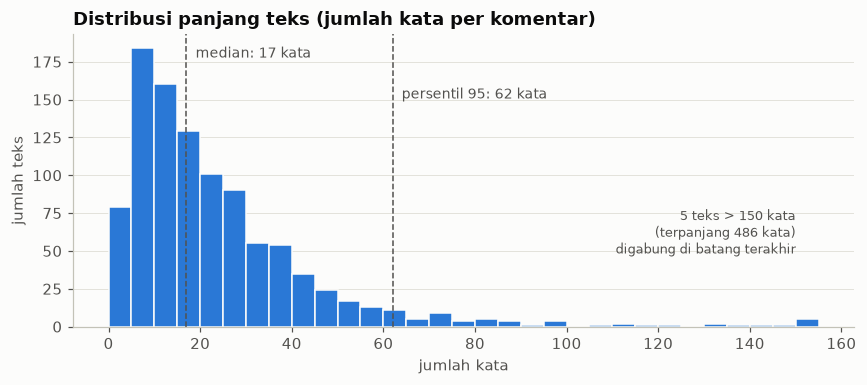

In [45]:
ringkas = df[["n_char", "n_kata"]].describe(percentiles=[.25, .5, .75, .95]).T
ringkas.index = ["jumlah karakter", "jumlah kata"]
display(ringkas.round(1))
print(f"jumlah teks: {len(df):,} | teks ≤ 3 kata: {(df['n_kata'] <= 3).sum()} | teks > 100 kata: {(df['n_kata'] > 100).sum()}")

BATAS_X = 150                                   # ekor panjang dipotong supaya bentuk distribusi terlihat
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(df["n_kata"].clip(upper=BATAS_X), bins=np.arange(0, BATAS_X + 6, 5),
        color=WARNA["utama"], edgecolor=WARNA["latar"], linewidth=1)
for q, nama, tinggi in [(0.5, "median", 0.92), (0.95, "persentil 95", 0.78)]:
    v = df["n_kata"].quantile(q)
    ax.axvline(v, color=WARNA["teks2"], linewidth=1, linestyle="--")
    ax.text(v + 2, ax.get_ylim()[1] * tinggi, f"{nama}: {v:.0f} kata", color=WARNA["teks2"], fontsize=9)
n_lebih = (df["n_kata"] > BATAS_X).sum()
ax.text(BATAS_X, ax.get_ylim()[1] * 0.25, f"{n_lebih} teks > {BATAS_X} kata\n(terpanjang {df['n_kata'].max()} kata)\ndigabung di batang terakhir",
        ha="right", color=WARNA["teks2"], fontsize=8.5)
ax.set_title("Distribusi panjang teks (jumlah kata per komentar)")
ax.set_xlabel("jumlah kata")
ax.set_ylabel("jumlah teks")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Penjelasan M1:** gold dataset berisi **999 teks**. Komentar umumnya pendek: median **17 kata** (109 karakter) dan 95% teks tidak lebih dari **62 kata**. Distribusinya miring ke kanan dengan ekor panjang, 15 teks lebih dari 100 kata dan yang terpanjang 486 kata. Ada 47 teks yang sangat pendek (≤ 3 kata), tetapi sengaja dipertahankan saat cleaning karena justru sering memuat serangan yang jelas (contoh: `Otak gada isinya`).

## M2 = Distribusi setiap label
Jumlah dan persentase teks yang memiliki setiap label. Karena multilabel, satu teks bisa dihitung di lebih dari satu label, sehingga totalnya lebih dari 999.

,jumlah teks,% teks,tidak berlabel ini
INSULTING,364,36.4,635
ACCUSING,370,37.0,629
MOCKING,332,33.2,667
PROVOKING,168,16.8,831
CURSING,7,0.7,992
NONE,181,18.1,818


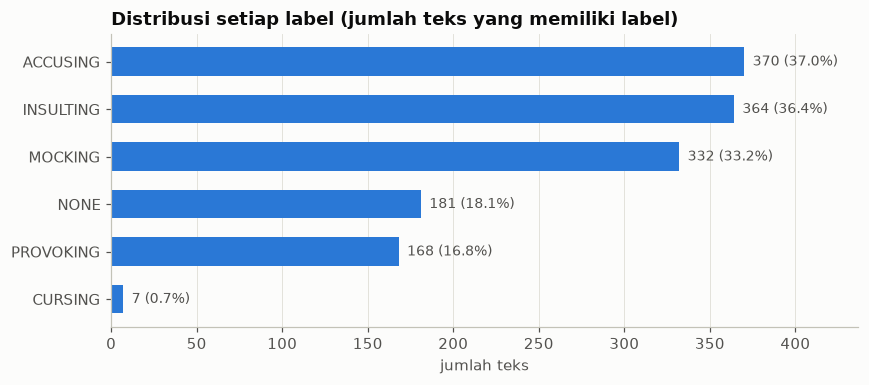

In [46]:
dist = pd.DataFrame({"jumlah teks": Y.sum(), "% teks": (Y.mean() * 100).round(1)})
dist["tidak berlabel ini"] = len(Y) - dist["jumlah teks"]
display(dist)

urut = dist.sort_values("jumlah teks")              # terbanyak di atas pada bar horizontal
fig, ax = plt.subplots(figsize=(8, 3.6))
bar = ax.barh(urut.index, urut["jumlah teks"], color=WARNA["utama"], height=0.6)
for b, (n, p) in zip(bar, zip(urut["jumlah teks"], urut["% teks"])):
    ax.text(b.get_width() + 5, b.get_y() + b.get_height() / 2, f"{n} ({p:.1f}%)",
            va="center", color=WARNA["teks2"], fontsize=9)
ax.set_title("Distribusi setiap label (jumlah teks yang memiliki label)")
ax.set_xlabel("jumlah teks")
ax.set_xlim(0, urut["jumlah teks"].max() * 1.18)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Penjelasan M2:** label dibagi menjadi tiga kelompok. **ACCUSING, INSULTING, dan MOCKING** masing-masing muncul di sekitar sepertiga teks (332–370 teks). **PROVOKING (168)** dan **NONE (181)** berada di tengah, masih memadai. **CURSING hanya 7 teks (0,7%)**: terlalu sedikit untuk dilatih sebagai kelas sendiri dan hampir pasti tidak muncul di data uji dalam jumlah berarti. ini sumber imbalance terbesar.

## M3 = Jumlah label per teks
Berapa banyak label yang dimiliki satu teks, ditambah dua ukuran standar multilabel: **label cardinality** (rata-rata label per teks) dan **label density** (cardinality dibagi jumlah label), serta kombinasi label yang paling sering muncul.

,jumlah teks,% teks
label per teks,,
1,646,64.7
2,286,28.6
3,64,6.4
4,3,0.3


label cardinality (rata-rata label per teks): 1.42
label density (cardinality / jumlah label): 0.237
teks multilabel (≥ 2 label): 353 (35.3%)


,jumlah teks
kombinasi label (10 terbanyak),
NONE,181
MOCKING,156
ACCUSING,145
INSULTING,119
INSULTING + ACCUSING,74
ACCUSING + MOCKING,71
INSULTING + PROVOKING,55
INSULTING + MOCKING,53
PROVOKING,43


jumlah kombinasi unik: 21 | kombinasi yang hanya muncul 1 kali: 3


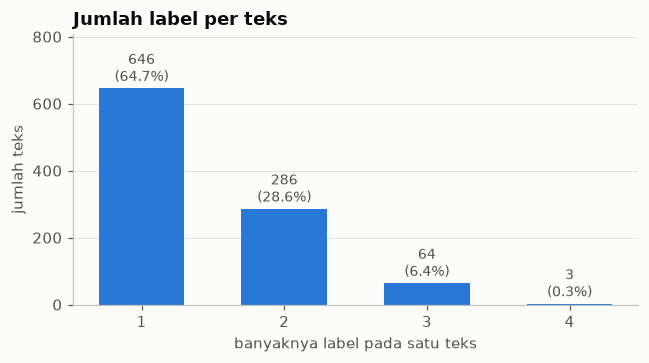

In [47]:
per_teks = df["n_label"].value_counts().sort_index()
tabel = pd.DataFrame({"jumlah teks": per_teks, "% teks": (per_teks / len(df) * 100).round(1)})
tabel.index.name = "label per teks"
display(tabel)
print(f"label cardinality (rata-rata label per teks): {df['n_label'].mean():.2f}")
print(f"label density (cardinality / jumlah label): {df['n_label'].mean() / len(LABELS):.3f}")
print(f"teks multilabel (≥ 2 label): {(df['n_label'] >= 2).sum()} ({(df['n_label'] >= 2).mean():.1%})")

kombinasi = df["labels"].map(lambda L: " + ".join(L)).value_counts()
display(kombinasi.head(10).rename("jumlah teks").to_frame().rename_axis("kombinasi label (10 terbanyak)"))
print(f"jumlah kombinasi unik: {len(kombinasi)} | kombinasi yang hanya muncul 1 kali: {(kombinasi == 1).sum()}")

fig, ax = plt.subplots(figsize=(6, 3.4))
bar = ax.bar(tabel.index.astype(str), tabel["jumlah teks"], color=WARNA["utama"], width=0.6)
for b, (n, p) in zip(bar, zip(tabel["jumlah teks"], tabel["% teks"])):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 8, f"{n}\n({p:.1f}%)",
            ha="center", va="bottom", color=WARNA["teks2"], fontsize=9)
ax.set_title("Jumlah label per teks")
ax.set_xlabel("banyaknya label pada satu teks")
ax.set_ylabel("jumlah teks")
ax.set_ylim(0, tabel["jumlah teks"].max() * 1.25)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Penjelasan M3:** sebagian besar teks (64,7%) hanya punya satu label, tetapi **35,3% teks multilabel** cukup besar sehingga tugas ini memang harus dimodelkan sebagai multilabel, bukan multikelas. Rata-rata 1,42 label per teks (density 0,237). Teks dengan 3–4 label jarang (6,7%). Dari 21 kombinasi label yang muncul, 3 hanya muncul sekali; karena itu pendekatan yang memperlakukan setiap kombinasi sebagai satu kelas (*label powerset*) kurang cocok, dan lebih aman memprediksi tiap label secara terpisah.

## M4 = Label co-occurrence
Matriks co-occurrence menghitung berapa teks yang memiliki dua label sekaligus. Diagonalnya sama dengan jumlah teks per label (M2). Panel kanan menormalkan per baris: dari teks berlabel A, berapa persen yang juga berlabel B.

,INSULTING,ACCUSING,MOCKING,PROVOKING,CURSING,NONE
label,,,,,,
INSULTING,364,130,89,91,1,0
ACCUSING,130,370,104,50,4,0
MOCKING,89,104,332,25,1,0
PROVOKING,91,50,25,168,1,0
CURSING,1,4,1,1,7,0
NONE,0,0,0,0,0,181


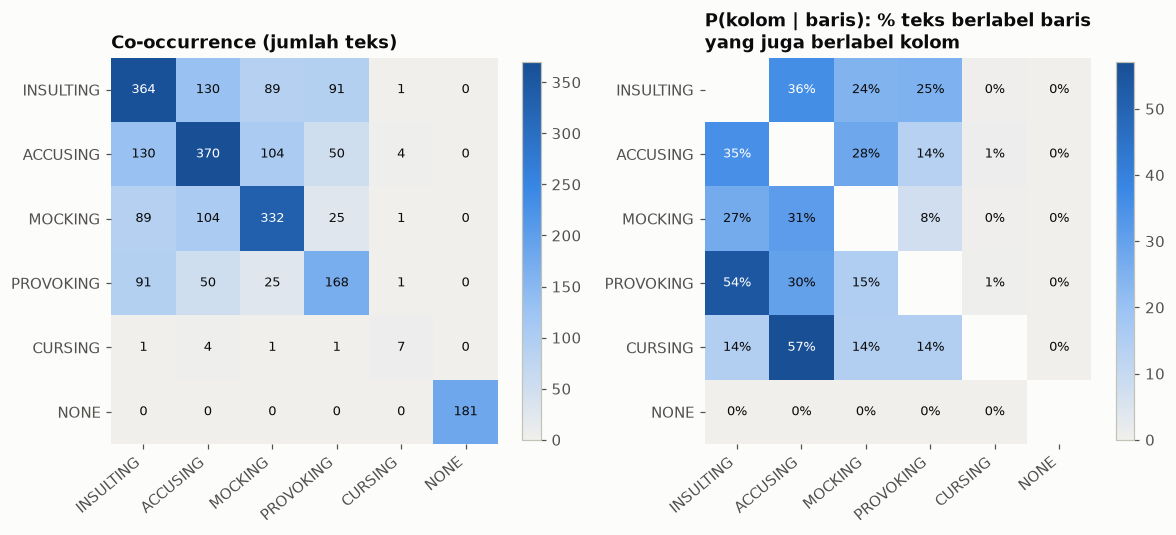

,label A,label B,teks bersama
0,INSULTING,ACCUSING,130
1,ACCUSING,MOCKING,104
2,INSULTING,PROVOKING,91
3,INSULTING,MOCKING,89
4,ACCUSING,PROVOKING,50
5,MOCKING,PROVOKING,25
6,ACCUSING,CURSING,4
7,INSULTING,CURSING,1
8,MOCKING,CURSING,1
9,PROVOKING,CURSING,1


In [48]:
cooc = Y.T @ Y                                       # sel (A, B) = jumlah teks yang berlabel A sekaligus B
display(cooc.rename_axis("label"))
# peluang bersyarat: dari teks berlabel A (baris), berapa % yang juga berlabel B (kolom)
kondisional = (cooc.div(np.diag(cooc), axis=0) * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, mat, judul, fmt in [
    (axes[0], cooc, "Co-occurrence (jumlah teks)", "{:.0f}"),
    (axes[1], kondisional, "P(kolom | baris): % teks berlabel baris\nyang juga berlabel kolom", "{:.0f}%"),
]:
    data = mat.to_numpy(dtype=float).copy()
    if ax is axes[1]:
        np.fill_diagonal(data, np.nan)                # diagonal = 100%, tidak informatif
    im = ax.imshow(data, cmap=PETA_BIRU, vmin=0)
    ax.set_xticks(range(len(LABELS)), LABELS, rotation=40, ha="right")
    ax.set_yticks(range(len(LABELS)), LABELS)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    batas_gelap = np.nanmax(data) * 0.6
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            v = data[i, j]
            if np.isnan(v):
                continue
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if v > batas_gelap else WARNA["teks"])
    ax.set_title(judul)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

pasangan = [(a, b, int(cooc.loc[a, b])) for i, a in enumerate(ATT) for b in ATT[i + 1:]]
display(pd.DataFrame(pasangan, columns=["label A", "label B", "teks bersama"])
        .sort_values("teks bersama", ascending=False).reset_index(drop=True))

**Penjelasan M4:** pasangan yang paling sering muncul bersama adalah **INSULTING + ACCUSING (130 teks)**, **ACCUSING + MOCKING (104)**, **INSULTING + PROVOKING (91)**, dan **INSULTING + MOCKING (89)**. Dari panel kanan: **54% teks PROVOKING juga INSULTING** — ajakan membubarkan/mengganti KPAI biasanya disertai hinaan; sebaliknya hanya 8% MOCKING disertai PROVOKING. 4 dari 7 teks CURSING juga ACCUSING. **NONE tidak pernah muncul bersama label lain (semua 0)**, sesuai aturan guideline bahwa NONE harus berdiri sendiri.

## M5 = Correlation matrix antarlabel
Korelasi Pearson pada dua variabel biner (0/1) disebut **koefisien phi (φ)**: +1 berarti dua label selalu muncul bersama, 0 berarti tidak terkait (muncul bersama sesering yang diharapkan secara kebetulan), −1 berarti tidak pernah bersama. Berbeda dengan co-occurrence, phi sudah memperhitungkan seberapa sering masing-masing label muncul.

,INSULTING,ACCUSING,MOCKING,PROVOKING,CURSING,NONE
INSULTING,1.00,-0.02,-0.14,0.17,-0.04,-0.36
ACCUSING,-0.02,1.00,-0.08,-0.07,0.03,-0.36
MOCKING,-0.14,-0.08,1.00,-0.18,-0.03,-0.33
PROVOKING,0.17,-0.07,-0.18,1.00,-0.01,-0.21
CURSING,-0.04,0.03,-0.03,-0.01,1.00,-0.04
NONE,-0.36,-0.36,-0.33,-0.21,-0.04,1.00


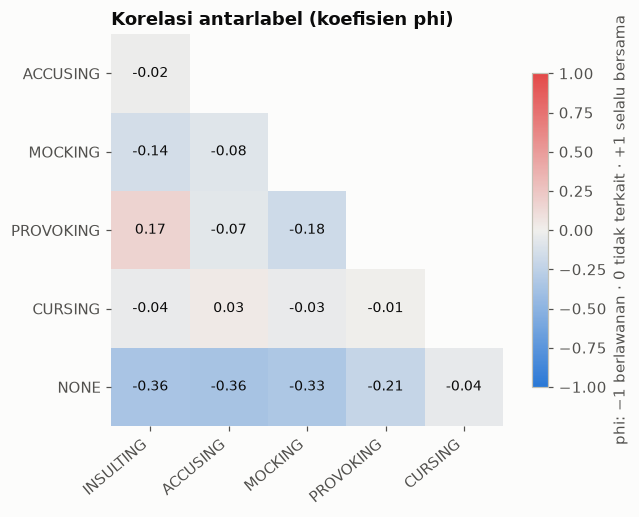

,label A,label B,phi
0,MOCKING,PROVOKING,-0.175
1,INSULTING,PROVOKING,0.166
2,INSULTING,MOCKING,-0.141
3,ACCUSING,MOCKING,-0.083
4,ACCUSING,PROVOKING,-0.068
5,INSULTING,CURSING,-0.039
6,ACCUSING,CURSING,0.035
7,MOCKING,CURSING,-0.034
8,INSULTING,ACCUSING,-0.021
9,PROVOKING,CURSING,-0.006


In [49]:
korelasi = Y.corr()                                   # Pearson pada data biner = koefisien phi
display(korelasi.round(2))

# matriks simetris -> cukup segitiga bawah: baris label ke-2 dst, kolom label ke-1 s.d. ke-5
baris_l, kolom_l = LABELS[1:], LABELS[:-1]
data = korelasi.loc[baris_l, kolom_l].to_numpy()
data = np.where(np.tril(np.ones_like(data, dtype=bool)), data, np.nan)

fig, ax = plt.subplots(figsize=(6.4, 4.8))
im = ax.imshow(data, cmap=PETA_DIVERGEN, vmin=-1, vmax=1)
ax.set_xticks(range(len(kolom_l)), kolom_l, rotation=40, ha="right")
ax.set_yticks(range(len(baris_l)), baris_l)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(baris_l)):
    for j in range(i + 1):
        v = data[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="#ffffff" if abs(v) > 0.55 else WARNA["teks"])
ax.set_title("Korelasi antarlabel (koefisien phi)")
fig.colorbar(im, ax=ax, shrink=0.8, label="phi: −1 berlawanan · 0 tidak terkait · +1 selalu bersama")
plt.tight_layout()
plt.show()

# pasangan label serangan, diurutkan dari korelasi terkuat (positif atau negatif)
pas = [(a, b, korelasi.loc[a, b]) for i, a in enumerate(ATT) for b in ATT[i + 1:]]
display(pd.DataFrame(pas, columns=["label A", "label B", "phi"]).sort_values("phi", key=abs, ascending=False)
        .round(3).reset_index(drop=True))

**Penjelasan M5:** semua korelasi antarlabel serangan **lemah (|φ| ≤ 0,18)**. Yang paling jelas hanya **INSULTING–PROVOKING (+0,17)**, sejalan dengan M4. Contoh penting: INSULTING dan ACCUSING muncul bersama di 130 teks (M4), tetapi φ ≈ −0,02 yang artinya keduanya muncul bersama **sesering yang diharapkan secara kebetulan** karena sama-sama sering, bukan karena saling terkait. MOCKING cenderung sedikit terpisah dari PROVOKING (−0,18) dan INSULTING (−0,14): ejekan biasanya tidak disertai ajakan langsung. **NONE berkorelasi negatif dengan semua label** (hingga −0,36) karena secara aturan tidak pernah digabung. Korelasi CURSING tidak bisa ditafsirkan karena hanya 7 teks.

## M6 = Analisis imbalance ratio
Analisis dibagi empat bagian: **A** karakteristik umum dataset, **B** ketidakseimbangan label, **C** kombinasi label, dan **D** hubungan imbalance dengan panjang teks.

### A. Karakteristik umum dataset
Ringkasan ukuran dasar dataset multilabel (rinciannya ada di M1–M3).

In [50]:
kombinasi = df["labels"].map(lambda L: " + ".join(L)).value_counts()
umum = pd.Series({
    "jumlah teks": f"{len(df):,}",
    "jumlah label (5 serangan + NONE)": len(LABELS),
    "label yang benar-benar muncul": int((Y.sum() > 0).sum()),
    "label cardinality (rata-rata label per teks)": f"{df['n_label'].mean():.2f}",
    "label density (cardinality / jumlah label)": f"{df['n_label'].mean() / len(LABELS):.3f}",
    "teks multilabel (≥ 2 label)": f"{(df['n_label'] >= 2).sum()} ({(df['n_label'] >= 2).mean():.1%})",
    "kombinasi label unik": len(kombinasi),
}, name="nilai")
display(umum.to_frame())

,nilai
jumlah teks,999
jumlah label (5 serangan + NONE),6
label yang benar-benar muncul,6
label cardinality (rata-rata label per teks),1.42
label density (cardinality / jumlah label),0.237
teks multilabel (≥ 2 label),353 (35.3%)
kombinasi label unik,21


### B. Analisis ketidakseimbangan label
Ukuran imbalance untuk data multilabel menggunakan referensi dari Charte dkk., 2015:
- **IRLbl** (imbalance ratio per label) = jumlah teks label terbanyak ÷ jumlah teks label itu. Nilai 1 = label paling umum; makin besar makin langka.
- **MeanIR** = rata-rata IRLbl. Label dengan IRLbl > MeanIR dianggap **minoritas**.
- **CVIR** = koefisien variasi IRLbl; makin besar, makin timpang perbedaan antarlabel.
- **Rasio negatif:positif** = untuk setiap teks berlabel X, ada berapa teks yang tidak berlabel X (penting karena tiap label dipelajari sebagai klasifikasi biner).

,positif,negatif,rasio negatif:positif,IRLbl,status
ACCUSING,370,629,1.7,1.00,cukup
INSULTING,364,635,1.7,1.02,cukup
MOCKING,332,667,2.0,1.11,cukup
NONE,181,818,4.5,2.04,cukup
PROVOKING,168,831,4.9,2.20,cukup
CURSING,7,992,141.7,52.86,minoritas (IRLbl > MeanIR)


imbalance ratio maks/min : 370 / 7 = 52.9
MeanIR = 10.04 | MaxIR = 52.86 | CVIR = 1.91
tanpa CURSING: maks/min = 370 / 168 = 2.20 | MeanIR = 1.48


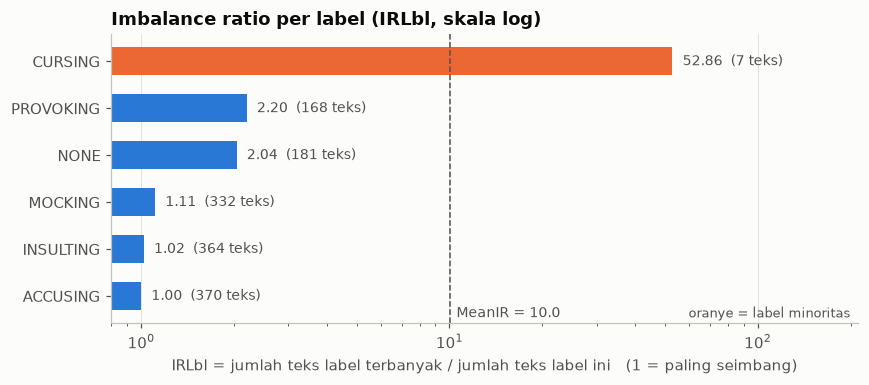

In [51]:
n_pos = Y.sum()
imb = pd.DataFrame({
    "positif": n_pos,
    "negatif": len(Y) - n_pos,
    "rasio negatif:positif": ((len(Y) - n_pos) / n_pos).round(1),
    "IRLbl": (n_pos.max() / n_pos).round(2),      # imbalance ratio per label = jumlah label terbanyak / jumlah label ini
})
mean_ir = imb["IRLbl"].mean()
cvir = imb["IRLbl"].std(ddof=0) / mean_ir
imb["status"] = np.where(imb["IRLbl"] > mean_ir, "minoritas (IRLbl > MeanIR)", "cukup")
display(imb.sort_values("IRLbl"))
print(f"imbalance ratio maks/min : {n_pos.max()} / {n_pos.min()} = {n_pos.max() / n_pos.min():.1f}")
print(f"MeanIR = {mean_ir:.2f} | MaxIR = {imb['IRLbl'].max():.2f} | CVIR = {cvir:.2f}")
tanpa = n_pos.drop("CURSING")
print(f"tanpa CURSING: maks/min = {tanpa.max()} / {tanpa.min()} = {tanpa.max() / tanpa.min():.2f} | "
      f"MeanIR = {(tanpa.max() / tanpa).mean():.2f}")

urut = imb.sort_values("IRLbl")
fig, ax = plt.subplots(figsize=(8, 3.6))
warna = [WARNA["kedua"] if s.startswith("minoritas") else WARNA["utama"] for s in urut["status"]]
bar = ax.barh(urut.index, urut["IRLbl"], color=warna, height=0.6)
ax.set_xscale("log")
ax.axvline(mean_ir, color=WARNA["teks2"], linestyle="--", linewidth=1)
ax.text(mean_ir * 1.05, -0.45, f"MeanIR = {mean_ir:.1f}", color=WARNA["teks2"], fontsize=9)
for b, v, n in zip(bar, urut["IRLbl"], urut["positif"]):
    ax.text(b.get_width() * 1.08, b.get_y() + b.get_height() / 2, f"{v:.2f}  ({n} teks)",
            va="center", color=WARNA["teks2"], fontsize=9)
ax.set_xlim(0.8, urut["IRLbl"].max() * 4)
ax.set_title("Imbalance ratio per label (IRLbl, skala log)")
ax.set_xlabel("IRLbl = jumlah teks label terbanyak / jumlah teks label ini   (1 = paling seimbang)")
ax.grid(axis="y", visible=False)
ax.text(0.99, 0.02, "oranye = label minoritas", transform=ax.transAxes, ha="right", color=WARNA["teks2"], fontsize=8.5)
plt.tight_layout()
plt.show()

**Penjelasan B:** imbalance seluruh dataset tampak tinggi (rasio maks/min **52,9**, MeanIR 10,0, CVIR 1,91), tetapi angka itu **hampir seluruhnya disebabkan oleh CURSING** (7 teks, IRLbl 52,9, rasio negatif:positif 142:1) satu-satunya label minoritas. Tanpa CURSING, kelima label lain **cukup seimbang**: rasio maks/min hanya **2,2** dan MeanIR 1,48. PROVOKING dan NONE (≈ 1 dari 5 teks) masih punya ±170 contoh positif, cukup untuk dilatih, tetapi rasio negatif:positif ≈ 5:1 sebaiknya diimbangi dengan bobot kelas atau penyesuaian threshold.

### C. Analisis kombinasi label
Heatmap co-occurrence dan matriks korelasi antarlabel sudah ditampilkan di **M4** dan **M5**. Bagian ini melihat **kombinasi** secara utuh: berapa kombinasi yang muncul, mana yang langka (≤ 5 teks), dan ukuran **SCUMBLE** (Charte dkk., 2019) — seberapa sering label langka muncul bersamaan dengan label umum dalam satu teks. Untuk satu teks, SCUMBLE = 1 − (rata-rata geometrik IRLbl ÷ rata-rata aritmetik IRLbl) dari label-labelnya; bernilai 0 bila semua labelnya sama umum. SCUMBLE dataset > 0,1 menandakan label langka sering "menempel" pada label umum, sehingga resampling sulit memperbaiki imbalance.

kombinasi unik: 21 | kombinasi langka (≤ 5 teks): 7 kombinasi, total 13 teks (1.3%)


,jumlah teks
kombinasi langka (≤ 5 teks),
ACCUSING + MOCKING + PROVOKING,3
INSULTING + ACCUSING + MOCKING + PROVOKING,3
ACCUSING + CURSING,2
CURSING,2
PROVOKING + CURSING,1
ACCUSING + MOCKING + CURSING,1
INSULTING + ACCUSING + CURSING,1


SCUMBLE dataset = 0.012  (patokan: > 0,1 = label langka sering menempel pada label umum)


,SCUMBLE rata-rata
INSULTING,0.020
ACCUSING,0.018
MOCKING,0.007
PROVOKING,0.054
CURSING,0.521
NONE,0.000


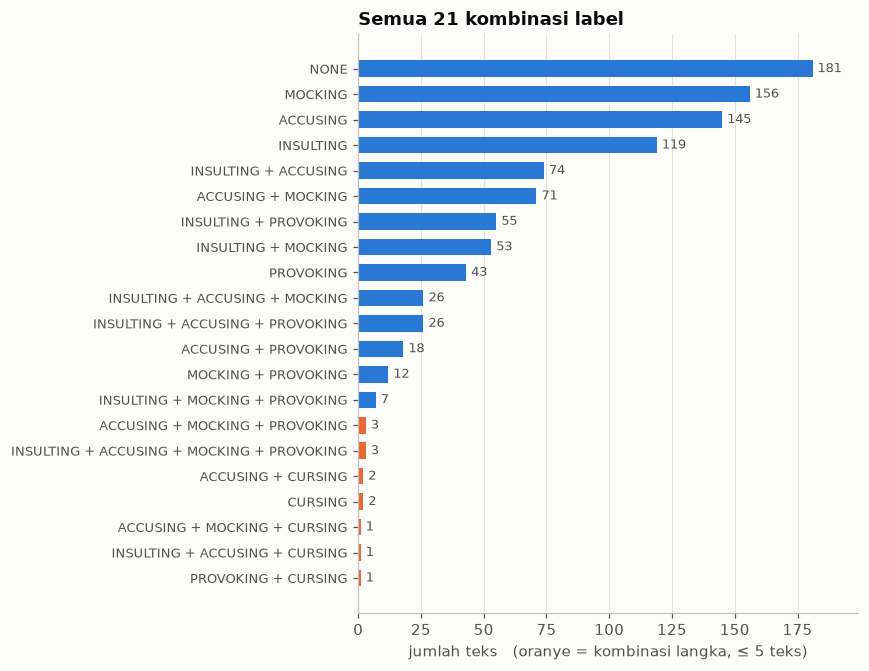

In [52]:
# ---------- kombinasi langka ----------
BATAS_LANGKA = 5
langka = kombinasi[kombinasi <= BATAS_LANGKA]
print(f"kombinasi unik: {len(kombinasi)} | kombinasi langka (≤ {BATAS_LANGKA} teks): {len(langka)} "
      f"kombinasi, total {langka.sum()} teks ({langka.sum() / len(df):.1%})")
display(langka.rename("jumlah teks").to_frame().rename_axis(f"kombinasi langka (≤ {BATAS_LANGKA} teks)"))

# ---------- SCUMBLE: seberapa sering label langka muncul bersama label umum ----------
irlbl = n_pos.max() / n_pos


def scumble_teks(labels):
    ir = irlbl[labels].to_numpy()
    if len(ir) < 2:
        return 0.0                                    # teks berlabel tunggal tidak punya konkurensi
    return 1 - np.exp(np.log(ir).mean()) / ir.mean()  # 1 − rata-rata geometrik / rata-rata aritmetik


df["scumble"] = df["labels"].map(scumble_teks)
scumble_label = pd.Series({l: df.loc[Y[l] == 1, "scumble"].mean() for l in LABELS}, name="SCUMBLE rata-rata")
print(f"SCUMBLE dataset = {df['scumble'].mean():.3f}  (patokan: > 0,1 = label langka sering menempel pada label umum)")
display(scumble_label.round(3).to_frame())

# ---------- grafik semua kombinasi ----------
urut = kombinasi.sort_values()
fig, ax = plt.subplots(figsize=(8, 6.2))
warna = [WARNA["kedua"] if n <= BATAS_LANGKA else WARNA["utama"] for n in urut]
bar = ax.barh(urut.index, urut.values, color=warna, height=0.65)
for b, n in zip(bar, urut.values):
    ax.text(b.get_width() + 2, b.get_y() + b.get_height() / 2, str(n), va="center", color=WARNA["teks2"], fontsize=8.5)
ax.set_title(f"Semua {len(kombinasi)} kombinasi label")
ax.set_xlabel(f"jumlah teks   (oranye = kombinasi langka, ≤ {BATAS_LANGKA} teks)")
ax.tick_params(axis="y", labelsize=8.5)
ax.set_xlim(0, urut.max() * 1.1)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Penjelasan C:** dari 21 kombinasi, 14 cukup sering (≥ 7 teks) dan **7 langka (≤ 5 teks, total hanya 13 teks / 1,3%)**. Lima dari tujuh kombinasi langka melibatkan **CURSING**; dua lainnya adalah kombinasi 3–4 label yang memuat PROVOKING. SCUMBLE dataset **0,012** (jauh di bawah 0,1): secara umum label yang muncul bersama memiliki tingkat kelangkaan yang mirip, sehingga dataset tidak sulit dari sisi konkurensi. Pengecualiannya **CURSING (SCUMBLE 0,52)**: 5 dari 7 teks CURSING juga berlabel umum (terutama ACCUSING). Artinya, menggandakan teks CURSING (*oversampling*) otomatis ikut menggandakan ACCUSING/INSULTING, sehingga resampling bukan solusi yang bersih untuk CURSING.

### D. Hubungan imbalance dengan karakteristik teks
Apakah label yang lebih jarang punya teks yang lebih pendek/panjang? Panjang teks (kata) dibandingkan per label dan menurut banyaknya label dalam satu teks.

,jumlah teks,rata-rata kata,Q1,median,Q3,maks,IRLbl
ACCUSING,370.0,28.8,13.0,23.0,36.0,486.0,1.00
INSULTING,364.0,25.0,10.0,18.0,32.0,486.0,1.02
MOCKING,332.0,24.9,10.0,18.0,30.0,486.0,1.11
NONE,181.0,27.2,9.0,18.0,35.0,168.0,2.04
PROVOKING,168.0,19.7,8.0,14.0,25.2,132.0,2.20
CURSING,7.0,19.3,12.5,16.0,27.0,35.0,52.86


,jumlah teks,rata-rata kata,median kata
label per teks,,,
1,646,21.8,15.0
2,286,23.9,20.0
3,64,40.7,28.5
4,3,72.7,63.0


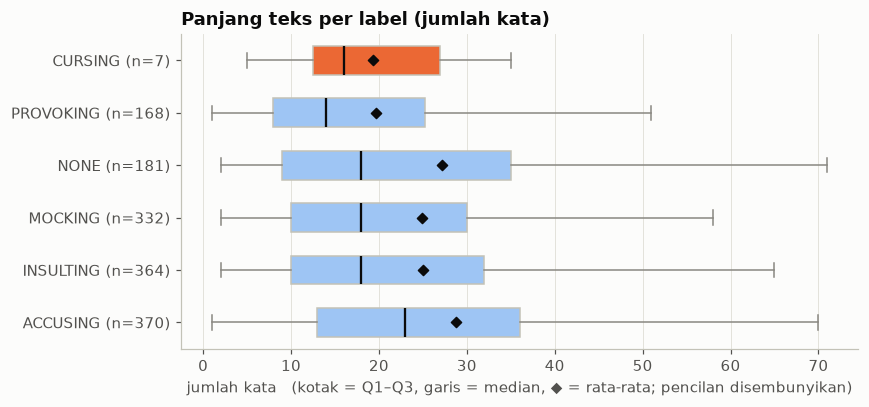

In [53]:
# panjang teks (kata) untuk teks yang memiliki setiap label
panjang_label = pd.DataFrame({
    l: df.loc[Y[l] == 1, "n_kata"].describe(percentiles=[.25, .5, .75])[["count", "mean", "25%", "50%", "75%", "max"]]
    for l in LABELS
}).T.round(1)
panjang_label.columns = ["jumlah teks", "rata-rata kata", "Q1", "median", "Q3", "maks"]
panjang_label["IRLbl"] = irlbl.round(2)
display(panjang_label.sort_values("IRLbl"))

# panjang teks menurut banyaknya label
display(df.groupby("n_label")["n_kata"].agg(["count", "mean", "median"]).round(1)
        .rename(columns={"count": "jumlah teks", "mean": "rata-rata kata", "median": "median kata"})
        .rename_axis("label per teks"))

urut_l = panjang_label.sort_values("IRLbl").index.tolist()
fig, ax = plt.subplots(figsize=(8, 3.8))
bp = ax.boxplot([df.loc[Y[l] == 1, "n_kata"] for l in urut_l], orientation="horizontal", widths=0.55,
                patch_artist=True, showfliers=False, medianprops={"color": WARNA["teks"], "linewidth": 1.5},
                whiskerprops={"color": WARNA["redup"]}, capprops={"color": WARNA["redup"]})
for kotak, l in zip(bp["boxes"], urut_l):
    kotak.set(facecolor=WARNA["kedua"] if l == "CURSING" else "#9ec5f4", edgecolor=WARNA["sumbu"])
ax.set_yticks(range(1, len(urut_l) + 1), [f"{l} (n={int(panjang_label.loc[l, 'jumlah teks'])})" for l in urut_l])
ax.scatter(panjang_label.loc[urut_l, "rata-rata kata"], range(1, len(urut_l) + 1), marker="D", s=22,
           color=WARNA["teks"], zorder=3)
ax.set_title("Panjang teks per label (jumlah kata)")
ax.set_xlabel("jumlah kata   (kotak = Q1–Q3, garis = median, ◆ = rata-rata; pencilan disembunyikan)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Penjelasan D:** **ACCUSING** punya teks terpanjang (median 23 kata) — menuduh biasanya disertai penjelasan perbuatan atau motif. **PROVOKING** paling pendek (median 14) karena banyak berupa seruan/slogan ("bubarkan KPAI", tagar). **NONE** sebarannya lebar (Q3 = 35 kata): kritik dan argumen pembelaan cenderung panjang. CURSING (median 16) tidak berbeda jelas, tetapi dengan 7 teks tidak bisa disimpulkan. Jadi **imbalance label tidak dijelaskan oleh panjang teks** — label langka tidak sistematis lebih pendek atau lebih panjang.

Yang jelas berhubungan adalah **banyaknya label**: median panjang naik dari 15 kata (1 label) menjadi 20 (2 label), 28,5 (3 label), dan 63 (4 label). Implikasinya, pemotongan teks panjang (*truncation*) saat pemodelan paling berisiko pada teks multilabel, karena bukti untuk label kedua/ketiga bisa ikut terpotong.

## N1 = Distribusi jumlah token per teks
Token yang dipakai adalah token Prodigy yang tersimpan di gold (`tokens`), yaitu unit yang diberi tag BIO. Sebagai pembanding dihitung juga jumlah token bila tanda baca dipisah dari kata, seperti tokenizer NER pada umumnya.

token Prodigy sama dengan pemisahan per spasi di 999 dari 999 teks
teks yang punya token dengan tanda baca menempel (mis. 'KPAI...!!!'): 814


,count,mean,std,min,25%,50%,75%,95%,99%,max
token Prodigy (dipakai di gold),999.0,23.7,26.4,1.0,9.0,17.0,30.0,62.0,122.2,486.0
token jika tanda baca dipisah,999.0,29.3,31.8,2.0,11.0,22.0,38.0,77.1,139.0,611.0


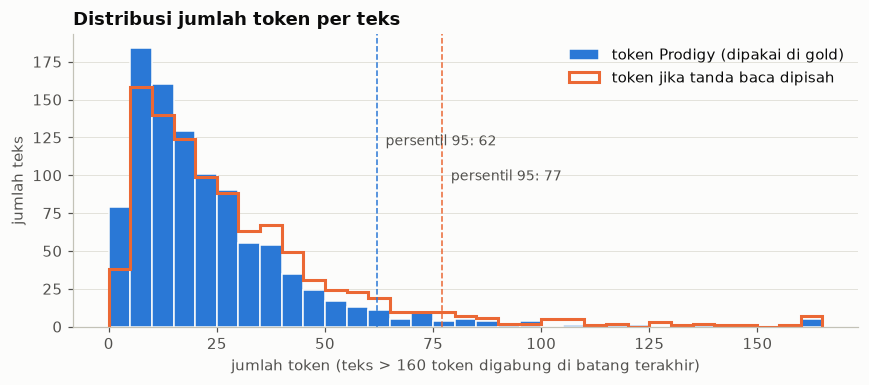

In [54]:
import re

# token Prodigy ternyata = pemisahan per spasi; pembanding: token bila tanda baca dipisah dari kata
df["n_token_pisah"] = df["text"].map(lambda t: len(re.findall(r"\w+|[^\w\s]", t)))
print("token Prodigy sama dengan pemisahan per spasi di", sum(g["tokens"] == g["text"].split() for g in gold), "dari", len(gold), "teks")
print("teks yang punya token dengan tanda baca menempel (mis. 'KPAI...!!!'):",
      sum(any(re.search(r"\w[^\w\s]+$", t) for t in g["tokens"]) for g in gold))

ringkas_tok = df[["n_token", "n_token_pisah"]].describe(percentiles=[.25, .5, .75, .95, .99]).T.round(1)
ringkas_tok.index = ["token Prodigy (dipakai di gold)", "token jika tanda baca dipisah"]
display(ringkas_tok)

BATAS_TOK = 160
batas = np.arange(0, BATAS_TOK + 6, 5)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(df["n_token"].clip(upper=BATAS_TOK), bins=batas, color=WARNA["utama"],
        edgecolor=WARNA["latar"], linewidth=1, label="token Prodigy (dipakai di gold)")
ax.hist(df["n_token_pisah"].clip(upper=BATAS_TOK), bins=batas, histtype="step", color=WARNA["kedua"],
        linewidth=2, label="token jika tanda baca dipisah")
for kolom, warna, tinggi in [("n_token", WARNA["utama"], 0.62), ("n_token_pisah", WARNA["kedua"], 0.50)]:
    v = df[kolom].quantile(0.95)
    ax.axvline(v, color=warna, linewidth=1, linestyle="--")
    ax.text(v + 2, ax.get_ylim()[1] * tinggi, f"persentil 95: {v:.0f}", color=WARNA["teks2"], fontsize=9)
ax.set_title("Distribusi jumlah token per teks")
ax.set_xlabel(f"jumlah token (teks > {BATAS_TOK} token digabung di batang terakhir)")
ax.set_ylabel("jumlah teks")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Penjelasan N1:** token Prodigy di gold dataset **identik dengan pemisahan per spasi** (999/999 teks), sehingga distribusinya sama dengan jumlah kata di M1: median **17 token**, 95% teks ≤ **62 token**, 99% ≤ 122 token, terpanjang 486. Akibatnya tanda baca menempel pada kata di **814 teks** (mis. token `KPAI...!!!`). Di gold, posisi karakter entitas sudah dipangkas (`[KPAI]`), tetapi tag BIO melekat pada token utuh `KPAI...!!!`. Bila tanda baca dipisah, jumlah token naik ±24% (median 22, persentil 95 = 77).

Implikasi pemodelan: (1) panjang maksimum input sekitar 128 token sudah mencakup >99% teks dengan tokenisasi Prodigy; untuk tokenizer subword (mis. IndoBERT) jumlah token akan lebih banyak lagi sehingga panjang maksimum perlu dicek ulang; (2) model NER sebaiknya dilatih dari **posisi karakter span** lalu disejajarkan ulang ke tokenizer model, bukan memakai token Prodigy apa adanya, agar tanda baca tidak ikut menjadi bagian entitas.

## N2 = Jumlah entity/span setiap jenis
Jumlah entitas per jenis, berapa teks yang memuat jenis itu, dan rata-rata kemunculannya di teks yang memuatnya.

,entitas,teks yang memuat,% entitas,% teks,rata-rata per teks yang memuat
jenis,,,,,
GOV_ORG,846,625,38.4,62.6,1.35
NONGOV_ORG,517,316,23.4,31.6,1.64
PERSON,67,50,3.0,5.0,1.34
GROUP,775,395,35.1,39.5,1.96


total entitas: 2,205 | rasio jenis terbanyak/tersedikit: 846 / 67 = 12.6


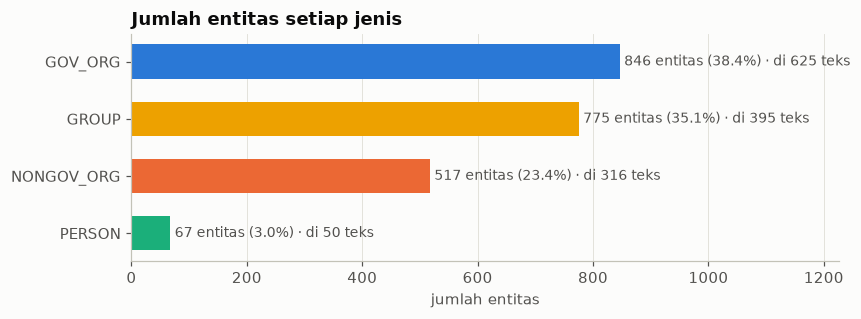

In [55]:
per_jenis = pd.DataFrame({
    "entitas": spans["label"].value_counts().reindex(ENT_TYPES),
    "teks yang memuat": spans.groupby("label")["id"].nunique().reindex(ENT_TYPES),
})
per_jenis["% entitas"] = (per_jenis["entitas"] / per_jenis["entitas"].sum() * 100).round(1)
per_jenis["% teks"] = (per_jenis["teks yang memuat"] / len(df) * 100).round(1)
per_jenis["rata-rata per teks yang memuat"] = (per_jenis["entitas"] / per_jenis["teks yang memuat"]).round(2)
per_jenis.index.name = "jenis"
display(per_jenis)
print(f"total entitas: {per_jenis['entitas'].sum():,} | "
      f"rasio jenis terbanyak/tersedikit: {per_jenis['entitas'].max()} / {per_jenis['entitas'].min()} = "
      f"{per_jenis['entitas'].max() / per_jenis['entitas'].min():.1f}")

urut = per_jenis.sort_values("entitas")
fig, ax = plt.subplots(figsize=(8, 3))
bar = ax.barh(urut.index, urut["entitas"], color=[WARNA_ENT[j] for j in urut.index], height=0.6)
for b, (n, p, t) in zip(bar, zip(urut["entitas"], urut["% entitas"], urut["teks yang memuat"])):
    ax.text(b.get_width() + 8, b.get_y() + b.get_height() / 2, f"{n} entitas ({p:.1f}%) · di {t} teks",
            va="center", color=WARNA["teks2"], fontsize=9)
ax.set_xlim(0, urut["entitas"].max() * 1.45)
ax.set_title("Jumlah entitas setiap jenis")
ax.set_xlabel("jumlah entitas")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Penjelasan N2:** dari 2.205 entitas, **GOV_ORG (846; 38,4%)** dan **GROUP (775; 35,1%)** mendominasi, disusul **NONGOV_ORG (517; 23,4%)**. GOV_ORG muncul di 62,6% teks — wajar karena hampir semua komentar menyebut KPAI. GROUP paling sering muncul berulang dalam satu teks (rata-rata 1,96 per teks yang memuatnya, mis. "anak" disebut beberapa kali). **PERSON hanya 67 entitas di 50 teks (3,0%)**: rasio jenis terbanyak/tersedikit **12,6**, sehingga PERSON adalah jenis entitas minoritas dan kemungkinan memiliki recall paling rendah saat pemodelan.

## N3 = Jumlah entity/span per teks
Sebaran banyaknya entitas dalam satu teks (teks dengan 10 entitas atau lebih digabung), termasuk teks tanpa entitas sama sekali, dan rata-rata per jenis.

entitas per teks,0,1,2,3,4,5,6,7,8,9,10+
jumlah teks,179.0,290.0,218.0,123.0,85.0,33.0,23.0,14.0,12.0,6.0,16.0
% teks,17.9,29.0,21.8,12.3,8.5,3.3,2.3,1.4,1.2,0.6,1.6


rata-rata entitas per teks: 2.21 | median: 2 | maks: 30 | teks tanpa entitas: 179 (17.9%)


label,GOV_ORG,NONGOV_ORG,PERSON,GROUP
mean,0.85,0.52,0.07,0.78
median,1.00,0.00,0.00,0.00
max,8.00,15.00,5.00,17.00


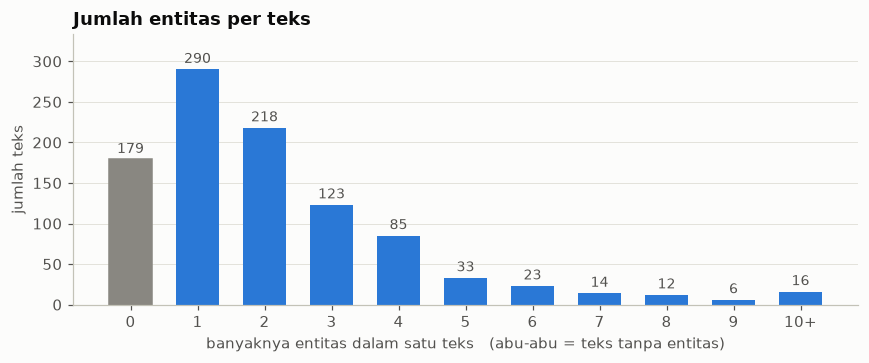

In [56]:
BATAS_ENT = 10
dist_ent = df["n_entitas"].clip(upper=BATAS_ENT).value_counts().sort_index()
tabel_ent = pd.DataFrame({"jumlah teks": dist_ent, "% teks": (dist_ent / len(df) * 100).round(1)})
tabel_ent.index = [f"{i}+" if i == BATAS_ENT else str(i) for i in tabel_ent.index]
tabel_ent.index.name = "entitas per teks"
display(tabel_ent.T)
print(f"rata-rata entitas per teks: {df['n_entitas'].mean():.2f} | median: {df['n_entitas'].median():.0f} | "
      f"maks: {df['n_entitas'].max()} | teks tanpa entitas: {(df['n_entitas'] == 0).sum()} ({(df['n_entitas'] == 0).mean():.1%})")

# rata-rata entitas per teks untuk tiap jenis (termasuk teks tanpa entitas jenis itu)
per_teks_jenis = (spans.groupby(["id", "label"]).size().unstack(fill_value=0)
                  .reindex(index=df.index, columns=ENT_TYPES, fill_value=0))
display(per_teks_jenis.describe().loc[["mean", "50%", "max"]].round(2).rename(index={"50%": "median"}))

fig, ax = plt.subplots(figsize=(8, 3.4))
bar = ax.bar(tabel_ent.index, tabel_ent["jumlah teks"], color=WARNA["utama"], width=0.65)
bar[0].set_color(WARNA["redup"])                   # teks tanpa entitas dibedakan
for b, n in zip(bar, tabel_ent["jumlah teks"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 4, f"{n}", ha="center", va="bottom",
            color=WARNA["teks2"], fontsize=9)
ax.set_title("Jumlah entitas per teks")
ax.set_xlabel("banyaknya entitas dalam satu teks   (abu-abu = teks tanpa entitas)")
ax.set_ylabel("jumlah teks")
ax.set_ylim(0, tabel_ent["jumlah teks"].max() * 1.15)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Penjelasan N3:** rata-rata **2,21 entitas per teks** (median 2). **179 teks (17,9%) tidak memuat entitas** — biasanya komentar dengan sasaran tersirat atau kata ganti ("dia", "mereka"), yang memang tidak ditag menurut guideline. Sebagian besar teks memuat 1–3 entitas (63,1%), dan ada ekor panjang hingga 30 entitas dalam satu komentar panjang. Per jenis, satu teks rata-rata memuat 0,85 GOV_ORG tetapi hanya 0,07 PERSON. Teks tanpa entitas tetap berguna untuk pelatihan NER sebagai contoh negatif (semua token `O`).

## N4 = Distribusi panjang entity/span
Panjang entitas diukur dalam **token** (dari tag BIO: 1 tag `B-` + jumlah tag `I-`) dan dalam **karakter**. Entitas lebih dari satu token menghasilkan tag `I-`, sehingga distribusi ini menentukan seberapa banyak contoh `I-` yang tersedia untuk model.

,entitas,token_rata,token_median,token_maks,karakter_rata,karakter_median,karakter_maks
label,,,,,,,
GOV_ORG,846,1.04,1.0,4,4.60,4.0,34
NONGOV_ORG,517,1.49,1.0,4,8.11,6.0,33
PERSON,67,1.64,2.0,3,8.99,8.0,20
GROUP,775,1.10,1.0,2,6.00,5.0,16
SEMUA,2205,1.19,1.0,4,6.05,5.0,34


,1 token,2 token,3 token,≥ 4 token,% multi-token
jenis,,,,,
GOV_ORG,820,19,3,4,3.1
NONGOV_ORG,284,218,10,5,45.1
PERSON,31,29,7,0,53.7
GROUP,696,79,0,0,10.2


entitas 1 token: 1831 (83.0%) | contoh entitas terpanjang: 'Komisi Nasional Perlindungan Anak' (4 token)


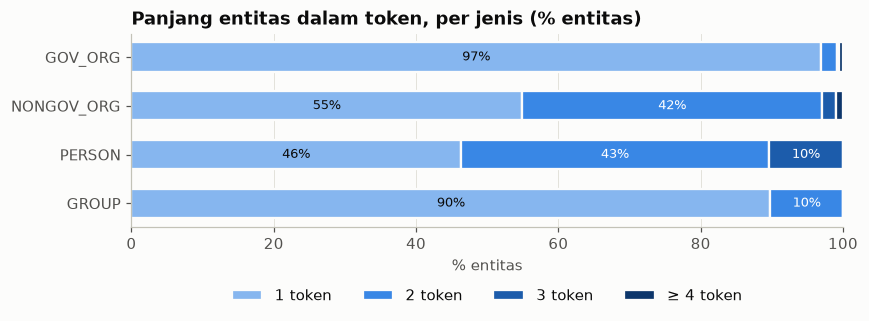

In [57]:
# statistik panjang entitas per jenis (token dan karakter)
pj = spans.groupby("label").agg(
    entitas=("n_token", "size"),
    token_rata=("n_token", "mean"), token_median=("n_token", "median"), token_maks=("n_token", "max"),
    karakter_rata=("n_char", "mean"), karakter_median=("n_char", "median"), karakter_maks=("n_char", "max"),
).reindex(ENT_TYPES).round(2)
pj.loc["SEMUA"] = [len(spans), spans["n_token"].mean(), spans["n_token"].median(), spans["n_token"].max(),
                   spans["n_char"].mean(), spans["n_char"].median(), spans["n_char"].max()]
display(pj.round(2))

# sebaran panjang dalam token: 1, 2, 3, 4+
kelas_panjang = spans["n_token"].clip(upper=4).map({1: "1 token", 2: "2 token", 3: "3 token", 4: "≥ 4 token"})
URUT_PANJANG = ["1 token", "2 token", "3 token", "≥ 4 token"]
sebaran = pd.crosstab(spans["label"], kelas_panjang).reindex(index=ENT_TYPES, columns=URUT_PANJANG, fill_value=0)
sebaran.columns.name, sebaran.index.name = None, "jenis"
persen = (sebaran.div(sebaran.sum(axis=1), axis=0) * 100).round(1)
display(sebaran.assign(**{"% multi-token": (100 - persen["1 token"]).round(1)}))
print(f"entitas 1 token: {(spans['n_token'] == 1).sum()} ({(spans['n_token'] == 1).mean():.1%}) | "
      f"contoh entitas terpanjang: {spans.loc[spans['n_token'].idxmax(), 'text']!r} ({spans['n_token'].max()} token)")

fig, ax = plt.subplots(figsize=(8, 3.2))
warna_panjang = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]       # biru terang -> gelap = makin panjang
kiri = np.zeros(len(ENT_TYPES))
for kolom, w in zip(URUT_PANJANG, warna_panjang):
    nilai = persen.loc[ENT_TYPES[::-1], kolom].to_numpy()
    ax.barh(ENT_TYPES[::-1], nilai, left=kiri, color=w, edgecolor=WARNA["latar"], linewidth=1.5, height=0.6, label=kolom)
    for y, (k, v) in enumerate(zip(kiri, nilai)):
        if v >= 6:
            ax.text(k + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if w != "#86b6ef" else WARNA["teks"])
    kiri += nilai
ax.set_xlim(0, 100)
ax.set_title("Panjang entitas dalam token, per jenis (% entitas)")
ax.set_xlabel("% entitas")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Penjelasan N4:** entitas umumnya sangat pendek, **83% hanya 1 token** (rata-rata 1,19 token, 6 karakter). Polanya berbeda per jenis: **GOV_ORG hampir selalu 1 token** (97%, didominasi "KPAI"), GROUP 90% 1 token (pengecualian utama "orang tua"), sedangkan **NONGOV_ORG (45%) dan PERSON (54%) sering multi-token** ("PB Djarum", "Djarum Foundation", "Pak Jokowi"). Entitas terpanjang hanya 4 token (mis. "Komisi Nasional Perlindungan Anak"). Akibatnya, contoh tag `I-` untuk GOV_ORG sangat sedikit, dan model harus belajar batas entitas terutama dari NONGOV_ORG dan PERSON.

## N5 = Contoh entity/span yang paling sering muncul
Teks entitas disatukan dalam huruf kecil ("KPAI", "kpai", "Kpai" dihitung sama). Selain daftar teratas per jenis, dihitung juga **keragaman**: berapa bentuk unik, berapa persen entitas yang tertutup oleh 1 dan 5 bentuk teratas, dan berapa bentuk yang hanya muncul sekali.

,entitas,bentuk unik,% oleh 1 bentuk teratas,% oleh 5 bentuk teratas,bentuk yang muncul 1 kali
label,,,,,
GOV_ORG,846,35,89.1,96.2,28
NONGOV_ORG,517,66,38.3,80.1,41
PERSON,67,43,10.4,32.8,31
GROUP,775,109,29.8,67.0,70


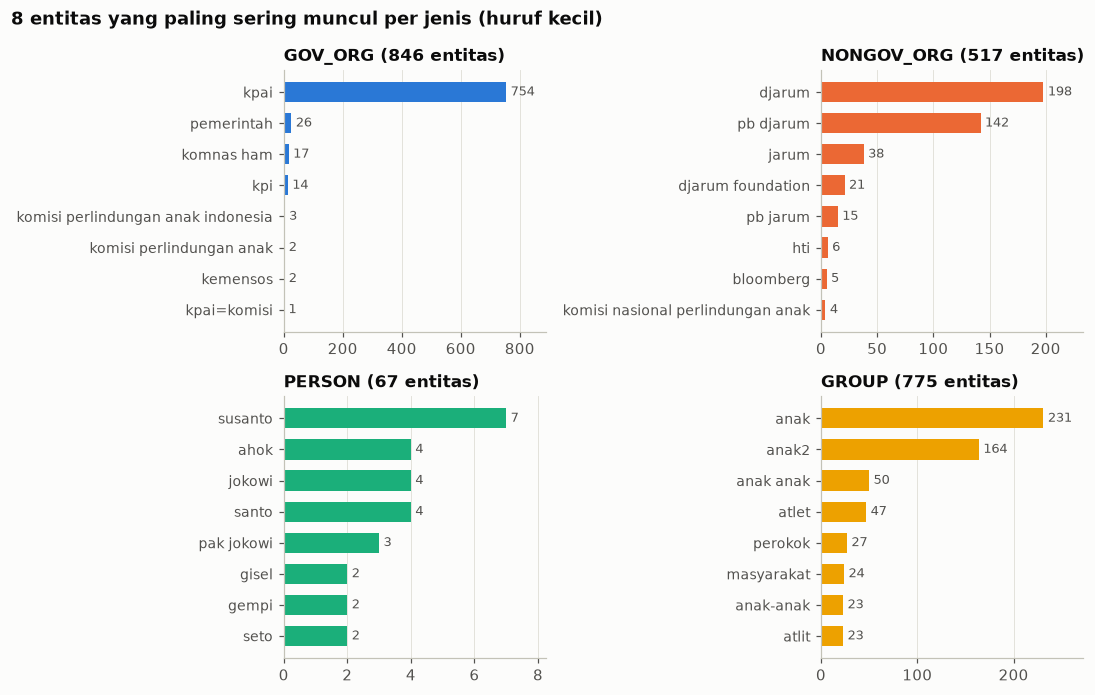

varian penulisan yang memuat 'kpai': 12 bentuk → KPAI (591), kpai (140), Kpai (20), KPAi (2), KPAI=komisi (1), KPAI#HAK (1), KPAIIIII (1), KPAI-nya (1)
varian penulisan yang memuat 'djarum': 32 bentuk → Djarum (117), PB Djarum (99), djarum (74), pb djarum (20), Djarum Foundation (17), PB DJARUM (12), PB djarum (8), DJARUM (7)


In [58]:
spans["bentuk"] = spans["text"].str.lower()          # ejaan disatukan: "KPAI", "kpai", "Kpai" dihitung sama

ringkas_bentuk = pd.DataFrame({
    "entitas": spans.groupby("label").size(),
    "bentuk unik": spans.groupby("label")["bentuk"].nunique(),
}).reindex(ENT_TYPES)
ringkas_bentuk["% oleh 1 bentuk teratas"] = [
    round(spans.loc[spans["label"] == j, "bentuk"].value_counts().iloc[0] / ringkas_bentuk.loc[j, "entitas"] * 100, 1)
    for j in ENT_TYPES]
ringkas_bentuk["% oleh 5 bentuk teratas"] = [
    round(spans.loc[spans["label"] == j, "bentuk"].value_counts().head(5).sum() / ringkas_bentuk.loc[j, "entitas"] * 100, 1)
    for j in ENT_TYPES]
ringkas_bentuk["bentuk yang muncul 1 kali"] = [
    int((spans.loc[spans["label"] == j, "bentuk"].value_counts() == 1).sum()) for j in ENT_TYPES]
display(ringkas_bentuk)

TOP = 8
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4))
for ax, jenis in zip(axes.ravel(), ENT_TYPES):
    top = spans.loc[spans["label"] == jenis, "bentuk"].value_counts().head(TOP).iloc[::-1]
    bar = ax.barh(top.index, top.values, color=WARNA_ENT[jenis], height=0.65)
    for b, n in zip(bar, top.values):
        ax.text(b.get_width() + top.max() * 0.02, b.get_y() + b.get_height() / 2, str(n), va="center",
                color=WARNA["teks2"], fontsize=8.5)
    ax.set_xlim(0, top.max() * 1.18)
    ax.set_title(f"{jenis} ({ringkas_bentuk.loc[jenis, 'entitas']} entitas)", fontsize=11)
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"{TOP} entitas yang paling sering muncul per jenis (huruf kecil)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

# variasi ejaan entitas paling sering: contoh KPAI dan PB Djarum
for kata in ["kpai", "djarum"]:
    varian = spans.loc[spans["bentuk"].str.contains(kata), "text"].value_counts()
    print(f"varian penulisan yang memuat '{kata}': {len(varian)} bentuk →", ", ".join(f"{t} ({n})" for t, n in varian.head(8).items()))

**Penjelasan N5:** keragaman entitas sangat berbeda per jenis. **GOV_ORG hampir seluruhnya "KPAI"** (89%; 5 bentuk teratas menutup 96%) — mudah dikenali, tetapi model berisiko hanya menghafal satu kata dan gagal pada lembaga lain (Komnas HAM, KPI, Kemensos). **NONGOV_ORG** didominasi varian Djarum ("djarum", "pb djarum", "jarum", "djarum foundation"). **GROUP** didominasi varian "anak" (anak, anak2, anak anak, anak-anak) dengan ekor panjang 70 bentuk yang muncul sekali. **PERSON paling beragam dan paling sedikit**: 43 bentuk dari 67 entitas, 31 muncul hanya sekali (Susanto, Jokowi, Ahok, Gisel, …) — model harus mengenali nama baru dari konteks, bukan dari hafalan.

Variasi ejaan tinggi: "KPAI" muncul dalam 12 bentuk dan "Djarum" dalam 32 bentuk (termasuk "jarum", huruf kapital acak, dan token menempel seperti "KPAI=komisi"). Model NER perlu tahan terhadap variasi huruf besar-kecil dan salah ketik.

## N6 = Analisis dominasi label O dan imbalance entity
Distribusi tag BIO di tingkat token. Model NER belajar per token, sehingga imbalance yang relevan adalah perbandingan token `O` dengan token entitas, dan antartag `B-`/`I-` per jenis.

,token,% token,rasio O : tag ini
tag,,,
O,21107,88.97,1.0
B-GOV_ORG,846,3.57,24.9
I-GOV_ORG,37,0.16,570.5
B-NONGOV_ORG,517,2.18,40.8
I-NONGOV_ORG,253,1.07,83.4
B-PERSON,67,0.28,315.0
I-PERSON,43,0.18,490.9
B-GROUP,775,3.27,27.2
I-GROUP,79,0.33,267.2


token O: 21,107 (89.0%) | token entitas (B+I): 2,617 (11.0%) | rasio O : entitas = 8.1 : 1
tag B: 2,205 | tag I: 412
teks yang seluruh tokennya O: 179 (17.9%)


,token entitas,% token entitas,imbalance ratio (terbanyak / jenis ini)
GOV_ORG,883,33.7,1.00
NONGOV_ORG,770,29.4,1.15
PERSON,110,4.2,8.03
GROUP,854,32.6,1.03


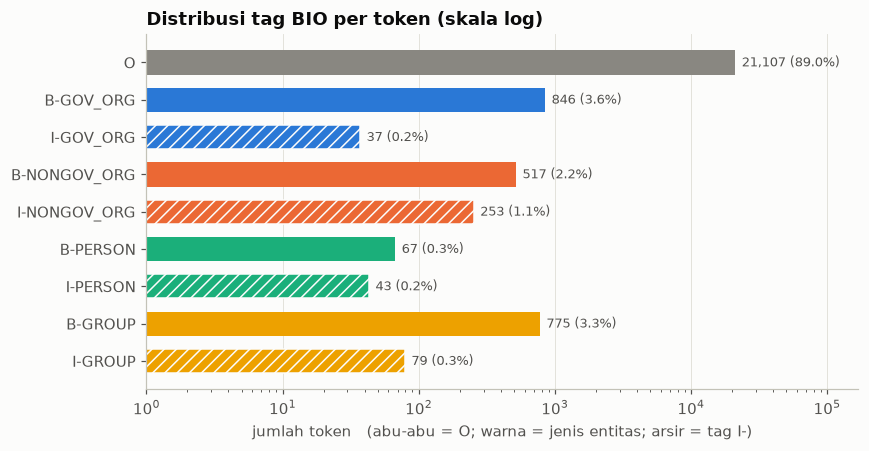

In [59]:
URUT_TAG = ["O"] + [f"{p}-{j}" for j in ENT_TYPES for p in ("B", "I")]
jumlah_tag = tags.value_counts().reindex(URUT_TAG, fill_value=0)
tabel_tag = pd.DataFrame({"token": jumlah_tag, "% token": (jumlah_tag / len(tags) * 100).round(2)})
tabel_tag["rasio O : tag ini"] = (jumlah_tag["O"] / jumlah_tag).round(1)
display(tabel_tag)

n_o = jumlah_tag["O"]
n_ent = len(tags) - n_o
print(f"token O: {n_o:,} ({n_o / len(tags):.1%}) | token entitas (B+I): {n_ent:,} ({n_ent / len(tags):.1%}) | rasio O : entitas = {n_o / n_ent:.1f} : 1")
print(f"tag B: {tags.str.startswith('B-').sum():,} | tag I: {tags.str.startswith('I-').sum():,}")
print(f"teks yang seluruh tokennya O: {(df['n_entitas'] == 0).sum()} ({(df['n_entitas'] == 0).mean():.1%})")

# token entitas per jenis (B + I) dan imbalance antarjenis
tok_jenis = pd.Series({j: jumlah_tag[f"B-{j}"] + jumlah_tag[f"I-{j}"] for j in ENT_TYPES}, name="token entitas")
imb_ent = pd.DataFrame({"token entitas": tok_jenis, "% token entitas": (tok_jenis / tok_jenis.sum() * 100).round(1),
                        "imbalance ratio (terbanyak / jenis ini)": (tok_jenis.max() / tok_jenis).round(2)})
display(imb_ent)

fig, ax = plt.subplots(figsize=(8, 4.2))
warna_tag = [WARNA["redup"]] + [WARNA_ENT[t.split("-", 1)[1]] for t in URUT_TAG[1:]]
bar = ax.barh(URUT_TAG[::-1], jumlah_tag[URUT_TAG[::-1]], color=warna_tag[::-1], height=0.65)
for b, t in zip(bar, URUT_TAG[::-1]):
    if t.startswith("I-"):
        b.set_hatch("///")
        b.set_edgecolor(WARNA["latar"])
    n = jumlah_tag[t]
    ax.text(b.get_width() * 1.12, b.get_y() + b.get_height() / 2, f"{n:,} ({n / len(tags):.1%})",
            va="center", color=WARNA["teks2"], fontsize=8.5)
ax.set_xscale("log")
ax.set_xlim(1, jumlah_tag.max() * 8)
ax.set_title("Distribusi tag BIO per token (skala log)")
ax.set_xlabel("jumlah token   (abu-abu = O; warna = jenis entitas; arsir = tag I-)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Penjelasan N6:** **89% token berlabel O**; token entitas hanya 11% (rasio O : entitas **8,1 : 1**). Ini dominasi O yang normal untuk NER, tetapi berarti akurasi per token tidak bermakna, model yang menebak O untuk semua token sudah mendapat akurasi 89%. Evaluasi harus memakai **precision/recall/F1 tingkat entitas** (mis. `seqeval`), bukan akurasi token.

Antarjenis, GOV_ORG, GROUP, dan NONGOV_ORG seimbang (imbalance ratio 1,00–1,15), sedangkan **PERSON minoritas** (110 token, imbalance ratio 8,0). Tag `I-` jauh lebih jarang dari `B-` (412 vs 2.205): **I-GOV_ORG hanya 37 token** dan **I-PERSON 43 token** (rasio O hingga 570 : 1), sehingga batas akhir entitas multi-kata pada jenis ini paling sulit dipelajari.

## Kesimpulan EDA
Pertanyaan spesifikasi 4.8: *apakah distribusi label cukup layak untuk pemodelan, dan di mana potensi imbalance berada?*

### Multilabel
- **Layak untuk 5 dari 6 label.** INSULTING, ACCUSING, MOCKING, PROVOKING, dan NONE masing-masing punya 168–370 teks positif; tanpa CURSING rasio terbanyak/tersedikit hanya 2,2 (MeanIR 1,48).
- **Tugas benar-benar multilabel**: 35,3% teks punya ≥ 2 label (cardinality 1,42), tetapi korelasi antarlabel lemah (|φ| ≤ 0,18) sehingga tiap label membawa informasi sendiri.
- **Imbalance utama: CURSING** (7 teks, IRLbl 52,9, SCUMBLE 0,52) — terlalu sedikit untuk dilatih dan dievaluasi sebagai label sendiri, serta hampir selalu menempel pada label umum.
- **NONE** tidak pernah muncul bersama label lain, sehingga dapat diturunkan dari "tidak ada serangan".
- Teks multilabel cenderung lebih panjang (median 15 → 63 kata dari 1 → 4 label); pemotongan input paling berisiko pada teks multilabel.

### NER
- **Layak untuk GOV_ORG, NONGOV_ORG, dan GROUP** (770–883 token entitas, seimbang satu sama lain).
- **Dominasi O** 89% token (8,1 : 1) — normal untuk NER, tetapi evaluasi wajib di tingkat entitas.
- **Imbalance utama: PERSON** (67 entitas / 110 token, imbalance ratio 8,0) dan **tag I-** (412 token; I-GOV_ORG 37, I-PERSON 43).
- GOV_ORG sangat homogen (89% "KPAI") sehingga berisiko dihafal; PERSON paling beragam (31 dari 43 bentuk muncul sekali).
- Token Prodigy = pemisahan per spasi dengan tanda baca menempel (814 teks); model sebaiknya dilatih dari posisi karakter span.

### Rencana untuk pemodelan (UAS)
| Aspek | Rencana |
|---|---|
| CURSING | Diputuskan tim: dilaporkan terpisah dan dikeluarkan dari rata-rata metrik utama, digabung ke label lain, atau dihapus dari target model |
| NONE | Diturunkan dari prediksi 5 label serangan (NONE = tidak ada yang terdeteksi) |
| Model multilabel | Satu output sigmoid per label (binary relevance): baseline TF-IDF + Logistic Regression, lalu IndoBERT |
| Split data | Iterative stratification; teks hampir-duplikat di split yang sama; k-fold karena data hanya 999 teks |
| Imbalance multilabel | `pos_weight` per label (≈ rasio negatif:positif 1,7–4,9) dan threshold per label dari data validasi |
| Model NER | Token classification BIO (CRF sebagai baseline, lalu IndoBERT) dengan label disejajarkan dari posisi karakter span |
| Imbalance NER | Perhatikan PERSON dan tag I-; pertimbangkan class weight atau augmentasi nama |
| Metrik | Multilabel: micro/macro-F1, F1 per label, Hamming loss. NER: precision/recall/F1 tingkat entitas per jenis (`seqeval`) |
| Panjang input | Cek ulang dengan tokenizer subword; ±128 token mencakup >99% teks pada tokenisasi Prodigy |
| Keterbatasan | Proporsi label berasal dari sampel yang diperkaya teks berindikasi serangan, bukan proporsi seluruh komentar |